# Comparative Performance Analysis of ResNet50, EfficientNetB0, and MobileNetV2 for Detecting Counterfeit Analog Watch Images

### Kaggle training and evaluation notebook for the revised Chapter 3 (Methodology)

**Thesis Adviser:** Jefferson A. Costales
**Prepared by:** Neil Andrew R. Mediavillo (`mobilenet_v2`), Gertie Anne C. Rabon (`efficientnet_b0`), Angela Ysabelle A. Sta. Maria (`resnet50`)

---

### How to read this notebook

Every section starts with a **Chapter 3 box** that lists, in this order: the chapter heading it implements, what the chapter requires, which functions implement it, which files it writes, the choices the chapter leaves open, and what code cannot check. Every code cell begins with a banner that names its notebook section and the Chapter 3 heading (`# CHAPTER 3: ...`). Section 13 tests the finished run against the chapter and writes `table_methodology_compliance.csv`.

**Tags** used next to configuration values and in the boxes:

| tag | meaning |
|---|---|
| `[CH3]` | the value or rule is stated in Chapter 3 |
| `[OURS]` | an implementation choice the chapter leaves open (all are listed in the register below) |
| `[OPT]` | a convenience switch that is not part of the methodology |

**Compliance statuses:** PASS (measured and matches), FAIL (measured and differs), REVIEW (needs your decision), BY DESIGN (enforced by the code path, not measured), NOT VERIFIABLE (needed data is missing), NOT RUN (stage switched off).

### Map: notebook section to Chapter 3

| # | Notebook section | Chapter 3 heading | Main outputs |
|---|---|---|---|
| 0 | Setup, configuration, reproducibility | Research Design | n/a |
| 1 | Dataset discovery, tracker, composition check | Data Gathering (Table 2) | `table_dataset_composition_raw.csv`, figure 01 |
| 2 | Quality gates, exact duplicates | Data Cleaning | `table_cleaning_log.csv`, `table_tracker_exclusions.csv`, figure 02 |
| 3 | rembg isolation, tight crop, square pad, 320 px area resize | Data Cleaning, Resizing | figure 03, `table_image_master_log.csv` |
| 4 | Near-duplicate groups, background tier, subsampling to the targets (4c) | Data Partitioning, Data Gathering, Data Cleaning step 7 | `table_pool_test_overlap.csv`, `table_watermark_rate.csv`, `table_removed_images_all.csv`, `table_subsample_*.csv`, figures 04, 04c, 04d |
| 5 | Fixed grouped folds and assertions | Data Partitioning | `fold_assignments.csv`, `table_fold_composition.csv`, figure 05 |
| 6 | Normalization, augmentation, models, training engine | Normalization, Data Augmentation, Model Architecture, Model Training and Optimization | figure 05b |
| 7 | Shortcut audit (five baselines) | Shortcut Audit | `table_shortcut_audit.csv`, figure 06 |
| 8 | 224 vs 320 comparison (validation only) | Resizing | `table_resolution_check.csv` |
| 9 | 15 runs per architecture, then the single deployable model (9C) | Data Partitioning, Model Training and Optimization | `runs_<arch>.csv`, `final_model/<arch>_final.pth` and `.pt`, `table_final_model_<arch>.csv` |
| 10 | Metrics, tiers, brands, sources, bootstrap CIs | Evaluation | `cv_summary_`, `pooled_oof_`, `breakdown_`, `bootstrap_ci_` ..., figures 07 and 09 |
| 11 | Grad-CAM and centrality (on the packaged model) | Grad-CAM | `gradcam_centrality_<arch>.csv`, figures 11, 12 |
| 12 | Time and space complexity | Time and Space Complexity Analysis (Table 3) | `complexity_<arch>.csv`, `complexity_layers_<arch>.csv`, `cost_vs_performance_<arch>.csv` |
| 13 | Methodology compliance report | all | `table_methodology_compliance.csv`, figure 13 |
| 14 | Packaging | none | results ZIP (includes the final model files) |

### Register of choices and deviations

These are the places where the notebook fills a gap in the chapter or departs from its wording. Review each one before you report results.

| id | where | what the notebook does | why |
|---|---|---|---|
| D1 | Section 4c | subsampling to 75 (pool) and 25 (test) per class per brand is done after the groups and tiers exist, with a seeded balanced rule (40% Plain, spread over sources and sellers, brand-website capped at 20% of the authentic pool) | the chapter gives the targets but no selection rule; folders are already split into pool and test |
| D2 | Section 2 | MD5 is computed on the in-memory quality-95 re-encoding, before rembg | same duplicates are found and rembg runs on fewer images |
| D3 | Section 3 | strap trimming is a heuristic (rows narrower than 70% of the widest row are cut) | the chapter says "trimmed where possible" without a method |
| D4 | Section 3 | crop margin 4% of case width; background replaced by white | the chapter says "small margin" and does not name a fill colour |
| D5 | Section 3 | the crop is the mask's rectangular bounding box; padding to a square makes it square | matches "padded to a square with its aspect ratio preserved" |
| D6 | Section 4 | near-duplicate = perceptual hashes within 8 of 64 bits; tracker `group_id` is also merged | the chapter does not give a hash distance |
| D7 | Section 4 | without tier labels, the tier is a proxy from background uniformity | keeps the notebook runnable; always labelled as proxy |
| D8 | Section 5 | validation set = best of the inner 6-fold grouped splits tried over VAL_SEED_SEARCH seeds (target 72 images, both classes, see D16) | the chapter gives about 72 images but not how to split |
| D9 | Section 6 | maximum epochs 10 (phase 1) and 20 (phase 2); upper blocks unfrozen are `layer4[-1]`, `features[7:]`, `features[17:]` (`UNFREEZE_MODE = "chapter"` gives `layer4`, `features[6:]`, `features[14:]`, see D17) | the chapter fixes learning rates and patience but not these |
| D10 | Section 6 | with `AUG_STRENGTH = "chapter"`: zoom within 8%, blur sigma 0.1 to 1.0, downscale 0.5 to 0.9, probabilities 0.5 and 0.3 (the default `"strong"` values are in D18) | the chapter gives rotation, brightness/contrast and the JPEG range only |
| D11 | Section 7 | tabular baselines use a random forest; border CNN is a short MobileNetV2 run on the outer 20% band | the chapter names the baselines but not the classifier or band width |
| D12 | Section 10 | pooled out-of-fold metrics are computed per seed and averaged over the three seeds | each image is held out once per seed |
| D13 | Section 11 | Grad-CAM uses the packaged final model of each architecture, which is fixed before any test image is scored by it | the chapter does not say which model; this one is chosen by rule, never by test score |
| D14 | Section 10 | the cross-architecture comparison (ROC on shared axes, McNemar, paired bootstrap, Holm) is not in this notebook; per-image predictions are saved for a separate comparison notebook | one architecture is trained per notebook |
| D15 | all | manual criteria (front-facing, circular dial, dial at least 60% of frame, expert validation, replica declaration) cannot be checked by code | they depend on human review |
| D16 | Sections 5 and 9 | the fold seed is the most balanced of `FOLD_SEED_SEARCH` seeds; validation sets must reach about 72 images with at least 20 per class; a validation Youden theta that is one-class or outside 0.10 to 0.90 falls back to 0.5 (flagged in `runs_<arch>.csv`) | the first run had validation sets of 6 and 12 images, so theta was about 1.0 and models called everything authentic |
| D17 | Section 6 | fewer unfrozen blocks, backbone learning rate 0.1x the head's in phase 2 (head stays 1e-4), Adam weight decay 1e-4, label smoothing 0.1 on the training loss, frozen layers keep ImageNet BatchNorm statistics | training accuracy reached 99% while validation loss rose from the first phase-2 epoch |
| D18 | Sections 6 and 7 | wider augmentation (rotation 8, brightness/contrast 20%, saturation 15%, JPEG 50 to 95, blur, downscale 0.4 to 0.9); shortcut baselines B1p and B2p repeat B1 and B2 on the processed images the CNN sees | B1 and B2 use the original files, which the CNN never sees, so they could not show whether the CNN has a shortcut |
| D19 | Section 9C and 14 | one final model per architecture is packaged as a single `.pth` and a single `.pt`. Default `full_pool`: retrained on all pool images, phase-2 epochs = median best epoch of the CV runs, threshold from the pooled out-of-fold predictions. `reference_run`: a pre-chosen CV model, nothing retrained. Per-run checkpoints are not saved | the chapter says nothing is retrained on the full pool and does not describe a deployment model; `full_pool` needs the adviser's agreement |

Note on the chapter's "five augmentation transformations": the five groups are rotation, brightness and contrast, zoom, JPEG recompression, and blur together with downscale-then-upscale. All are implemented.

---

## User guide

### 1. Choose what to run
Edit only the **CONFIGURATION** cell in Section 0.

```python
ARCHS_TO_RUN = ["resnet50"]   # or ["mobilenet_v2"], ["efficientnet_b0"], or all three in one session
```
Each teammate can run their own architecture in a separate notebook. This notebook does not compare architectures: it saves per-image predictions (`predictions/oof_predictions_<arch>.csv` and `test_predictions_<arch>.csv`) so a separate comparison notebook can run the cross-architecture tests later.

### 2. Input folder layout
Attach the dataset to the Kaggle notebook. The notebook searches `/kaggle/input` for a folder that contains `pool/` and `test/`, so you do not need to hard-code the dataset handle.

```
<dataset>/
├── pool/
│   ├── authentic/       images (any depth, subfolders such as brand names are allowed)
│   └── counterfeit/
├── test/
│   ├── authentic/
│   └── counterfeit/
└── metadata.csv         OPTIONAL but strongly recommended (see below)
```
Counterfeit is the positive class (label 1), authentic is label 0.

### 3. The tracker (`metadata.csv`)
Put your tracker in the dataset root as `metadata.csv` (or set `METADATA_PATH`). The notebook reads these columns and ignores the rest:

| tracker column | used for |
|---|---|
| `image_id` | join key. It is matched to the files by full path id, file name, or file name without extension, whichever matches most images, and the match rate is printed |
| `brand` | brand stratification and brand breakdowns |
| `seller_id` | seller identity, merged into the groups for the folds |
| `source`, `source_type` | source breakdowns; a `source_type` containing "brand" (see `BRAND_WEBSITE_TERMS`) marks a brand-website image |
| `background` | the Plain / Uncontrolled background tier (`TIER_COLUMN`) |
| `label_tier` | label evidence tier (1 brand-validated, 2 platform/seller-declared, 3 excluded). Tier 3 rows are dropped |
| `group_id` | merged into the near-duplicate groups (`USE_TRACKER_GROUPS`) |
| `fold` | not used; the notebook creates and saves its own folds |
| `include`, `exclusion_reason` | rows with include = 0/FALSE are dropped (`APPLY_TRACKER_EXCLUSIONS`); the reasons are counted in `table_tracker_exclusions.csv` |
| `set`, `class` | cross-checked against the folder structure; the folders win and disagreements are listed |
| `watermark` | per-class watermark rate table |
| `model_reference` | model-reference diversity checks in the compliance report |
| `duplicate_flag` | carried along in the master log |

The notebook runs without a tracker too: brand is inferred from names, groups come from image similarity only, and the tier becomes a clearly labelled **proxy** from background uniformity.

### 4. Preprocessing mode
`PREPROCESS_MODE` has three settings:
- `"full"` runs the whole pipeline (filters, rembg, strap-trimmed tight crop). Needs Kaggle **Internet ON** the first time so rembg can download its model (or attach the model files and set `U2NET_HOME`).
- `"no_rembg"` runs the filters and the pad/resize but skips background isolation.
- `"already_processed"` assumes your input images are already isolated and cropped. Quality filters and rembg are skipped; only dedupe, padding to square, and resizing run.

### 5. Outputs (all under `/kaggle/working/outputs/`)
- `figures/` PNG only
- `tables/` CSV only
- `predictions/` CSV (per-image probabilities of every run, plus the final model on the external test set)
- `runs/<arch>/` per-run history, predictions and JSON
- `final_model/<arch>_final.pth` and `<arch>_final.pt`: the single deployable model (see Section 9C)
- `/kaggle/working/<arch>_thesis_results.zip` bundles all of the above, including the two model files

### 6. Using the final model
```python
ck = torch.load(".../resnet50_final.pth", map_location="cpu", weights_only=False)   # dict: state_dict, threshold, input_size, preprocessing, ...
model = torch.load(".../resnet50_final.pt", map_location="cpu", weights_only=False) # full model object, ready for inference or Grad-CAM hooks
```
`weights_only=False` is required on PyTorch 2.6 and later for these files. A prediction is `sigmoid(model(x))` for a normalised 320 x 320 input prepared exactly as in Sections 3 and 6; the image is called counterfeit when the probability is at least `ck["threshold"]`. `FINAL_MODEL_MODE` in the configuration cell chooses between a model retrained on all pool images (`full_pool`, the default, which departs from Chapter 3's wording) and one pre-chosen cross-validation model (`reference_run`). Helper functions `load_checkpoint_pth` and `load_checkpoint_pt` are defined in Section 6.

### 7. Runtime notes
Runs are resumable. If a session stops, re-run the notebook; finished runs (their JSON, history and predictions) are skipped, and a run trained under other settings or other folds is retrained automatically. The working folder is wiped when a Kaggle session ends, so download or save a version before closing. On a T4 at 320 px expect about 30 minutes for the 15 runs and the final model, and about one hour end to end for the first pass including rembg and the shortcut audit.


## 0. Setup, configuration, reproducibility

> **Chapter 3 reference:** Research Design
>
> **What the chapter requires**
> - A controlled comparison of three pretrained CNNs (ResNet50, EfficientNetB0, MobileNetV2) trained and evaluated on identical data, folds, and training procedures.
> - The dataset is audited for photo-style shortcuts before any model is trained.
> - Performance is assessed across cross-validation folds, on an external test set from sources absent from training, and within matched background tiers.
>
> **Where it is implemented:** the configuration cell (one set of hyperparameters shared by every architecture), the fixed `fold_assignments.csv`, and the order of the notebook (shortcut audit in Section 7 runs before any training in Section 9).
>
> **Outputs:** none (setup only)
>
> **Choices the chapter leaves open (made here)**
> - Seed values 42, 1337, 2024 and fold seed 42 (the chapter fixes only the number of seeds).
> - Every configuration value is tagged `[CH3]` (stated in the chapter), `[OURS]` (a choice the chapter leaves open), or `[OPT]` (convenience switch).

In [1]:
# ==============================================================================
# SECTION 0A: IMPORTS
# ==============================================================================
# CHAPTER 3: Research Design
import os, sys, re, io, json, time, copy, math, glob, random, zipfile, hashlib, shutil, warnings, subprocess
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFilter
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T
from torchvision import models

from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())

torch 2.11.0+cu128 | cuda available: True


In [2]:
# ==============================================================================
# SECTION 0B: CONFIGURATION  (the only cell you normally edit)
# ==============================================================================
# CHAPTER 3: Research Design
# CHAPTER 3: Research Design (all values below are shared by every architecture)
#
# Tags used on every line:
#   [CH3]  value stated in Chapter 3
#   [OURS] implementation choice the chapter leaves open (listed in the deviations register at the top)
#   [OPT]  convenience switch that is not part of the methodology
# ------------------------------------------------------------------------------

# ---- which architectures to run ------------------------------------------------
ARCHS_TO_RUN = ["efficientnet_b0"]          # [OPT] 'resnet50' | 'efficientnet_b0' | 'mobilenet_v2'  (one or several)

# ---- data location and tracker -------------------------------------------------
DATASET_ROOT   = None                # [OPT] None = auto-detect a folder containing pool/ and test/ under /kaggle/input
METADATA_PATH  = None                # [OPT] None = look for metadata.csv (the tracker) inside DATASET_ROOT
TIER_COLUMN    = "background"        # [OURS] tracker column holding the Plain / Uncontrolled background tier
BRAND_WEBSITE_TERMS = ["brand", "official"]   # [OURS] a tracker source_type containing any of these = brand-website image
APPLY_TRACKER_EXCLUSIONS = True      # [OPT] drop rows the tracker marks include = 0 or label tier 3 (Chapter 3 excludes Tier 3)
USE_TRACKER_GROUPS = True            # [OPT] also merge the tracker's group_id into the near-duplicate groups

# ---- Data Cleaning and Resizing (Chapter 3: Data Cleaning, Resizing) -------------
PREPROCESS_MODE = "full"             # [OPT] 'full' | 'no_rembg' | 'already_processed'
REMBG_MODEL    = "u2net"             # [OURS] the chapter names rembg but not the model
BG_FILL        = (255, 255, 255)     # [OURS] colour that replaces the background; also padding and augmentation fill
MIN_SHORT_SIDE = 400                 # [CH3] minimum short side in pixels
LAPLACIAN_MIN  = 300.0               # [CH3] Laplacian variance threshold, measured on the 320x320 image
MIN_CROP_SHORT = 320                 # [CH3] the cropped watch region must be at least this large (no upscaling)
ENFORCE_MIN_CROP = True              # [CH3] exclusion of crops below MIN_CROP_SHORT
CROP_MARGIN_FRAC = 0.04              # [OURS] "small margin" around the mask box, as a fraction of the case width
TRIM_STRAP     = True                # [OURS] heuristic strap trimming ("trimmed where possible")
JPEG_QUALITY   = 95                  # [CH3] standardised JPEG quality
PROC_SIZE      = 320                 # [CH3] processed image size written to disk
PHASH_MAX_DIST = 8                   # [OURS] Hamming distance (of 64 bits) below which two images are near-duplicates
PLAIN_STD_THRESHOLD = 12.0           # [OURS] only for the PROXY tier when the tracker has no tier labels
SUBSAMPLE_TO_TARGET = True            # [CH3] Data Cleaning step 7: subsample to the per-cell targets before partitioning
TARGET_POOL_PER_CELL = 75            # [CH3] pool images per class per brand (Table 2)
TARGET_TEST_PER_CELL = 25            # [CH3] test images per class per brand (Table 2)
SUBSAMPLE_PLAIN_SHARE = 0.40         # [CH3] Plain share of each cell (40/60 tier mix)
SUBSAMPLE_BW_CAP = 0.20              # [CH3] brand-website images at most 20% of the authentic pool
SUBSAMPLE_SEED = 42                  # [OURS] makes the subsample reproducible

# ---- model input and training (Chapter 3: Resizing, Model Training and Optimization) ---
INPUT_SIZE     = 320                 # [CH3] 320 x 320, frozen before the external test set is used (see Section 8)
BATCH_SIZE     = 32                  # [CH3]
PHASE1_EPOCHS, PHASE1_LR = 10, 1e-3  # [OURS] epoch count / [CH3] learning rate 1e-3 (head only)
PHASE2_EPOCHS, PHASE2_LR = 20, 1e-4  # [OURS] maximum epochs / [CH3] learning rate 1e-4 (upper layers unfrozen)
PATIENCE       = 10                  # [CH3] early stopping, 10 epochs without validation-loss gain, phase 2 only
DROPOUT        = 0.4                 # [CH3] dropout before the final classification layer
USE_AMP        = True                # [CH3] mixed precision "where GPU memory requires it", applied identically to all models
PRETRAINED     = True                # [CH3] ImageNet-pretrained weights (needs Internet ON the first time)
NUM_WORKERS    = min(4, os.cpu_count() or 1)   # [OPT]

# ---- overfitting controls (D17). Set the switches back to the chapter values to reproduce the first run ----------
UNFREEZE_MODE  = "last_block"        # [OURS D17] 'chapter' = layer4 / features[6:] / features[14:];  'last_block' = layer4[-1] / features[7:] / features[17:]
PHASE2_BACKBONE_LR_MULT = 0.1        # [OURS D17] unfrozen backbone blocks learn at PHASE2_LR x this; the head keeps PHASE2_LR (1.0 = chapter)
WEIGHT_DECAY   = 1e-4                # [OURS D17] L2 penalty inside Adam (0 = chapter)
LABEL_SMOOTHING = 0.1                # [OURS D17] training loss only; validation loss stays unsmoothed (0 = chapter)
FREEZE_BN_STATS = True               # [OURS D17] frozen layers keep their ImageNet BatchNorm statistics (False = chapter)

# ---- shortcut controls (D18) -------------------------------------------------------------------------------------
AUG_STRENGTH   = "strong"            # [OURS D18] 'chapter' = rotation 5, brightness/contrast 10%, JPEG 70-95; 'strong' = wider photo-style augmentation

# ---- cross-validation design (Chapter 3: Data Partitioning) ----------------------
N_FOLDS        = 5                   # [CH3] five-fold StratifiedGroupKFold
SEEDS          = [42, 1337, 2024]    # [CH3] three seeds -> 15 runs per architecture; [OURS] the seed values
FOLD_SEED      = 42                  # [OURS] folds are created once with this seed and reused for all models and seeds
VAL_INNER_SPLITS = 6                 # [OURS] validation = one inner split of 1/6 of the training portion (about 72 of 444 images)
FOLD_SEED_SEARCH = 300               # [OURS D16] try this many fold seeds and keep the most balanced held-out folds (1 = no search)
VAL_TARGET_N     = 72                # [CH3] about 72 validation images per fold
VAL_MIN_N        = 48                # [OURS D16] a validation set smaller than this is treated as unusable (the search avoids it)
VAL_MIN_PER_CLASS = 20               # [OURS D16] at least this many authentic AND counterfeit validation images
VAL_SEED_SEARCH  = 60                # [OURS D16] inner-split seeds tried per fold when picking the validation set
FOLD_FILE_INPUT = None               # [OPT] path to a fold_assignments.csv from another notebook, so teammates share identical folds

# ---- the single deployable model (D19): one .pth and one .pt per architecture ----------------------------------------
FINAL_MODEL_MODE = "full_pool"       # [OURS D19] 'full_pool' = one model retrained on all pool images, threshold from the pooled out-of-fold predictions (best for deployment)
                                     #            'reference_run' = one pre-chosen CV model (REFERENCE_RUN), nothing retrained, exactly as Chapter 3 words it
REFERENCE_RUN    = (0, SEEDS[0])     # [OURS D19] (fold, seed) used only in 'reference_run' mode; chosen in advance, never by test score
FINAL_PHASE2_EPOCHS = None           # [OURS D19] None = median best phase-2 epoch of the 15 CV runs ('full_pool' mode has no validation set to stop on)

# ---- evaluation (Chapter 3: Evaluation) ------------------------------------------
FIXED_THRESHOLDS = [0.3, 0.5, 0.7]   # [CH3] sensitivity analysis thresholds
THETA_BOUNDS   = (0.10, 0.90)        # [OURS D16] a validation Youden theta outside this range (or from a one-class validation set) falls back to 0.5
N_BOOT         = 2000                # [CH3] group bootstrap resamples
BOOT_SEED      = 7                   # [OURS]

# ---- shortcut audit (Chapter 3: Shortcut Audit) ----------------------------------
RUN_SHORTCUT_AUDIT = True            # [CH3] the audit is part of the methodology (switch off only for debugging)
RUN_BORDER_CNN     = True            # [CH3] baseline 5
AUDIT_THRESHOLD    = 0.65            # [CH3] "about 65%" accuracy
AUDIT_CNN_ARCH     = "mobilenet_v2"  # [OURS] network used for the border-only baseline
AUDIT_P1_EPOCHS, AUDIT_P2_EPOCHS, AUDIT_PATIENCE = 3, 10, 4   # [OURS] short training for the audit CNN
BORDER_FRAC        = 0.20            # [OURS] the border-only CNN sees only the outer 20% band on each side

# ---- other stages --------------------------------------------------------------
RUN_RESOLUTION_CHECK = True          # [CH3] 224 vs 320, one seed, validation data only
RUN_GRADCAM          = True          # [CH3]
GRADCAM_PER_CLASS    = 15            # [CH3] up to 15 images per outcome group (60 in total)

IMAGENET_MEAN = [0.485, 0.456, 0.406]   # [CH3]
IMAGENET_STD  = [0.229, 0.224, 0.225]   # [CH3]
BRANDS = ["rolex", "omega", "seiko", "breitling"]   # [CH3] the four brands
CLASS_TO_IDX = {"authentic": 0, "counterfeit": 1}   # [CH3] counterfeit is the positive class
IDX_TO_CLASS = {0: "authentic", 1: "counterfeit"}

In [3]:
# ==============================================================================
# SECTION 0C: PATHS, DEVICE, SEEDING
# ==============================================================================
# CHAPTER 3: Research Design
KAGGLE = os.path.exists("/kaggle")
INPUT_ROOT = "/kaggle/input" if KAGGLE else "./input"
WORK = "/kaggle/working" if KAGGLE else "./working"
OUT = f"{WORK}/outputs"
FIG, TAB, MODEL_DIR, PRED, RUNS = (f"{OUT}/{d}" for d in ["figures", "tables", "final_model", "predictions", "runs"])
CACHE = f"{WORK}/cache"
PROC_DIR, RAW_DIR = f"{CACHE}/processed", f"{CACHE}/raw320"
for d in [FIG, TAB, MODEL_DIR, PRED, RUNS, CACHE, PROC_DIR, RAW_DIR]:
    os.makedirs(d, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ON = bool(USE_AMP and device.type == "cuda")
print("device:", device, "| AMP:", AMP_ON)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

NB_START = time.time()
def log_stage(msg):
    """Print a timestamped stage message with the minutes elapsed since the notebook started."""
    print(f"\n[{time.strftime('%H:%M:%S')} | +{(time.time() - NB_START) / 60:5.1f} min] {msg}", flush=True)

def seed_everything(seed):
    """Seed Python, NumPy and PyTorch (CPU and GPU) so a run can be repeated exactly. Chapter 3 uses three seeds per architecture."""
    random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEEDS[0])

def savefig(name):
    """Save the current figure as a PNG in outputs/figures and show it inline."""
    plt.tight_layout()
    plt.savefig(f"{FIG}/{name}", dpi=200, bbox_inches="tight")
    plt.show()

def savetab(df, name, index=False):
    """Save a DataFrame as a CSV in outputs/tables."""
    df.to_csv(f"{TAB}/{name}", index=index)

device: cuda | AMP: True
GPU: Tesla T4


## 1. Dataset discovery, metadata, and composition check (Data Gathering)

> **Chapter 3 reference:** Data Gathering (Authentic and Counterfeit Image Collection, Table 2)
>
> **What the chapter requires**
> - 800 images: 400 authentic and 400 counterfeit; four brands (Rolex, Omega, Seiko, Breitling) with 100 images per class per brand; one front-facing image per watch.
> - Pool of 600 images (75 per class per brand) and external test set of 200 (25 per class per brand). The test set comes from sources, sellers and communities absent from the pool, and brand-website images are kept out of it.
> - Background tiers Plain and Uncontrolled, target mix 40/60 within 5 percentage points, identical in both classes, every brand, and the test set. Brand-website images are at most 20% of the authentic pool and at most half of the authentic Plain tier.
> - Diversity targets per class: at least 8 model references per brand, no reference above 25% of its brand cell, at least 30 sellers, and no source above 40% of the class in the pool.
> - Label evidence tiers: Tier 1 (brand-validated) and Tier 2 (platform-authenticated or seller-declared) are kept, Tier 3 is excluded.
>
> **Where it is implemented:** this section indexes the folders and merges the tracker; the target counts, tier mix, diversity targets, and source/seller separation are all tested automatically in Section 13 (the compliance report).
>
> **Outputs:** `table_dataset_composition_raw.csv`, `01_dataset_composition.png`, `table_tracker_mismatches.csv` (only if the tracker and folders disagree)
>
> **Choices the chapter leaves open (made here)**
> - Folder names carry only split and class, so brand, seller, source, tier, and brand-website flag come from the tracker (`metadata.csv`). Without it, brand is inferred from file names and the rest are unavailable or proxied.
>
> **Not checkable by code**
> - Front-facing orientation, circular dial, dial covering at least 60% of the frame, expert validation, replica declaration by the seller, and 'one image per watch' are manual criteria. The code cannot verify them.

The notebook indexes every image under `pool/` and `test/`, takes the class from the folder name, and merges optional metadata. Table 2 of the methodology targets 100 images per class per brand: 75 in the pool and 25 in the external test set.

In [4]:
# ==============================================================================
# SECTION 1: INDEX IMAGES, MERGE THE TRACKER (metadata.csv)
# ==============================================================================
# CHAPTER 3: Data Gathering
def find_dataset_root():
    """Return the folder under /kaggle/input that contains both pool/ and test/ (or DATASET_ROOT if set)."""
    if DATASET_ROOT:
        return DATASET_ROOT
    hits, base_depth = [], INPUT_ROOT.rstrip(os.sep).count(os.sep)
    for root, dirs, _ in os.walk(INPUT_ROOT):
        low = {d.lower() for d in dirs}
        if "pool" in low and "test" in low:
            hits.append(root)
        if root.count(os.sep) - base_depth >= 4:
            dirs[:] = []
    assert hits, f"No folder containing pool/ and test/ found under {INPUT_ROOT}. Set DATASET_ROOT manually."
    return sorted(hits, key=len)[0]

ROOT = find_dataset_root()
print("[*] Dataset root:", ROOT)

IMG_EXT = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
sub = {d.lower(): d for d in os.listdir(ROOT)}
records = []
for split in ["pool", "test"]:
    sdir = os.path.join(ROOT, sub[split])
    for cname in sorted(os.listdir(sdir)):
        if cname.lower() not in CLASS_TO_IDX:
            continue
        cdir = os.path.join(sdir, cname)
        for dp, _, files in os.walk(cdir):
            for f in sorted(files):
                if f.lower().endswith(IMG_EXT):
                    full = os.path.join(dp, f)
                    inner = os.path.relpath(full, cdir).replace(os.sep, "/")
                    records.append(dict(image_id=f"{split}/{cname.lower()}/{inner}", split=split,
                                        cls=cname.lower(), label=CLASS_TO_IDX[cname.lower()], path=full,
                                        subfolder="/".join(inner.split("/")[:-1]), filename=f))
df = pd.DataFrame(records).sort_values("image_id").reset_index(drop=True)
assert len(df) > 0, "No images found."

def infer_brand(row):
    """Guess the brand from the sub-folder or file name. Used only when the tracker has no brand."""
    text = (row.subfolder + "/" + row.filename).lower()
    for b in BRANDS:
        if b in text:
            return b.title()
    return None
df["brand"] = df.apply(infer_brand, axis=1)

# ---- the tracker ---------------------------------------------------------------
def truthy(v):
    return str(v).strip().lower() in ("1", "1.0", "true", "yes", "y", "t", "present", "included", "pass")
def norm_key(v):
    return str(v).strip().replace("\\", "/").lower()
def stem_key(v):
    return os.path.splitext(norm_key(v).split("/")[-1])[0]
def norm_tier(v):
    """Normalise a tracker background label to 'Plain' or 'Uncontrolled' (Chapter 3 background tiers)."""
    if pd.isna(v): return np.nan
    t = str(v).strip().lower()
    if "plain" in t: return "Plain"
    if "uncontrol" in t: return "Uncontrolled"
    return str(v).strip().title()
def norm_class(v):
    t = str(v).strip().lower()
    return "counterfeit" if any(k in t for k in ["counter", "fake"]) else ("authentic" if any(k in t for k in ["auth", "genuine", "real"]) else t)
def norm_set(v):
    t = str(v).strip().lower()
    return "test" if ("test" in t or "external" in t) else ("pool" if any(k in t for k in ["pool", "train", "cv"]) else t)

TRACKER_RENAME = {"seller_id": "seller", "model_reference": "model_ref", "class": "tracker_class", "set": "tracker_set",
                  "group_id": "tracker_group_id", "fold": "tracker_fold", "include": "tracker_include",
                  "exclusion_reason": "tracker_exclusion_reason"}
KEEP_FROM_TRACKER = ["tracker_image_id", "brand", "seller", "source", "model_ref", "tracker_class", "tracker_set", "tracker_group_id", "tracker_fold",
                     "tracker_include", "tracker_exclusion_reason", "label_tier", "background", "tier", "source_type", "watermark", "duplicate_flag"]

cands = [METADATA_PATH] if METADATA_PATH else [os.path.join(ROOT, "metadata.csv")] + sorted(glob.glob(os.path.join(ROOT, "*.csv")))
meta_path = next((c for c in cands if c and os.path.exists(c)), None)
HAS_META = meta_path is not None
if HAS_META:
    meta = pd.read_csv(meta_path)
    meta.columns = [c.strip().lower() for c in meta.columns]
    key_col = next((k for k in ["image_id", "relpath", "filename"] if k in meta.columns), None)
    assert key_col is not None, "The tracker needs an image_id (or filename / relpath) column to join on."
    raw_key = meta[key_col].copy()
    meta["tracker_image_id"] = raw_key.values          # kept so removed images can be reported by the tracker's own id
    meta = meta.drop(columns=[c for c in ["image_id", "relpath", "filename"] if c in meta.columns]).rename(columns=TRACKER_RENAME)
    # try three ways of matching tracker ids to files and keep the one that matches most images
    strategies = {"full path id": (df["image_id"].map(norm_key), raw_key.map(norm_key)),
                  "file name": (df["filename"].map(norm_key), raw_key.map(lambda v: norm_key(v).split("/")[-1])),
                  "file name without extension": (df["filename"].map(stem_key), raw_key.map(stem_key))}
    rates = {n: float(a.isin(set(b)).mean()) for n, (a, b) in strategies.items()}
    best = max(rates, key=rates.get)
    print("[*] Tracker join, share of images matched:", {k: f"{v:.0%}" for k, v in rates.items()}, "-> using:", best)
    a_key, b_key = strategies[best]
    if rates[best] < 0.5:
        print("[!!] Fewer than half of the images matched the tracker. Check that image_id in the tracker matches the file names. Tracker fields are ignored.")
        HAS_META = False
    else:
        df["_k"], meta["_k"] = a_key.values, b_key.values
        if df["_k"].duplicated().any() and {"tracker_set", "tracker_class"} <= set(meta.columns):
            df["_k"] = df["split"] + "|" + df["cls"] + "|" + df["_k"]
            meta["_k"] = meta["tracker_set"].map(norm_set) + "|" + meta["tracker_class"].map(norm_class) + "|" + meta["_k"]
            print("[*] File names repeat across folders; the join also uses the tracker's set and class columns.")
        n_dup = int(meta["_k"].duplicated().sum())
        if n_dup: print(f"[!] {n_dup} duplicate tracker rows; the first of each was kept.")
        meta = meta.drop_duplicates("_k")
        keep = ["_k"] + [c for c in KEEP_FROM_TRACKER if c in meta.columns]
        df = df.merge(meta[keep], on="_k", how="left", suffixes=("", "_t")).drop(columns="_k")
        if "brand_t" in df.columns:
            df["brand"] = df["brand_t"].astype(str).str.strip().str.title().where(df["brand_t"].notna(), df["brand"]); df = df.drop(columns="brand_t")
        print(f"[*] Tracker merged from {os.path.basename(meta_path)}: {int(df['tracker_set'].notna().sum()) if 'tracker_set' in df else len(df)} / {len(df)} images have a tracker row")
else:
    print("[!] No tracker (metadata.csv) found. Brand is inferred from names; seller/source/tier come from proxies where possible.")

for c in ["tracker_image_id", "seller", "source", "model_ref", "tracker_group_id", "tracker_fold", "tracker_include", "watermark", "duplicate_flag", "source_type", "label_tier", "background", "tier"]:
    if c not in df.columns:
        df[c] = np.nan
df["brand"] = df["brand"].fillna("Unknown")

# tier = the tracker column named in TIER_COLUMN (falls back to a 'tier' column)
tier_src_col = TIER_COLUMN if df[TIER_COLUMN].notna().any() else ("tier" if df["tier"].notna().any() else None)
df["tier"] = df[tier_src_col].map(norm_tier) if tier_src_col else np.nan
if HAS_META:
    print(f"[*] Tier column used: '{tier_src_col}'. Values found in 'background': {df['background'].value_counts(dropna=False).to_dict()}")
    print(f"    'label_tier' is the LABEL EVIDENCE tier (1 = brand-validated, 2 = platform/seller-declared, 3 = excluded), not the background tier. Values: {df['label_tier'].value_counts(dropna=False).to_dict()}")

# brand-website flag from source_type (or source)
st_text = df["source_type"].fillna(df["source"]).astype(str).str.lower()
df["brand_website"] = st_text.map(lambda t: any(k in t for k in BRAND_WEBSITE_TERMS)) if HAS_META else False
df["watermark"] = df["watermark"].map(lambda v: truthy(v) if pd.notna(v) else np.nan)
df["include_flag"] = df["tracker_include"].map(lambda v: True if pd.isna(v) else truthy(v))
df["label_tier_num"] = pd.to_numeric(df["label_tier"].astype(str).str.extract(r"(\d)")[0], errors="coerce")   # Chapter 3: Tier 1 / 2 kept, Tier 3 excluded

# cross-check the tracker's set and class against the folder structure (folders win)
if HAS_META and "tracker_set" in df and df["tracker_set"].notna().any():
    mm = df[df["tracker_set"].notna() & ((df["tracker_set"].map(norm_set) != df["split"]) | (df["tracker_class"].map(norm_class) != df["cls"]))]
    if len(mm):
        print(f"[!!] {len(mm)} images disagree between the tracker (set/class) and their folder; the folder is used. See table_tracker_mismatches.csv")
        savetab(mm[["image_id", "split", "cls", "tracker_set", "tracker_class"]], "table_tracker_mismatches.csv")
    else:
        print("[✓] Tracker set and class agree with the folder structure.")

HAS_BRAND  = (df["brand"] != "Unknown").mean() > 0.9
HAS_SELLER = df["seller"].notna().mean() > 0.5
HAS_SOURCE = df["source"].notna().mean() > 0.5
HAS_TIER_META = df["tier"].notna().mean() > 0.9
print(f"[*] brand known: {HAS_BRAND} | seller known: {HAS_SELLER} | source known: {HAS_SOURCE} | tier labels: {HAS_TIER_META} | brand-website images: {int(df.brand_website.sum())}")
print(df.groupby(["split", "cls"]).size().unstack())

[*] Dataset root: /kaggle/input/datasets/angelaysabelle/watch-analog-dataset/raw
[*] Tracker join, share of images matched: {'full path id': '0%', 'file name': '0%', 'file name without extension': '100%'} -> using: file name without extension
[!] 699 duplicate tracker rows; the first of each was kept.
[*] Tracker merged from metadata.csv: 859 / 859 images have a tracker row
[*] Tier column used: 'background'. Values found in 'background': {'Uncontrolled': 518, 'Plain': 341}
    'label_tier' is the LABEL EVIDENCE tier (1 = brand-validated, 2 = platform/seller-declared, 3 = excluded), not the background tier. Values: {2.0: 623, 1.0: 160, nan: 76}
[!!] 76 images disagree between the tracker (set/class) and their folder; the folder is used. See table_tracker_mismatches.csv
[*] brand known: True | seller known: True | source known: True | tier labels: True | brand-website images: 160
cls    authentic  counterfeit
split                        
pool         300          341
test         100  

  pool/authentic   found  300 | methodology target 300
  pool/counterfeit found  341 | methodology target 300   <-- differs
  test/authentic   found  100 | methodology target 100
  test/counterfeit found  118 | methodology target 100   <-- differs

Images per brand (targets: pool 75, test 25 per class per brand):
brand              Breitling  Omega  Rolex  Seiko
split cls                                        
pool  authentic           75     75     75     75
      counterfeit         80     80     88     93
test  authentic           25     25     25     25
      counterfeit         40     25     25     28


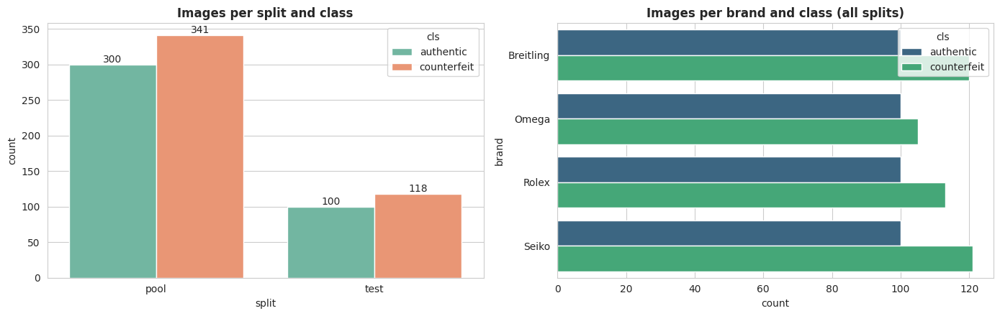

In [5]:
# ==============================================================================
# SECTION 1b: COMPOSITION TABLE AND CHECK AGAINST TABLE 2 TARGETS
# ==============================================================================
# CHAPTER 3: Data Gathering (Table 2 targets)
comp = df.groupby(["split", "cls", "brand"]).size().rename("n_images").reset_index()
savetab(comp, "table_dataset_composition_raw.csv")

expected = {("pool", "authentic"): 300, ("pool", "counterfeit"): 300, ("test", "authentic"): 100, ("test", "counterfeit"): 100}
for k, v in expected.items():
    n = int(((df.split == k[0]) & (df.cls == k[1])).sum())
    print(f"  {k[0]:>4}/{k[1]:<11} found {n:>4} | methodology target {v}" + ("" if n == v else "   <-- differs"))
if HAS_BRAND:
    per_brand = df.groupby(["split", "cls", "brand"]).size().unstack(fill_value=0)
    print("\nImages per brand (targets: pool 75, test 25 per class per brand):")
    print(per_brand)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.countplot(data=df, x="split", hue="cls", palette="Set2", ax=axes[0])
axes[0].set_title("Images per split and class", fontweight="bold")
for c in axes[0].containers: axes[0].bar_label(c)
sns.countplot(data=df, y="brand", hue="cls", palette="viridis", ax=axes[1])
axes[1].set_title("Images per brand and class (all splits)", fontweight="bold")
savefig("01_dataset_composition.png")

## 2. Quality control and exact duplicates (Data Cleaning)

> **Chapter 3 reference:** Data Cleaning
>
> **What the chapter requires**
> - Cleaning happens before any transformation and is identical for both classes.
> - Step 1: exclude images below 400 px on the short side.
> - Step 2: resize each image to 320x320, compute the variance of its Laplacian (grayscale), and exclude images below 300 as blurry.
> - Step 3: re-save surviving images as JPEG at quality 95.
> - Step 4: rembg background isolation on every image in both classes with identical settings (Section 3).
> - Step 5: MD5 hash of every remaining image, and remove exact duplicates so that none can fall in more than one partition.
> - Step 6: perceptual hashing to find near-duplicates; the clusters become the groups for partitioning (Section 4).
> - Step 7: subsample to exactly 100 images per class per brand.
>
> **Where it is implemented:** `analyze_image` (steps 1, 2, 3, 5 and the shortcut features), the gate cell `SECTION 2b` (steps 1, 2, 5 with a logged reason for every removal), and the subsampling cell `SECTION 4c` (step 7).
>
> **Outputs:** `table_cleaning_log.csv`, `table_tracker_exclusions.csv` (if the tracker removes images), `table_removed_images_all.csv`, `table_subsample_removed_images.csv`, `table_subsample_summary.csv`, figures `02`, `04c`, `04d`
>
> **Choices the chapter leaves open (made here)**
> - MD5 is computed on the in-memory quality-95 re-encoding of each image and before rembg runs. Exact duplicates are detected identically, and rembg only runs on survivors, which saves time.
> - Step 7 (subsampling to the per-cell targets) is implemented in Section 4c, after the groups and tiers exist and before the folds. The pick rule is ours (see the 4c box) and every removed image is reported.
> - If the tracker has `include` = 0 or label tier 3, those images are removed here and counted in the log (`APPLY_TRACKER_EXCLUSIONS`).

For every image the notebook records resolution, Laplacian variance at 320x320, brightness, a colour histogram, file size, estimated JPEG quality, a 64-bit perceptual hash, and the MD5 of the image re-saved at JPEG quality 95. These values drive the quality gates here and the tabular baselines in the shortcut audit (Section 7).

Gates (skipped when `PREPROCESS_MODE = "already_processed"`): short side at least 400 px, Laplacian variance at least 300 measured at 320x320, then exact duplicates by MD5 are removed. Every removal is logged with a reason.

In [6]:
# ==============================================================================
# SECTION 2: PER-IMAGE ANALYSIS (resolution, blur, hashes, tabular shortcut features)
# ==============================================================================
# CHAPTER 3: Data Cleaning
QC_SIZE = 320
_STD_LUM_QT = np.array([16,11,10,16,24,40,51,61,12,12,14,19,26,58,60,55,14,13,16,24,40,57,69,56,14,17,22,29,51,87,80,62,
                        18,22,37,56,68,109,103,77,24,35,55,64,81,104,113,92,49,64,78,87,103,121,120,101,72,92,95,98,112,100,103,99], dtype=float)

def est_jpeg_quality(path):
    """Estimate the JPEG quality of the ORIGINAL file from its quantisation table (shortcut baseline 2). Returns (quality, is_jpeg)."""
    try:
        im = Image.open(path)
        if im.format != "JPEG" or not getattr(im, "quantization", None):
            return np.nan, 0
        qt = np.array(im.quantization[0], dtype=float)
        scale = 100.0 * np.mean(qt / _STD_LUM_QT)
        q = (200 - scale) / 2 if scale <= 100 else 5000 / scale
        return float(np.clip(q, 1, 100)), 1
    except Exception:
        return np.nan, 0

def phash64(gray):
    """64-bit perceptual hash (DCT of a 32x32 grayscale thumbnail, top-left 8x8 block compared with its median). Returned as hex text."""
    g = cv2.resize(gray, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
    d = cv2.dct(g)[:8, :8].flatten()
    bits = d > np.median(d[1:])
    return format(int("".join("1" if b else "0" for b in bits), 2), "016x")   # hex string: survives NaN rows without float rounding

def analyze_image(path):
    """Read one image once and return everything the cleaning step and the shortcut audit need: size, Laplacian variance at 320x320 (Chapter 3: Data Cleaning), brightness, colour histogram, file size, re-encode ratio, JPEG quality, MD5 of the quality-95 re-encoding, and perceptual hash."""
    out = {"readable": False}
    try:
        raw = open(path, "rb").read()
        img = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
        if img is None:
            return out
        h, w = img.shape[:2]
        small = cv2.resize(img, (QC_SIZE, QC_SIZE), interpolation=cv2.INTER_AREA)
        gray_s = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
        ok, enc = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])
        jq, is_jpeg = est_jpeg_quality(path)
        hist = []
        for ch in range(3):
            hh = cv2.calcHist([small], [ch], None, [8], [0, 256]).flatten()
            hist.extend((hh / hh.sum()).tolist())
        out.update(readable=True, orig_h=h, orig_w=w, short_side=min(h, w), aspect=w / h,
                   lap_var=float(cv2.Laplacian(gray_s, cv2.CV_64F).var()),
                   brightness=float(gray_s.mean()), file_size=len(raw),
                   reencode_ratio=len(enc) / len(raw), jpeg_quality=jq, is_jpeg=is_jpeg,
                   md5=hashlib.md5(enc.tobytes()).hexdigest(), phash=phash64(gray_s))
        out.update({f"hist_{i}": v for i, v in enumerate(hist)})
    except Exception as e:
        out["error"] = str(e)
    return out

log_stage("Section 2: analysing images (resolution, blur, hashes, shortcut features)")
with ThreadPoolExecutor(max_workers=NUM_WORKERS) as ex:
    qc = pd.DataFrame(list(tqdm(ex.map(analyze_image, df["path"].tolist()), total=len(df))))
df = pd.concat([df, qc], axis=1)


[03:08:22 | +  0.0 min] Section 2: analysing images (resolution, blur, hashes, shortcut features)


  0%|          | 0/859 [00:00<?, ?it/s]

[*] Exact-duplicate removals: 0 (MD5 groups spanning pool and test: 0)
drop_reason         kept  low_resolution
split cls                               
pool  authentic    300.0             0.0
      counterfeit  312.0            29.0
test  authentic    100.0             0.0
      counterfeit  104.0            14.0


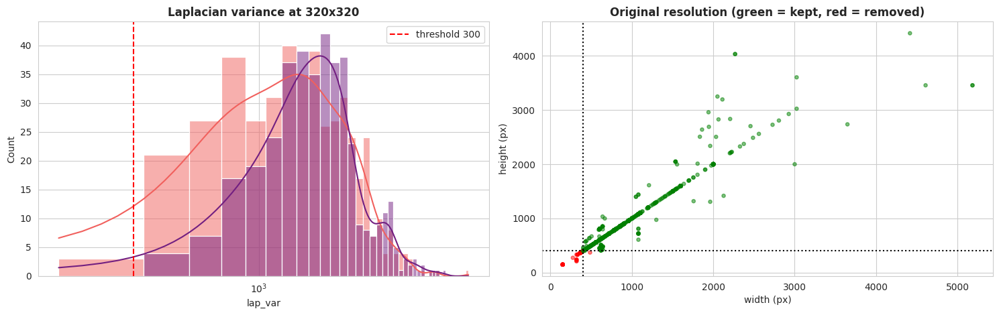

In [7]:
# ==============================================================================
# SECTION 2b: APPLY GATES, REMOVE EXACT DUPLICATES, LOG EVERY REMOVAL
# ==============================================================================
# CHAPTER 3: Data Cleaning
df["drop_reason"] = ""
unread = ~df["readable"].fillna(False).astype(bool)
df.loc[unread, "drop_reason"] = "unreadable"
if APPLY_TRACKER_EXCLUSIONS:
    # Tracker says include = 0, or label evidence Tier 3 (ambiguous or unverifiable, excluded by Chapter 3)
    m_tr = (df["drop_reason"] == "") & ((~df["include_flag"]) | (df["label_tier_num"] == 3))
    df.loc[m_tr, "drop_reason"] = "tracker_excluded"
    if m_tr.any():
        why = df.loc[m_tr, "tracker_exclusion_reason"].fillna("(no reason given)").astype(str)
        tr_tab = why.value_counts().rename_axis("tracker_exclusion_reason").reset_index(name="n_images")
        savetab(tr_tab, "table_tracker_exclusions.csv")
        print(f"[*] Tracker removes {int(m_tr.sum())} images (include = 0 or label tier 3). Reasons:\n{tr_tab.to_string(index=False)}")
if PREPROCESS_MODE != "already_processed":
    m_res = (df["drop_reason"] == "") & (df["short_side"] < MIN_SHORT_SIDE)
    df.loc[m_res, "drop_reason"] = "low_resolution"
    m_blur = (df["drop_reason"] == "") & (df["lap_var"] < LAPLACIAN_MIN)
    df.loc[m_blur, "drop_reason"] = "blurry"
    frac_res = m_res.mean()
    if frac_res > 0.3:
        print(f"\n[!!] {frac_res:.0%} of images are below {MIN_SHORT_SIDE}px on the short side. If your input folders already contain "
              f"processed/cropped images, set PREPROCESS_MODE = 'already_processed' and re-run.\n")
alive = df["drop_reason"] == ""
dup = alive & df.duplicated("md5", keep="first")
cross = df[alive].groupby("md5")["split"].nunique()
n_cross = int((cross > 1).sum())
df.loc[dup, "drop_reason"] = "exact_duplicate"
print(f"[*] Exact-duplicate removals: {int(dup.sum())} (MD5 groups spanning pool and test: {n_cross})")

log = (df.assign(drop_reason=df.drop_reason.replace("", "kept")).groupby(["split", "cls", "drop_reason"]).size()
       .rename("n").reset_index())
savetab(log, "table_cleaning_log.csv")
print(log.pivot_table(index=["split", "cls"], columns="drop_reason", values="n", fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
d_ = df[df["readable"] == True]
sns.histplot(data=d_, x="lap_var", hue="cls", bins=40, kde=True, palette="magma", ax=axes[0])
axes[0].axvline(LAPLACIAN_MIN, color="red", ls="--", label=f"threshold {LAPLACIAN_MIN:g}")
axes[0].set_xscale("log"); axes[0].set_title("Laplacian variance at 320x320", fontweight="bold"); axes[0].legend()
axes[1].scatter(d_["orig_w"], d_["orig_h"], c=(d_["drop_reason"] == "").map({True: "green", False: "red"}), alpha=0.5, s=14)
axes[1].axvline(MIN_SHORT_SIDE, color="k", ls=":"); axes[1].axhline(MIN_SHORT_SIDE, color="k", ls=":")
axes[1].set_title("Original resolution (green = kept, red = removed)", fontweight="bold")
axes[1].set_xlabel("width (px)"); axes[1].set_ylabel("height (px)")
savefig("02_quality_control.png")

## 3. Background isolation, tight crop, square pad, and resize (Data Cleaning, Resizing)

> **Chapter 3 reference:** Data Cleaning (rembg) and Resizing
>
> **What the chapter requires**
> - rembg is applied to every image in both classes with identical settings.
> - Each image is cropped to the bounding box of its rembg mask plus a small margin, with the strap trimmed where possible, and padded to a square with its aspect ratio preserved.
> - All images are resized to 320x320 with area interpolation.
> - Images whose cropped watch region is below 320 px on the short side are excluded, so nothing is upscaled.
>
> **Where it is implemented:** `preprocess_one` (mask, largest component, strap trim, crop, 320 px check, background replacement, pad, area resize) and `pad_square_resize`.
>
> **Outputs:** `03_preprocessing_qc_grid.png`, `table_image_master_log.csv`, processed images in `cache/processed/`, raw 320 px copies in `cache/raw320/`
>
> **Choices the chapter leaves open (made here)**
> - The crop itself is rectangular (mask bounding box plus margin). Padding to a square with the background colour is what makes it square, so no watch pixels are cut off or stretched.
> - Margin = 4% of the case width (`CROP_MARGIN_FRAC`). The background is replaced by white (`BG_FILL`), which is also the padding and augmentation fill colour.
> - Strap trimming is a heuristic (rows narrower than 70% of the widest row are cut, crop height is set to the case width) because the chapter does not specify a method. Inspect the QC grid, or switch it off with `TRIM_STRAP = False`.
> - A raw 320x320 copy (no isolation, no crop) is saved only for the raw-image border CNN in the shortcut audit.

For every surviving image, in both classes with identical settings:

1. rembg produces a foreground mask, and the largest connected component is kept.
2. The background is replaced by a constant colour (`BG_FILL`), so background content is hidden from the models.
3. The image is cropped to the mask's bounding box plus a small margin. **Strap trimming** uses a heuristic: for circular cases, rows narrower than 70% of the widest row (strap or bracelet) are cut, and the crop height is set equal to the case width. This is a stand-in for the manual trimming described in the chapter, so inspect the QC grid below before trusting it. Set `TRIM_STRAP = False` to keep the plain bounding box.
4. The crop must be at least 320 px on its short side, otherwise the image is excluded (`small_crop`), so that nothing is upscaled.
5. The crop is padded to a square (aspect ratio preserved) and resized to 320x320 with **area interpolation**, then saved as JPEG quality 95.

A raw 320x320 copy of each image (no isolation, no crop) is also written; it is used only by the raw-image border CNN in the shortcut audit.

Mask area, shape, and a background uniformity score (grey-level spread outside a dilated mask) are logged for each image. They feed the mask baseline of the shortcut audit and the tier check.

In [8]:
# ==============================================================================
# SECTION 3: PREPROCESSING (rembg isolation, tight crop, pad, area resize)
# ==============================================================================
# CHAPTER 3: Data Cleaning (rembg) and Resizing
REMBG_SESSION = None
if PREPROCESS_MODE == "full":
    try:
        import rembg
    except ImportError:
        print("[*] Installing rembg and onnxruntime...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rembg", "onnxruntime"], check=False)
        import rembg
    from rembg import remove as rembg_remove, new_session
    REMBG_SESSION = new_session(REMBG_MODEL)
    print("[*] rembg session ready:", REMBG_MODEL)
elif PREPROCESS_MODE == "no_rembg":
    print("[!] PREPROCESS_MODE='no_rembg': no background isolation; mask-based features and tight crop are unavailable.")
else:
    print("[*] PREPROCESS_MODE='already_processed': only padding and resizing are applied.")

def pad_square_resize(rgb, size):
    """Pad an image to a square with BG_FILL (aspect ratio preserved, nothing cut or stretched), then resize to size x size with area interpolation (Chapter 3: Resizing)."""
    h, w = rgb.shape[:2]; s = max(h, w)
    canvas = np.full((s, s, 3), BG_FILL, np.uint8)
    y0, x0 = (s - h) // 2, (s - w) // 2
    canvas[y0:y0 + h, x0:x0 + w] = rgb
    return cv2.resize(canvas, (size, size), interpolation=cv2.INTER_AREA)

def save_jpg(rgb, path):
    """Write an RGB array as JPEG at JPEG_QUALITY (95)."""
    cv2.imwrite(path, cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])

def preprocess_one(image_id, path):
    """Preprocess one image (Chapter 3: Data Cleaning and Resizing). Steps: (1) save a raw 320x320 copy for the audit; (2) rembg mask, keep the largest component; (3) log mask area/shape and the background uniformity score; (4) optionally trim the strap; (5) crop to the mask box plus margin; (6) exclude if the crop is below 320 px on its short side; (7) replace the background with BG_FILL, pad to a square and resize to 320x320. Returns a dict with the status and the logged features."""
    name = os.path.splitext(image_id.replace("/", "__"))[0] + ".jpg"
    pp, rp = f"{PROC_DIR}/{name}", f"{RAW_DIR}/{name}"
    res = dict(image_id=image_id, proc_path=pp, raw320_path=rp, status="ok")
    try:
        bgr = cv2.imdecode(np.fromfile(path, np.uint8), cv2.IMREAD_COLOR)
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB); H, W = rgb.shape[:2]
        if PREPROCESS_MODE == "already_processed":
            save_jpg(pad_square_resize(rgb, PROC_SIZE), pp); res["raw320_path"] = pp
            return res
        save_jpg(cv2.resize(rgb, (PROC_SIZE, PROC_SIZE), interpolation=cv2.INTER_AREA), rp)
        sc = min(1.0, 640.0 / max(H, W))
        small = cv2.resize(rgb, (max(1, int(W * sc)), max(1, int(H * sc))), interpolation=cv2.INTER_AREA)
        gray_s = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY)
        if REMBG_SESSION is None:
            b = max(1, int(0.1 * min(gray_s.shape)))
            band = np.zeros(gray_s.shape, bool); band[:b] = band[-b:] = True; band[:, :b] = band[:, -b:] = True
            res.update(bg_uniformity=float(gray_s[band].std()), crop_short=float(min(H, W)))
            save_jpg(pad_square_resize(rgb, PROC_SIZE), pp)
            return res
        alpha8 = np.array(rembg_remove(Image.fromarray(rgb), session=REMBG_SESSION, only_mask=True))
        if alpha8.ndim == 3: alpha8 = alpha8[..., 0]
        binary = (alpha8 > 127).astype(np.uint8)
        n, lab, st, _ = cv2.connectedComponentsWithStats(binary, 8)
        if n <= 1:
            res["status"] = "empty_mask"; return res
        k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA])); cc = (lab == k).astype(np.uint8)
        ys, xs = np.where(cc > 0); x0, x1, y0, y1 = int(xs.min()), int(xs.max()), int(ys.min()), int(ys.max())
        bw, bh = x1 - x0 + 1, y1 - y0 + 1
        area = float(cc.sum()); cnts, _ = cv2.findContours(cc, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        hull = cv2.contourArea(cv2.convexHull(max(cnts, key=cv2.contourArea)))
        cc_s = cv2.resize(cc, (gray_s.shape[1], gray_s.shape[0]), interpolation=cv2.INTER_NEAREST)
        r = max(1, int(0.03 * max(gray_s.shape)))
        dil = cv2.dilate(cc_s, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1)))
        bgm = dil == 0
        res.update(mask_area_frac=area / (H * W), mask_bbox_aspect=bw / bh, mask_extent=area / (bw * bh),
                   mask_solidity=area / max(hull, 1.0),
                   bg_uniformity=float(gray_s[bgm].std()) if bgm.sum() > 100 else 0.0)
        case_w = bw
        if TRIM_STRAP:
            wrow = cc.sum(1); rows = np.where(wrow >= 0.7 * wrow.max())[0]
            cy = (rows.min() + rows.max()) / 2.0; half = wrow.max() / 2.0
            ty0, ty1 = int(max(y0, round(cy - half))), int(min(y1, round(cy + half)))
            if ty1 - ty0 + 1 >= 0.5 * case_w:
                y0, y1 = ty0, ty1
        mg = int(CROP_MARGIN_FRAC * case_w)
        cx0, cx1 = max(0, x0 - mg), min(W, x1 + mg + 1); cy0, cy1 = max(0, y0 - mg), min(H, y1 + mg + 1)
        res["crop_short"] = float(min(cx1 - cx0, cy1 - cy0))
        if ENFORCE_MIN_CROP and res["crop_short"] < MIN_CROP_SHORT:
            res["status"] = "small_crop"; return res
        alpha = (alpha8.astype(np.float32) / 255.0) * cv2.dilate(cc, np.ones((5, 5), np.uint8)).astype(np.float32)
        comp = (rgb.astype(np.float32) * alpha[..., None] + np.array(BG_FILL, np.float32) * (1 - alpha[..., None])).astype(np.uint8)
        save_jpg(pad_square_resize(comp[cy0:cy1, cx0:cx1], PROC_SIZE), pp)
    except Exception as e:
        res["status"] = f"error: {e}"
    return res

cache_csv = f"{CACHE}/preproc_features_{PREPROCESS_MODE}.csv"
cached = pd.read_csv(cache_csv).set_index("image_id").to_dict("index") if os.path.exists(cache_csv) else {}
todo = df[df["drop_reason"] == ""][["image_id", "path"]]
results = []
log_stage(f"Section 3: preprocessing {len(todo)} images ({len(cached)} cached)")
for i, (iid, p) in enumerate(tqdm(todo.itertuples(index=False), total=len(todo))):
    c = cached.get(iid)
    if c is not None and os.path.exists(c["proc_path"]) and (c["status"] != "ok" or os.path.exists(c["proc_path"])):
        results.append({"image_id": iid, **c}); continue
    results.append(preprocess_one(iid, p))
    if (i + 1) % 100 == 0:
        pd.DataFrame(results).to_csv(cache_csv, index=False)
prep = pd.DataFrame(results)
prep.to_csv(cache_csv, index=False)

df = df.merge(prep, on="image_id", how="left")
bad = df["status"].notna() & (df["status"] != "ok")
df.loc[bad & (df["drop_reason"] == ""), "drop_reason"] = df.loc[bad, "status"].astype(str)
print(df.groupby(["split", "cls"])["drop_reason"].value_counts().unstack(fill_value=0))

data = df[df["drop_reason"] == ""].copy().reset_index(drop=True)
savetab(df.drop(columns=["path", "proc_path", "raw320_path"]).assign(kept=df["drop_reason"] == ""), "table_image_master_log.csv")
print(f"\n[*] Images kept after all cleaning steps: {len(data)} / {len(df)}")
print(data.groupby(["split", "cls"]).size().unstack())

[*] Installing rembg and onnxruntime...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 83.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 98.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.7/13.7 MB 94.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 89.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 35.3 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires numba<0.63,>=0.60, but you have numba 0.68.0 which is incompatible.
ydata-profiling 4.18.4 requires numpy<2.4,>=1.22, but you have numpy 2.5.4 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.

  0%|                                               | 0.00/176M [00:00<?, ?B/s]

[*] rembg session ready: u2net

[03:09:43 | +  1.4 min] Section 3: preprocessing 816 images (0 cached)


  0%|          | 0/816 [00:00<?, ?it/s]

drop_reason             low_resolution  small_crop
split cls                                         
pool  authentic    292               0           8
      counterfeit  285              29          27
test  authentic     99               0           1
      counterfeit   90              14          14

[*] Images kept after all cleaning steps: 766 / 859
cls    authentic  counterfeit
split                        
pool         292          285
test          99           90


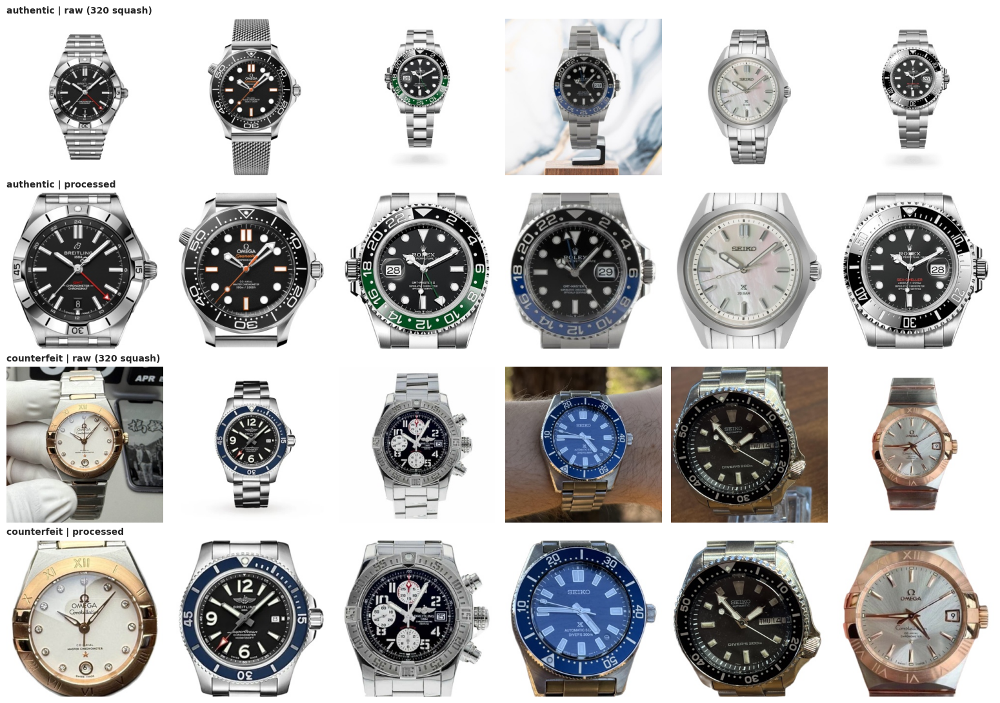

In [9]:
# ==============================================================================
# SECTION 3b: PREPROCESSING QC GRID (inspect the crop and strap trimming here)
# ==============================================================================
# CHAPTER 3: Data Cleaning (rembg) and Resizing
rng_q = np.random.RandomState(0)
n_show = 6
fig, axes = plt.subplots(4, n_show, figsize=(2.6 * n_show, 11))
for r, (cls, kind) in enumerate([("authentic", "raw320_path"), ("authentic", "proc_path"),
                                 ("counterfeit", "raw320_path"), ("counterfeit", "proc_path")]):
    pool_c = data[data["cls"] == cls]
    idx = np.random.RandomState(0).choice(len(pool_c), size=min(n_show, len(pool_c)), replace=False)
    for c in range(n_show):
        ax = axes[r, c]; ax.axis("off")
        if c < len(idx):
            row = pool_c.iloc[idx[c]]
            ax.imshow(Image.open(row[kind]))
            if c == 0: ax.set_title(f"{cls} | {'raw (320 squash)' if kind == 'raw320_path' else 'processed'}", loc="left", fontsize=10, fontweight="bold")
savefig("03_preprocessing_qc_grid.png")

## 4. Near-duplicate groups and background tier (Data Partitioning, Data Gathering)

> **Chapter 3 reference:** Data Partitioning (groups) and Data Gathering (background tier)
>
> **What the chapter requires**
> - Groups are near-duplicate clusters from perceptual hashing, merged with seller identity. Any group larger than 5% of the pool is reviewed by hand.
> - Background tiers are labelled by rubric and checked against a background uniformity score computed around the rembg mask.
>
> **Where it is implemented:** `build_groups` (union-find over hash distance, seller identity, and the tracker's `group_id`), the tier cell (`SECTION 4b`).
>
> **Outputs:** `table_pool_test_overlap.csv`, `table_large_groups_review.csv`, `table_watermark_rate.csv`, `04_tier_uniformity_check.png`
>
> **Choices the chapter leaves open (made here)**
> - Two images are near-duplicates when their 64-bit perceptual hashes differ in at most 8 bits (`PHASH_MAX_DIST`).
> - The tier is taken from the tracker column named in `TIER_COLUMN` (default `background`). If no tier labels exist it falls back to a proxy from the uniformity score, and every table says so. The tracker's `label_tier` is the label evidence tier (1, 2, 3), not the background tier.

**Groups.** Near-duplicates are found with a 64-bit perceptual hash (Hamming distance at most `PHASH_MAX_DIST`). Clusters are merged with seller identity when seller metadata exists, using union-find. The clustering runs over pool and test together, so any group that spans both is a leakage warning. Groups larger than 5% of the pool are listed for manual review.

**Tier.** If your metadata has a `tier` column it is used. Otherwise a **proxy** tier is derived from the background uniformity score (`PLAIN_STD_THRESHOLD`) and every tier-based table is marked as proxy. The histogram checks the human labels against the score when both exist.

In [10]:
# ==============================================================================
# SECTION 4: GROUPS (perceptual hash clusters + seller)
# ==============================================================================
# CHAPTER 3: Data Partitioning (groups)
def build_groups(d):
    """Union-find over three links: perceptual-hash distance <= PHASH_MAX_DIST, same seller, and same tracker group_id. Returns one group id per image (Chapter 3: Data Partitioning)."""
    n = len(d); parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb: parent[max(ra, rb)] = min(ra, rb)
    bits = np.array([[(int(h, 16) >> i) & 1 for i in range(64)] for h in d["phash"]], dtype=np.uint8)
    dist = (bits[:, None, :] != bits[None, :, :]).sum(-1)
    ii, jj = np.where(np.triu(dist <= PHASH_MAX_DIST, 1))
    for a, b in zip(ii, jj): union(a, b)
    n_hash_edges = len(ii)
    if d["seller"].notna().any():
        for s, idx in d.groupby(d["seller"].astype(str).str.strip().str.lower()).indices.items():
            if s in ("", "nan", "unknown", "none"): continue
            for a, b in zip(idx[:-1], idx[1:]): union(a, b)
    if USE_TRACKER_GROUPS and d["tracker_group_id"].notna().any():
        for g_, idx in d.groupby(d["tracker_group_id"].astype(str)).indices.items():
            if g_ in ("nan", "", "none"): continue
            for a, b in zip(idx[:-1], idx[1:]): union(a, b)
    roots = np.array([find(i) for i in range(n)])
    dense = {r: i for i, r in enumerate(np.unique(roots))}
    return np.array([dense[r] for r in roots]), n_hash_edges

data["group_id"], n_edges = build_groups(data)
print(f"[*] Near-duplicate pairs (hash distance <= {PHASH_MAX_DIST}): {n_edges} | groups: {data.group_id.nunique()} for {len(data)} images")

span = data.groupby("group_id")["split"].nunique()
leak_groups = span[span > 1].index
if len(leak_groups):
    print(f"[!!] {len(leak_groups)} group(s) contain images from BOTH pool and test (possible leakage). Review table_pool_test_overlap.csv")
    savetab(data[data.group_id.isin(leak_groups)][["image_id", "split", "cls", "brand", "seller", "source", "group_id"]],
            "table_pool_test_overlap.csv")
else:
    print("[✓] No group spans pool and test.")

pool_n = int((data.split == "pool").sum())
gsize = data[data.split == "pool"].groupby("group_id").size()
big = gsize[gsize > 0.05 * pool_n]
if len(big):
    print(f"[!] {len(big)} pool group(s) exceed 5% of the pool ({0.05 * pool_n:.0f} images): review by hand")
    savetab(data[data.group_id.isin(big.index)][["image_id", "cls", "brand", "seller", "source", "group_id"]], "table_large_groups_review.csv")

if HAS_SOURCE:
    sp = set(data[data.split == "pool"].source.dropna().str.lower()); st_ = set(data[data.split == "test"].source.dropna().str.lower())
    print("[*] Sources shared by pool and test:", sorted(sp & st_) if sp & st_ else "none (source-disjoint)")
if HAS_SELLER:
    sp = set(data[data.split == "pool"].seller.dropna().astype(str).str.lower()); st_ = set(data[data.split == "test"].seller.dropna().astype(str).str.lower())
    print("[*] Sellers shared by pool and test:", len(sp & st_))
if (data[data.split == "test"].brand_website).any():
    print("[!] The external test set contains brand-website images; the methodology keeps them out of it.")
md5_overlap = set(data[data.split == "pool"].md5) & set(data[data.split == "test"].md5)
assert len(md5_overlap) == 0, "Exact duplicates across pool and test"

[*] Near-duplicate pairs (hash distance <= 8): 430 | groups: 68 for 766 images
[!!] 4 group(s) contain images from BOTH pool and test (possible leakage). Review table_pool_test_overlap.csv
[!] 1 pool group(s) exceed 5% of the pool (29 images): review by hand
[*] Sources shared by pool and test: ['brand website', 'paterson jewellers', 'wsongtime']
[*] Sellers shared by pool and test: 9
[!] The external test set contains brand-website images; the methodology keeps them out of it.


[*] Background tier source: METADATA
tier               Plain  Uncontrolled
split cls                             
pool  authentic      116           176
      counterfeit    110           175
test  authentic       39            60
      counterfeit     38            52

Watermark rate by split and class:
                      n  watermarked  watermark_rate
split cls                                          
pool  authentic    292            0             0.0
      counterfeit  285            0             0.0
test  authentic     99            0             0.0
      counterfeit   90            0             0.0


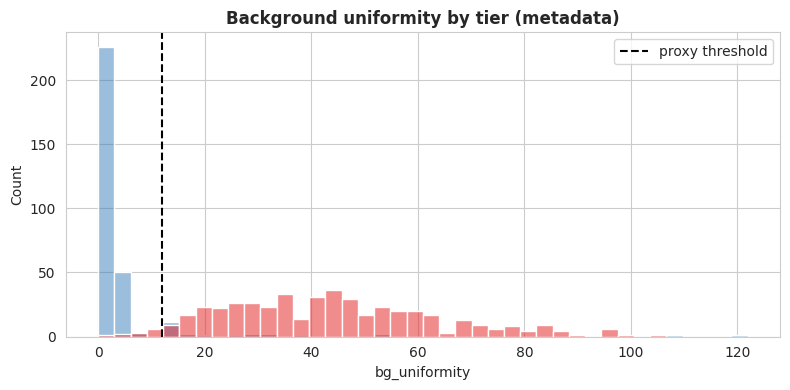

[*] Agreement of the uniformity rule with your human tier labels: 95.3%


In [11]:
# ==============================================================================
# SECTION 4b: BACKGROUND TIER (metadata, or PROXY from background uniformity)
# ==============================================================================
# CHAPTER 3: Data Gathering (background tier)
if HAS_TIER_META:
    data["tier"] = data["tier"].astype(str).str.strip().str.title().replace({"Nan": np.nan})
    TIER_SOURCE = "metadata"
elif "bg_uniformity" in data.columns and data["bg_uniformity"].notna().any():
    data["tier"] = np.where(data["bg_uniformity"] <= PLAIN_STD_THRESHOLD, "Plain", "Uncontrolled")
    TIER_SOURCE = "proxy"
else:
    data["tier"] = "Unknown"; TIER_SOURCE = "unavailable"
data["tier"] = data["tier"].fillna("Unknown")
print(f"[*] Background tier source: {TIER_SOURCE.upper()}")
print(data.groupby(["split", "cls", "tier"]).size().unstack(fill_value=0))
if TIER_SOURCE == "proxy":
    print("[!] Tier is a PROXY from background uniformity; replace with human labels (metadata.csv) for the final results.")

if data["watermark"].notna().any():
    wm = data.groupby(["split", "cls"])["watermark"].agg(n="size", watermarked=lambda x: int(x.fillna(False).astype(bool).sum()))
    wm["watermark_rate"] = wm["watermarked"] / wm["n"]; savetab(wm.reset_index(), "table_watermark_rate.csv"); print("\nWatermark rate by split and class:\n", wm.round(3))

if "bg_uniformity" in data.columns and data["bg_uniformity"].notna().any():
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(data=data, x="bg_uniformity", hue="tier", bins=40, ax=ax, palette="Set1")
    ax.axvline(PLAIN_STD_THRESHOLD, color="k", ls="--", label="proxy threshold")
    ax.set_title(f"Background uniformity by tier ({TIER_SOURCE})", fontweight="bold"); ax.legend()
    savefig("04_tier_uniformity_check.png")
    if TIER_SOURCE == "metadata":
        lab = data[data.tier.isin(["Plain", "Uncontrolled"])]
        acc = ((lab.bg_uniformity <= PLAIN_STD_THRESHOLD) == (lab.tier == "Plain")).mean()
        print(f"[*] Agreement of the uniformity rule with your human tier labels: {acc:.1%}")

### 4c. Subsample to the target counts (the last cleaning step, before partitioning)

> **Chapter 3 reference:** Data Cleaning, step 7: after exact and near-duplicate handling, subsample to exactly 100 images per class per brand. With the pool and test folders already separated, the targets are 75 per class per brand in the pool and 25 per class per brand in the test set (Table 2).
>
> **What this cell does**
> - Counts the images in every split x class x brand cell. A cell above its target is cut down to the target. A cell at or below its target is left alone, and any shortfall is reported (the notebook cannot add images).
> - **Selection rule (ours, because the chapter gives none):** a seeded, reproducible, balanced pick. Inside a cell it first sets the Plain / Uncontrolled quota (40% Plain when both tiers are present), then spreads the picks across sources and, inside a source, across sellers (the seller with the fewest picks goes first). Brand-website images are kept in their natural share, capped at 20% of the authentic pool, and never preferred in the test set.
> - **Reports every removal:** `table_subsample_removed_images.csv` (each image taken out here), `table_removed_images_all.csv` (every image removed anywhere in the pipeline, with its stage and detail, including the tracker's own `image_id`), and `table_subsample_summary.csv` (before, target, after, and balance per cell).
> - **Before and after figures:** `04c_dataset_before_after_subsample.png` compares counts, tier mix, and source mix; `04d_removal_summary.png` shows what was removed at each stage.
>
> Set `SUBSAMPLE_TO_TARGET = False` to keep every cleaned image and only report the comparison.


[03:20:59 | + 12.7 min] Section 4c: subsampling to the target counts
[*] Before subsampling: 766 images | target rule on: True | removed here: 31 | after: 735
split         cls     brand  before  target  after  removed  short_of_target
 pool   authentic Breitling      73      75     73        0                2
 pool   authentic     Omega      74      75     74        0                1
 pool   authentic     Rolex      70      75     70        0                5
 pool   authentic     Seiko      75      75     75        0                0
 pool counterfeit Breitling      80      75     75        5                0
 pool counterfeit     Omega      62      75     62        0               13
 pool counterfeit     Rolex      51      75     51        0               24
 pool counterfeit     Seiko      92      75     75       17                0
 test   authentic Breitling      25      25     25        0                0
 test   authentic     Omega      25      25     25        0           

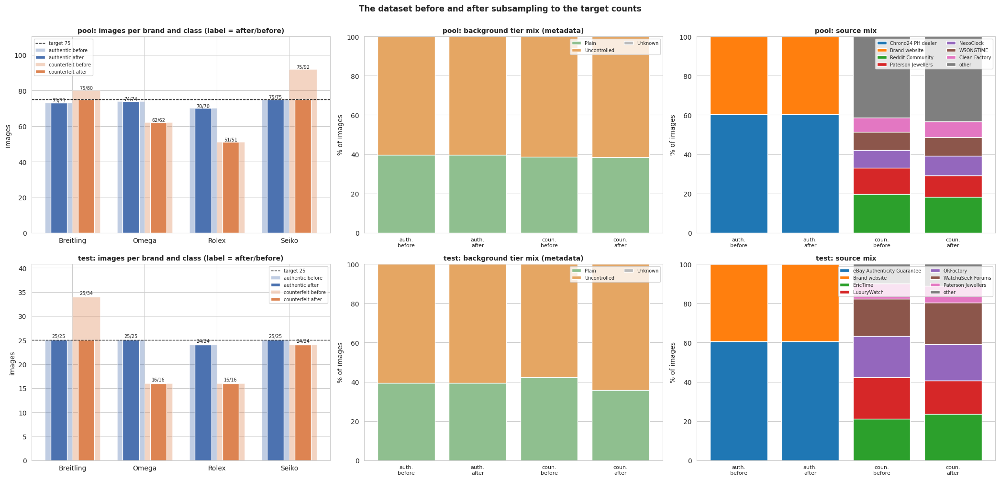

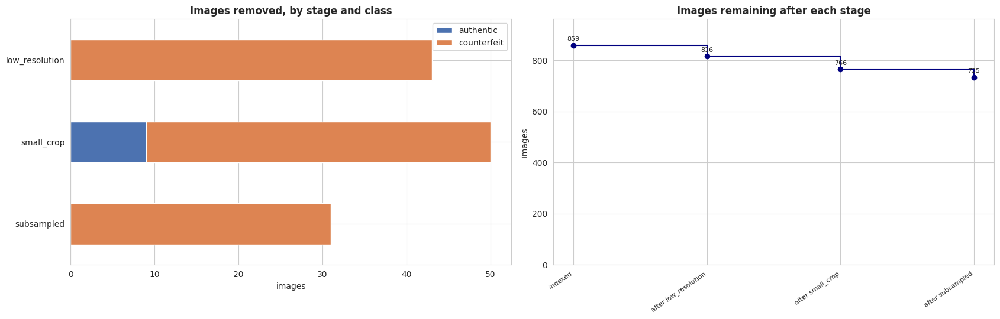

In [12]:
# ==============================================================================
# SECTION 4c: SUBSAMPLE TO THE TARGET COUNTS (before data partitioning)
# ==============================================================================
# CHAPTER 3: Data Cleaning (step 7, subsampling)
# CHAPTER 3: Data Cleaning (step 7, subsampling)
log_stage("Section 4c: subsampling to the target counts")
before = data.copy()                                    # the dataset after cleaning, groups, and tiers, BEFORE subsampling
TARGET = {"pool": TARGET_POOL_PER_CELL, "test": TARGET_TEST_PER_CELL}
N_BRAND_CELLS = 1 if HAS_BRAND else len(BRANDS)         # without brand info the target is the sum over the four brands
BW_CAP_SHARE = {("pool", "authentic"): SUBSAMPLE_BW_CAP}   # Chapter 3: brand-website images <= 20% of the authentic pool, none in the test set
cell_cols = ["split", "cls"] + (["brand"] if HAS_BRAND else [])

def _round_robin(sub, k, rng):
    """Pick k rows of `sub`, spreading the picks over sources and, inside a source, over sellers (fewest-picked seller first)."""
    if k <= 0: return []
    if k >= len(sub): return list(sub.index)
    buckets = {}
    for src, s1 in sub.groupby(sub["source"].fillna("?").astype(str), sort=False):
        buckets[src] = {sid: list(s2.index) for sid, s2 in s1.groupby(s1["seller"].fillna("?").astype(str), sort=False)}
    chosen, seller_n = [], {}
    while len(chosen) < k:
        took = False
        for src in list(buckets):
            if len(chosen) >= k: break
            sellers = {s: v for s, v in buckets[src].items() if v}
            if not sellers: continue
            sid = min(sellers, key=lambda s: (seller_n.get((src, s), 0), rng.rand()))
            chosen.append(buckets[src][sid].pop(0)); seller_n[(src, sid)] = seller_n.get((src, sid), 0) + 1; took = True
        if not took: break
    return chosen

def _pick_cell(cell, target, bw_cap_share, rng):
    """Return the index labels to KEEP from one split x class x brand cell (all of them if the cell is not above its target)."""
    if len(cell) <= target: return list(cell.index)
    cell = cell.sample(frac=1, random_state=rng)         # seeded shuffle: ties are broken randomly but reproducibly
    tiers = cell["tier"].fillna("Unknown")
    if {"Plain", "Uncontrolled"} <= set(tiers):          # tier quotas: SUBSAMPLE_PLAIN_SHARE Plain, the rest Uncontrolled
        avail = tiers.value_counts().to_dict()
        q = {"Plain": int(round(SUBSAMPLE_PLAIN_SHARE * target))}; q["Uncontrolled"] = target - q["Plain"]
        q = {t: min(v, avail.get(t, 0)) for t, v in q.items()}
        short = target - sum(q.values())
        for t in ["Uncontrolled", "Plain"]:               # if one tier is short, the other tier fills the gap
            add = min(avail.get(t, 0) - q[t], short); q[t] += add; short -= add
        strata = [(cell[tiers == t], q[t]) for t in q]
        if short > 0: strata.append((cell[~tiers.isin(["Plain", "Uncontrolled"])], short))
    else:
        strata = [(cell, target)]
    keep = []
    for sub, k in strata:
        if k <= 0 or len(sub) == 0: continue
        is_bw = sub["brand_website"].astype(bool)
        bw_q = min(int(np.floor(bw_cap_share * k)), int(round(k * is_bw.mean())))   # natural share, capped
        first = _round_robin(sub[is_bw], bw_q, rng)
        rest = sub.drop(index=first)
        nb = _round_robin(rest[~rest["brand_website"].astype(bool)], k - len(first), rng)
        keep += first + nb
        if len(first) + len(nb) < k:                      # not enough non-brand-website images: fall back to the remainder
            keep += _round_robin(rest.drop(index=nb), k - len(first) - len(nb), rng)
    return keep

rng_sub = np.random.RandomState(SUBSAMPLE_SEED)
cell_n = before.groupby(cell_cols).size().to_dict()
keep_idx = []
for key, cell in before.groupby(cell_cols, sort=True):
    keep_idx += _pick_cell(cell, TARGET[key[0]] * N_BRAND_CELLS, BW_CAP_SHARE.get((key[0], key[1]), 0.0), rng_sub) if SUBSAMPLE_TO_TARGET else list(cell.index)
kept = before.loc[sorted(set(keep_idx))]
removed = before.drop(index=kept.index)

# ---- what was removed here ----------------------------------------------------------------
def _why(r):
    key = (r["split"], r["cls"]) + ((r["brand"],) if HAS_BRAND else ())
    return f"subsampled: {'/'.join(map(str, key))} had {cell_n[key]} images, target {TARGET[r['split']] * N_BRAND_CELLS}"
rem_cols = ["image_id", "tracker_image_id", "filename", "split", "cls", "brand", "tier", "source", "seller", "model_ref", "brand_website", "group_id"]
removed_tab = removed[rem_cols].copy(); removed_tab["reason"] = removed.apply(_why, axis=1) if len(removed) else []
savetab(removed_tab.sort_values(["split", "cls", "brand", "image_id"]), "table_subsample_removed_images.csv")

rows = []
for key, cell in before.groupby(cell_cols, sort=True):
    aft = kept.loc[kept.index.intersection(cell.index)]; tgt = TARGET[key[0]] * N_BRAND_CELLS
    rows.append(dict(split=key[0], cls=key[1], brand=(key[2] if HAS_BRAND else "all"), before=len(cell), target=tgt, after=len(aft), removed=len(cell) - len(aft),
                     short_of_target=max(0, tgt - len(aft)),
                     plain_share_before=(cell.tier == "Plain").mean(), plain_share_after=(aft.tier == "Plain").mean() if len(aft) else np.nan,
                     sources_before=cell.source.nunique(), sources_after=aft.source.nunique(), sellers_before=cell.seller.nunique(), sellers_after=aft.seller.nunique(),
                     brand_website_before=int(cell.brand_website.sum()), brand_website_after=int(aft.brand_website.sum())))
sub_summary = pd.DataFrame(rows); savetab(sub_summary, "table_subsample_summary.csv")
print(f"[*] Before subsampling: {len(before)} images | target rule on: {SUBSAMPLE_TO_TARGET} | removed here: {len(removed)} | after: {len(kept)}")
print(sub_summary[["split", "cls", "brand", "before", "target", "after", "removed", "short_of_target"]].to_string(index=False))
if (sub_summary.short_of_target > 0).any():
    print("\n[!] Cells BELOW their target (nothing can be added; they stay short):")
    print(sub_summary[sub_summary.short_of_target > 0][["split", "cls", "brand", "after", "target", "short_of_target"]].to_string(index=False))
if len(removed_tab):
    print(f"\nFirst 20 of {len(removed_tab)} images removed by subsampling (full list: table_subsample_removed_images.csv):")
    print(removed_tab[["image_id", "tracker_image_id", "split", "cls", "brand", "tier", "source"]].head(20).to_string(index=False))

# ---- apply: from here on the dataset is the subsampled one -------------------------------------
df.loc[df["image_id"].isin(removed["image_id"]), "drop_reason"] = "subsampled"
data = kept.copy().reset_index(drop=True)
savetab(df.drop(columns=["path", "proc_path", "raw320_path"]).assign(kept=df["drop_reason"] == ""), "table_image_master_log.csv")

# ---- every image removed anywhere in the pipeline, with the stage and the detail ------------------
first_by_md5 = df[df["readable"] == True].drop_duplicates("md5").set_index("md5")["image_id"].to_dict()
why_sub = dict(zip(removed_tab["image_id"], removed_tab["reason"])) if len(removed_tab) else {}
def _detail(r):
    d = r["drop_reason"]
    if d == "low_resolution": return f"short side {r['short_side']:.0f} px (minimum {MIN_SHORT_SIDE})"
    if d == "blurry": return f"Laplacian variance {r['lap_var']:.0f} (minimum {LAPLACIAN_MIN:g})"
    if d == "exact_duplicate": return f"same image as {first_by_md5.get(r['md5'], '?')}"
    if d == "tracker_excluded": return f"tracker: {r['tracker_exclusion_reason'] if pd.notna(r['tracker_exclusion_reason']) else 'include = 0'}; label tier {r['label_tier_num']}"
    if d == "small_crop": return f"cropped watch {r['crop_short']:.0f} px on the short side (minimum {MIN_CROP_SHORT})"
    if d == "subsampled": return why_sub.get(r["image_id"], "")
    return str(r.get("status", ""))
rem_all = df[df["drop_reason"] != ""].copy()
rem_all["stage"] = rem_all["drop_reason"]; rem_all["detail"] = rem_all.apply(_detail, axis=1)
rem_all = rem_all[["image_id", "tracker_image_id", "filename", "split", "cls", "brand", "stage", "detail"]].sort_values(["stage", "split", "cls", "image_id"])
savetab(rem_all, "table_removed_images_all.csv")
print(f"\n[*] All removals across the pipeline ({len(rem_all)} images, table_removed_images_all.csv):")
print(rem_all.groupby(["stage", "cls"]).size().unstack(fill_value=0).to_string())

# ---- figure 1: the dataset before and after subsampling ---------------------------------------------
TIER_COLS = {"Plain": "#8FBF8F", "Uncontrolled": "#E5A663", "Unknown": "#BBBBBB"}
def _stack(ax, frames, labels, col, order, colors, title):
    bottoms = np.zeros(len(frames))
    for lvl in order:
        vals = np.array([(f[col].fillna("Unknown").astype(str) == lvl).mean() * 100 if len(f) else 0 for f in frames])
        ax.bar(range(len(frames)), vals, bottom=bottoms, color=colors.get(lvl, None), label=lvl); bottoms += vals
    ax.set_xticks(range(len(frames))); ax.set_xticklabels(labels, fontsize=8); ax.set_ylabel("% of images"); ax.set_title(title, fontweight="bold", fontsize=10)
    ax.legend(fontsize=7, loc="upper right", ncol=2)

fig, axes = plt.subplots(2, 3, figsize=(21, 10))
for r, split in enumerate(["pool", "test"]):
    b, a = before[before.split == split], kept[kept.split == split]
    brands = sorted(before.brand.unique()) if HAS_BRAND else ["all"]; x = np.arange(len(brands)); w = 0.38; ax = axes[r, 0]
    for ci, (cls, color) in enumerate([("authentic", "#4C72B0"), ("counterfeit", "#DD8452")]):
        nb_ = [int(((b.cls == cls) & ((b.brand == br) if HAS_BRAND else True)).sum()) for br in brands]
        na_ = [int(((a.cls == cls) & ((a.brand == br) if HAS_BRAND else True)).sum()) for br in brands]
        ax.bar(x + (ci - 0.5) * w, nb_, w, color=color, alpha=0.35, label=f"{cls} before")
        ax.bar(x + (ci - 0.5) * w, na_, w * 0.6, color=color, label=f"{cls} after")
        for xi, (u, v) in enumerate(zip(nb_, na_)): ax.text(xi + (ci - 0.5) * w, u + 0.5, f"{v}/{u}", ha="center", fontsize=7)
    ax.axhline(TARGET[split] * N_BRAND_CELLS, color="k", ls="--", lw=1, label=f"target {TARGET[split] * N_BRAND_CELLS}")
    ax.set_xticks(x); ax.set_xticklabels(brands); ax.set_ylabel("images"); ax.legend(fontsize=7)
    ax.set_ylim(0, max(b.groupby(["cls"] + (["brand"] if HAS_BRAND else [])).size().max(), TARGET[split] * N_BRAND_CELLS) * 1.2)   # headroom for the count labels
    ax.set_title(f"{split}: images per brand and class (label = after/before)", fontweight="bold", fontsize=10)
    frames, labels = [], []
    for cls in ["authentic", "counterfeit"]:
        frames += [b[b.cls == cls], a[a.cls == cls]]; labels += [f"{cls[:4]}.\nbefore", f"{cls[:4]}.\nafter"]
    _stack(axes[r, 1], frames, labels, "tier", ["Plain", "Uncontrolled", "Unknown"], TIER_COLS, f"{split}: background tier mix ({TIER_SOURCE})")
    if HAS_SOURCE:
        top = before[before.split == split].source.fillna("Unknown").value_counts().index[:7].tolist()
        frames_s = [f.assign(source=f.source.fillna("Unknown").where(f.source.fillna("Unknown").isin(top), "other")) for f in frames]
        _stack(axes[r, 2], frames_s, labels, "source", top + ["other"], dict(zip(top + ["other"], sns.color_palette("tab10", len(top) + 1))), f"{split}: source mix")
    else:
        axes[r, 2].axis("off"); axes[r, 2].text(0.5, 0.5, "source not available (needs the tracker)", ha="center")
fig.suptitle("The dataset before and after subsampling to the target counts", fontweight="bold", y=1.0)
savefig("04c_dataset_before_after_subsample.png")

# ---- figure 2: what was removed at each stage ---------------------------------------------------------
stage_order = ["unreadable", "tracker_excluded", "low_resolution", "blurry", "exact_duplicate", "empty_mask", "small_crop", "subsampled"]
dr = df["drop_reason"].replace({s: "preprocess_error" for s in df["drop_reason"].unique() if str(s).startswith("error")})
stages = [s for s in stage_order if (dr == s).any()] + (["preprocess_error"] if (dr == "preprocess_error").any() else [])
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
cnt = pd.DataFrame({c: [int(((dr == s) & (df.cls == c)).sum()) for s in stages] for c in ["authentic", "counterfeit"]}, index=stages)
if len(stages): cnt.plot(kind="barh", stacked=True, ax=axes[0], color=["#4C72B0", "#DD8452"]); axes[0].invert_yaxis()
axes[0].set_title("Images removed, by stage and class", fontweight="bold"); axes[0].set_xlabel("images")
remain = [len(df)]; names = ["indexed"]
for s in stages: remain.append(remain[-1] - int((dr == s).sum())); names.append(f"after {s}")
axes[1].step(range(len(remain)), remain, where="post", color="navy", marker="o")
for i_, v_ in enumerate(remain): axes[1].text(i_, v_ + max(remain) * 0.02, str(v_), ha="center", fontsize=8)
axes[1].set_xticks(range(len(remain))); axes[1].set_xticklabels(names, rotation=35, ha="right", fontsize=8); axes[1].set_ylim(0, max(remain) * 1.12)
axes[1].set_title("Images remaining after each stage", fontweight="bold"); axes[1].set_ylabel("images")
savefig("04d_removal_summary.png")

## 5. Fixed grouped folds (Data Partitioning)

> **Chapter 3 reference:** Data Partitioning
>
> **What the chapter requires**
> - Five-fold StratifiedGroupKFold on the 600-image pool, stratified on class and brand, grouped as in Section 4.
> - No group or seller appears in more than one fold; sources may appear in several.
> - Each fold is held out once; a validation set is split from each training portion by the same grouped procedure, giving about 408 training, 72 validation, and 120 held-out images per fold.
> - Realised counts and background-tier balance of each fold are reported, because the splitter cannot guarantee exact counts.
> - Folds are created once, saved to a file, reused for all models and seeds, and verified by automatic assertions.
>
> **Where it is implemented:** `make_folds`, the assertion block, and the fold composition table.
>
> **Outputs:** `fold_assignments.csv`, `table_fold_composition.csv`, `05_fold_composition.png`
>
> **Choices the chapter leaves open (made here)**
> - The validation set is the best of the inner 6-fold StratifiedGroupKFold splits tried over `VAL_SEED_SEARCH` seeds: closest to 72 images, with at least `VAL_MIN_PER_CLASS` images of each class (D16). The held-out folds use the most balanced of `FOLD_SEED_SEARCH` seeds. Groups are never split, so the grouping rules are unchanged.
> - `FOLD_FILE_INPUT` loads a saved fold file so teammates run identical folds.

- Five-fold `StratifiedGroupKFold` on the pool, stratified on class and brand, grouped by the Section 4 groups.
- A validation set (about 72 images, both classes, at least 20 each) is split from each training portion by the same grouped, stratified procedure, choosing the best of several seeds.
- Assignments are created **once**, saved to `fold_assignments.csv`, and reused for every model and seed. To make teammates use identical folds, upload this file as a Kaggle dataset and set `FOLD_FILE_INPUT`.
- Assertions check the rules, and the realised counts and tier balance of each fold are reported (the splitter cannot guarantee exact counts).


[03:21:02 | + 12.7 min] Section 5: creating or loading the fixed folds
    fold seed 115 chosen out of 300 (balance score 0.954); held-out sizes [217, 101, 104, 52, 81]
[*] Created fold assignments (the fold seed was searched from 42, see the line above)
[✓] Fold assertions passed: no group (or seller) crosses held-out, validation, and training; pool and test share no MD5.
[✓] Every validation set has at least 48 images and 20 per class.
role  heldout  train  val
fold                     
0         217    265   73
1         101    384   70
2         104    376   75
3          52    431   72
4          81    403   71


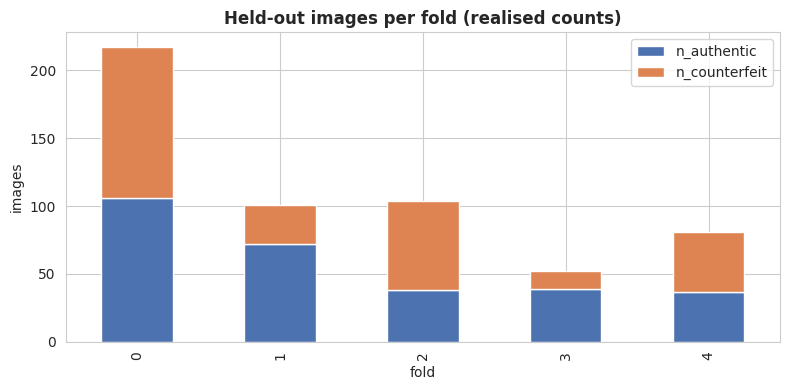

In [13]:
# ==============================================================================
# SECTION 5: FOLD ASSIGNMENT, SAVED ONCE
# ==============================================================================
# CHAPTER 3: Data Partitioning
log_stage("Section 5: creating or loading the fixed folds")
pool_df = data[data.split == "pool"].sort_values("image_id").reset_index(drop=True)
test_df = data[data.split == "test"].sort_values("image_id").reset_index(drop=True)
strat = (pool_df["label"].astype(str) + "_" + pool_df["brand"].astype(str)) if HAS_BRAND else pool_df["label"].astype(str)

def _fold_balance_score(fold, pool):
    """Lower is better: spread of the held-out fold sizes plus the worst deviation of a fold's counterfeit share from the pool share."""
    sizes = np.array([(fold == k).sum() for k in range(N_FOLDS)], dtype=float)
    share = np.array([pool.loc[fold == k, "label"].mean() if (fold == k).any() else 0.0 for k in range(N_FOLDS)])
    return float(sizes.std() / sizes.mean() + 2 * np.abs(share - pool["label"].mean()).max())

def _search_fold_assignment(pool):
    """StratifiedGroupKFold with FOLD_SEED_SEARCH different seeds; keep the assignment with the most even fold sizes and class shares.
    The groups are unchanged, so every grouping rule still holds. Only the random assignment of whole groups to folds is chosen."""
    best = None
    for s in range(max(1, FOLD_SEED_SEARCH)):
        seed = FOLD_SEED + s
        sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
        fold = np.full(len(pool), -1)
        for k, (_, te) in enumerate(sgkf.split(pool, strat, pool["group_id"])): fold[te] = k
        sc = _fold_balance_score(fold, pool)
        if best is None or sc < best[0]: best = (sc, seed, fold)
    return best

def _pick_val(pool, tr, seed_base):
    """Choose the validation images inside one training portion (positions in tr). Candidates are the inner StratifiedGroupKFold splits of
    VAL_SEED_SEARCH seeds. The best candidate is the one closest to VAL_TARGET_N images with a class mix like the training portion;
    candidates under VAL_MIN_N images or VAL_MIN_PER_CLASS per class are heavily penalised. Groups never cross validation and training."""
    lab = pool["label"].values; best = None
    for s in range(max(1, VAL_SEED_SEARCH)):
        inner = StratifiedGroupKFold(n_splits=VAL_INNER_SPLITS, shuffle=True, random_state=seed_base + s)
        for _, vl in inner.split(pool.iloc[tr], strat.iloc[tr], pool["group_id"].iloc[tr]):
            y = lab[tr[vl]]; n = len(vl); n1 = int(y.sum()); n0 = n - n1
            pen = abs(n - VAL_TARGET_N) / VAL_TARGET_N + 2 * abs(n1 / max(n, 1) - lab[tr].mean())
            if n < VAL_MIN_N or min(n0, n1) < VAL_MIN_PER_CLASS: pen += 10
            if best is None or pen < best[0]: best = (pen, vl)
    return best[1]

def make_folds(pool):
    """Create the five held-out folds with StratifiedGroupKFold (stratified on class and brand, grouped by group_id; the most balanced of
    FOLD_SEED_SEARCH seeds), then a validation split inside each training portion by the same grouped procedure (_pick_val).
    Returns one row per pool image with its fold and its role (train/val/heldout) in every fold."""
    sc, seed, fold = _search_fold_assignment(pool)
    print(f"    fold seed {seed} chosen out of {max(1, FOLD_SEED_SEARCH)} (balance score {sc:.3f}); held-out sizes {[int((fold == k).sum()) for k in range(N_FOLDS)]}")
    roles = {}
    for k in range(N_FOLDS):
        role = np.array(["heldout" if f == k else "train" for f in fold], dtype=object)
        tr = np.where(fold != k)[0]
        val_loc = _pick_val(pool, tr, FOLD_SEED + 1000 * (k + 1))
        role[tr[val_loc]] = "val"
        roles[f"role_f{k}"] = role
    return pd.DataFrame({"image_id": pool["image_id"], "fold": fold, **roles})

fold_path_out = f"{TAB}/fold_assignments.csv"
if FOLD_FILE_INPUT and os.path.exists(FOLD_FILE_INPUT):
    folds = pd.read_csv(FOLD_FILE_INPUT)
    assert set(folds.image_id) == set(pool_df.image_id), "FOLD_FILE_INPUT does not match the current pool images"
    print("[*] Loaded shared fold assignments from", FOLD_FILE_INPUT)
else:
    folds = make_folds(pool_df)
    print("[*] Created fold assignments (the fold seed was searched from %d, see the line above)" % FOLD_SEED)
folds.to_csv(fold_path_out, index=False)
pool_df = pool_df.merge(folds, on="image_id", how="left")

# ---- assertions -----------------------------------------------------------
assert (pool_df["fold"] >= 0).all()
for k in range(N_FOLDS):
    role = pool_df[f"role_f{k}"]
    g_held, g_val, g_tr = (set(pool_df.loc[role == r, "group_id"]) for r in ["heldout", "val", "train"])
    assert not (g_held & (g_val | g_tr)), f"fold {k}: a group appears in held-out and training/validation"
    assert not (g_val & g_tr), f"fold {k}: a group appears in both validation and training"
    assert (role == "heldout").sum() == (pool_df["fold"] == k).sum()
    if HAS_SELLER:
        s = pool_df["seller"].astype(str).str.lower()
        assert not (set(s[role == "heldout"]) & set(s[role != "heldout"]) - {"nan", "unknown", "none", ""}), f"fold {k}: seller leakage"
FOLD_ASSERTIONS_PASSED = True      # reaching this line means every assertion above held
print("[✓] Fold assertions passed: no group (or seller) crosses held-out, validation, and training; pool and test share no MD5.")

# ---- validation sets must be usable (a tiny or one-class validation set breaks the threshold and early stopping) ----------
_bad = []
for k in range(N_FOLDS):
    _v = pool_df[pool_df[f"role_f{k}"] == "val"]; _n1 = int((_v.label == 1).sum()); _n0 = len(_v) - _n1
    if len(_v) < VAL_MIN_N or min(_n0, _n1) < VAL_MIN_PER_CLASS: _bad.append((k, len(_v), _n0, _n1))
if _bad:
    print(f"[!] Validation sets below the minimum (fold, n, authentic, counterfeit): {_bad}. Their thresholds fall back to 0.5 and their AUC is unreliable.")
else:
    print(f"[✓] Every validation set has at least {VAL_MIN_N} images and {VAL_MIN_PER_CLASS} per class.")

# ---- realised counts and tier balance -------------------------------------
rows = []
for k in range(N_FOLDS):
    for r in ["train", "val", "heldout"]:
        s = pool_df[pool_df[f"role_f{k}"] == r]
        rows.append(dict(fold=k, role=r, n=len(s), n_authentic=int((s.label == 0).sum()), n_counterfeit=int((s.label == 1).sum()),
                         n_plain=int((s.tier == "Plain").sum()), n_uncontrolled=int((s.tier == "Uncontrolled").sum()), tier_source=TIER_SOURCE))
fold_comp = pd.DataFrame(rows)
savetab(fold_comp, "table_fold_composition.csv")
print(fold_comp.pivot(index="fold", columns="role", values="n"))

fig, ax = plt.subplots(figsize=(8, 4))
hc = fold_comp[fold_comp.role == "heldout"].set_index("fold")[["n_authentic", "n_counterfeit"]]
hc.plot(kind="bar", stacked=True, ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_title("Held-out images per fold (realised counts)", fontweight="bold"); ax.set_ylabel("images")
savefig("05_fold_composition.png")

savetab(data.groupby(["split", "cls", "brand"]).size().rename("n_images").reset_index(), "table_dataset_composition_final.csv")

## 6. Normalization, augmentation, dataset, models, and the training engine

> **Chapter 3 reference:** Normalization, Data Augmentation, Data Partitioning (sampler), Model Architecture, Model Training and Optimization
>
> **What the chapter requires**
> - Normalization: scale to [0, 1], then subtract the ImageNet channel means and divide by the ImageNet standard deviations.
> - Augmentation on the training set only, identical for both classes: rotation within 5 degrees, brightness and contrast within 10%, small random zooms, JPEG recompression at quality 70 to 95 together with random blur and downscale-then-upscale. No horizontal flip. No augmentation on validation or test.
> - A weighted random sampler on the training loader only.
> - Three ImageNet-pretrained networks (ResNet50, EfficientNetB0, MobileNetV2) adapted for binary classification.
> - Two-phase transfer learning: head only with a frozen backbone, then the upper layers unfrozen. Adam at 1e-3 then 1e-4, no learning-rate scheduler, batch size 32, binary cross-entropy, counterfeit is the positive class, dropout 0.4 before the final layer.
> - Mixed precision and a smaller batch size only if GPU memory requires it, applied identically to all three models.
> - Early stopping in phase 2 only (10 epochs without validation-loss improvement), restoring the weights with the lowest validation loss.
> - Threshold: Youden's J on the validation set, fixed before the held-out fold or the test set is scored.
>
> **Where it is implemented:** `TRAIN_TF`/`EVAL_TF`, `RandomJPEG`, `RandomBlur`, `RandomDownUp`, `WatchDataset`, `make_loader`, `build_model`, `set_phase`, `fit_model`, `youden_threshold`.
>
> **Outputs:** `05b_augmentation_examples.png`
>
> **Choices the chapter leaves open (made here)**
> - The five augmentation groups are rotation, brightness and contrast, zoom, JPEG recompression, and blur together with downscale-then-upscale. Zoom is within 8%, blur sigma 0.1 to 1.0, downscale factor 0.5 to 0.9, applied with probability 0.5 (JPEG) or 0.3 (blur and downscale).
> - Epoch limits: 10 in phase 1 and up to 20 in phase 2 (the chapter does not state epoch counts).
> - Unfrozen blocks in phase 2: ResNet50 `layer4[-1]`, EfficientNetB0 `features[7:]`, MobileNetV2 `features[17:]` (the chapter does not name them; `UNFREEZE_MODE = "chapter"` restores the larger `layer4`, `features[6:]`, `features[14:]`). D17 also lowers the backbone learning rate to 0.1x the head's, adds Adam weight decay 1e-4 and label smoothing 0.1 (training loss only), and keeps ImageNet BatchNorm statistics in frozen layers.
> - Augmentation strengths are wider by default (`AUG_STRENGTH = "strong"`, D18): rotation 8, translation 4%, zoom 10%, brightness and contrast 20%, saturation 15%, JPEG 50 to 95 (p 0.7), blur (p 0.4), downscale 0.4 to 0.9 (p 0.4). `"chapter"` restores the first run's values.
> - The threshold is Youden's J on validation, but a one-class validation set or a theta outside 0.10 to 0.90 falls back to 0.5 and is flagged (D16).
> - Mixed precision (fp16) is switched on for every architecture when a GPU is present.

- **Normalization:** ImageNet mean and standard deviation (the models use ImageNet weights).
- **Augmentation (training only, same for both classes):** rotation of at most 5 degrees, zoom of about 8%, brightness and contrast of 10%, random JPEG recompression (quality 70 to 95), random blur, and random downscale then upscale. No horizontal flip (it would mirror dial printing and logos), and colour changes stay small because dial colour is a legitimate cue. Validation and test images are never augmented.
- **Sampling:** a weighted random sampler on the training loader only, as a safeguard against residual imbalance.
- **Models:** ImageNet-pretrained backbone, head = `Dropout(0.4)` then `Linear(…, 1)`, `BCEWithLogitsLoss`, counterfeit = positive class.
- **Two-phase transfer learning:** Phase 1 trains the head with the backbone frozen (Adam, 1e-3). Phase 2 unfreezes the top blocks (Adam, 1e-4). Early stopping applies to Phase 2 only, on validation loss, and the best-validation-loss weights are restored. No LR scheduler.
- **Threshold:** Youden's J on the validation set, fixed before the held-out fold or the external test set is scored.

In [14]:
# ==============================================================================
# SECTION 6A: AUGMENTATION, DATASET, LOADERS
# ==============================================================================
# CHAPTER 3: Normalization and Data Augmentation
class RandomJPEG:
    """Random JPEG recompression, quality 70-95 (Chapter 3: Data Augmentation)."""
    def __init__(self, q=(70, 95), p=0.5): self.q, self.p = q, p
    def __call__(self, img):
        if random.random() > self.p: return img
        buf = io.BytesIO(); img.save(buf, "JPEG", quality=random.randint(*self.q)); buf.seek(0)
        return Image.open(buf).convert("RGB")

class RandomBlur:
    """Random Gaussian blur (Chapter 3: Data Augmentation)."""
    def __init__(self, sigma=(0.1, 1.0), p=0.3): self.sigma, self.p = sigma, p
    def __call__(self, img):
        return img.filter(ImageFilter.GaussianBlur(random.uniform(*self.sigma))) if random.random() < self.p else img

class RandomDownUp:
    """Random downscale then upscale (Chapter 3: Data Augmentation)."""
    def __init__(self, scale=(0.5, 0.9), p=0.3): self.scale, self.p = scale, p
    def __call__(self, img):
        if random.random() > self.p: return img
        w, h = img.size; s = random.uniform(*self.scale)
        return img.resize((max(8, int(w * s)), max(8, int(h * s))), Image.BILINEAR).resize((w, h), Image.BILINEAR)

NORM = T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
if AUG_STRENGTH == "strong":
    # D18: wider photo-style variation (JPEG, blur, resolution, brightness, saturation) so the network cannot lean on how a photo was taken.
    TRAIN_TF = T.Compose([T.RandomAffine(degrees=8, translate=(0.04, 0.04), scale=(0.90, 1.10), fill=BG_FILL),
                          T.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.15, hue=0.02),
                          RandomJPEG(q=(50, 95), p=0.7), RandomBlur(sigma=(0.1, 1.5), p=0.4), RandomDownUp(scale=(0.4, 0.9), p=0.4),
                          T.ToTensor(), NORM])
else:   # chapter values
    TRAIN_TF = T.Compose([T.RandomAffine(degrees=5, scale=(0.92, 1.08), fill=BG_FILL),
                          T.ColorJitter(brightness=0.10, contrast=0.10),
                          RandomJPEG(), RandomBlur(), RandomDownUp(), T.ToTensor(), NORM])
EVAL_TF = T.Compose([T.ToTensor(), NORM])

ARRAY_CACHE = {}
def get_array(path, size):
    """Load an image once into RAM as a uint8 RGB array (area-resized if size differs from the file)."""
    key = (path, size)
    if key not in ARRAY_CACHE:
        a = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        if a.shape[0] != size or a.shape[1] != size:
            a = cv2.resize(a, (size, size), interpolation=cv2.INTER_AREA)   # area interpolation, never upscales 320 -> larger
        ARRAY_CACHE[key] = a
    return ARRAY_CACHE[key]

class WatchDataset(Dataset):
    """Dataset of cached 320x320 images. border_only blanks the centre (shortcut baseline 5)."""
    def __init__(self, frame, path_col="proc_path", size=INPUT_SIZE, train=False, border_only=False):
        self.paths = frame[path_col].tolist(); self.labels = frame["label"].values.astype(np.float32)
        self.size, self.tf, self.border = size, (TRAIN_TF if train else EVAL_TF), border_only
        for p in self.paths: get_array(p, size)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        x = self.tf(Image.fromarray(ARRAY_CACHE[(self.paths[i], self.size)]))
        if self.border:
            m = int(self.size * BORDER_FRAC); x[:, m:self.size - m, m:self.size - m] = 0   # zero = ImageNet mean colour
        return x, torch.tensor(self.labels[i]), i

def make_loader(frame, path_col="proc_path", size=INPUT_SIZE, train=False, seed=0, border_only=False, batch_size=None):
    """Build a DataLoader. Training loaders use augmentation and a WeightedRandomSampler (Chapter 3: Data Partitioning); validation and test loaders are unweighted and never augmented."""
    bs = batch_size or (BATCH_SIZE if train else 64)
    ds = WatchDataset(frame, path_col, size, train, border_only)
    pin = device.type == "cuda"
    if train:
        lab = frame["label"].values.astype(int); w = 1.0 / np.bincount(lab)[lab]
        g = torch.Generator(); g.manual_seed(seed)
        sampler = WeightedRandomSampler(torch.DoubleTensor(w), num_samples=len(ds), replacement=True, generator=g)
        return DataLoader(ds, batch_size=bs, sampler=sampler, num_workers=NUM_WORKERS, pin_memory=pin,
                          drop_last=(len(ds) % bs == 1), generator=g)
    return DataLoader(ds, batch_size=bs, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

### Preload images into memory

All processed images are decoded once and kept in RAM (about 250 MB per image variant), so training epochs never wait on disk reads. The bar below is the only slow part; it runs once per session.

In [15]:
# ==============================================================================
# SECTION 6A1: PRELOAD IMAGES INTO RAM (progress bar)
# ==============================================================================
# CHAPTER 3: Model Training and Optimization (data loading)
log_stage("Section 6: preloading images into memory")
_variants = [("proc_path", INPUT_SIZE)]
if RUN_RESOLUTION_CHECK: _variants.append(("proc_path", 224))
if RUN_SHORTCUT_AUDIT and RUN_BORDER_CNN and PREPROCESS_MODE != "already_processed": _variants.append(("raw320_path", INPUT_SIZE))
for _col, _sz in _variants:
    for _p in tqdm(pd.concat([pool_df[_col], test_df[_col]]).unique(), desc=f"preload {_col} @ {_sz}px", leave=False):
        get_array(_p, _sz)
print(f"[✓] {len(ARRAY_CACHE)} image arrays cached in RAM")


[03:21:11 | + 12.9 min] Section 6: preloading images into memory


preload proc_path @ 320px:   0%|          | 0/735 [00:00<?, ?it/s]

preload proc_path @ 224px:   0%|          | 0/735 [00:00<?, ?it/s]

preload raw320_path @ 320px:   0%|          | 0/735 [00:00<?, ?it/s]

[✓] 2205 image arrays cached in RAM


### Augmentation preview

The first figure shows each training augmentation on its own at a fixed strength, then two random draws of the full training pipeline, for one authentic and two counterfeit pool images. The second figure shows twelve random draws of the full pipeline for a single image. Nothing here is saved to the training data; it only documents what the models see.

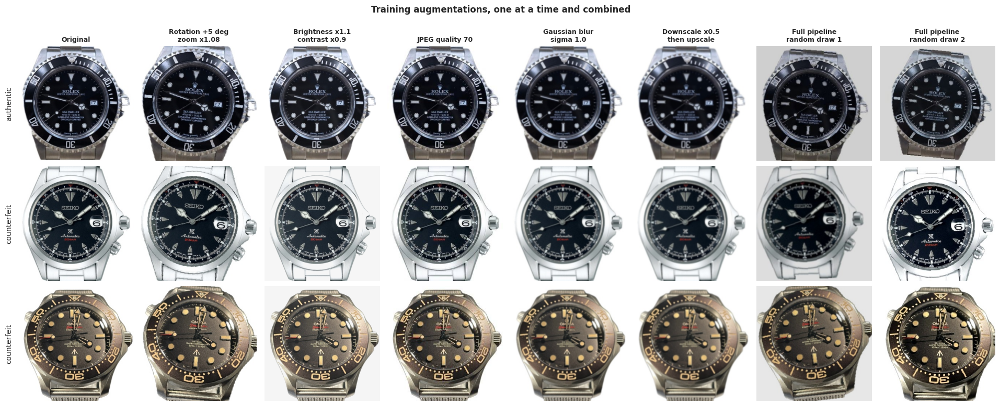

In [16]:
# ==============================================================================
# SECTION 6A2: AUGMENTATION PREVIEW (figures only)
# ==============================================================================
# CHAPTER 3: Data Augmentation
def show_augmentation(seed=3):
    """Draw the two augmentation preview figures (each augmentation alone, then random draws of the full pipeline)."""
    random.seed(seed); torch.manual_seed(seed)
    picks = [pool_df[pool_df.label == 0].sample(1, random_state=seed).iloc[0],
             pool_df[pool_df.label == 1].sample(1, random_state=seed).iloc[0],
             pool_df[pool_df.label == 1].sample(1, random_state=seed + 1).iloc[0]]
    full = T.Compose(TRAIN_TF.transforms[:-2])            # the training pipeline without ToTensor and Normalize
    ops = [("Original", None),
           ("Rotation +5 deg\nzoom x1.08", T.RandomAffine(degrees=(5, 5), scale=(1.08, 1.08), fill=BG_FILL)),
           ("Brightness x1.1\ncontrast x0.9", T.ColorJitter(brightness=(1.1, 1.1), contrast=(0.9, 0.9))),
           ("JPEG quality 70", RandomJPEG((70, 70), p=1.0)),
           ("Gaussian blur\nsigma 1.0", RandomBlur((1.0, 1.0), p=1.0)),
           ("Downscale x0.5\nthen upscale", RandomDownUp((0.5, 0.5), p=1.0)),
           ("Full pipeline\nrandom draw 1", full), ("Full pipeline\nrandom draw 2", full)]
    fig, axes = plt.subplots(len(picks), len(ops), figsize=(2.4 * len(ops), 2.6 * len(picks)))
    for r, row in enumerate(picks):
        base = Image.fromarray(get_array(row.proc_path, INPUT_SIZE))
        for c, (name, op) in enumerate(ops):
            ax = axes[r, c]; ax.imshow(base if op is None else op(base)); ax.axis("off")
            if r == 0: ax.set_title(name, fontsize=9, fontweight="bold")
            if c == 0: ax.text(-0.05, 0.5, row.cls, transform=ax.transAxes, rotation=90, va="center", ha="right", fontsize=10)
    fig.suptitle("Training augmentations, one at a time and combined", fontweight="bold", y=1.0)
    savefig("05b_augmentation_examples.png")


show_augmentation()

In [17]:
# ==============================================================================
# SECTION 6B: MODELS, FREEZING PHASES, CHECKPOINT LOADERS
# ==============================================================================
# CHAPTER 3: Model Architecture
def build_model(arch, pretrained=PRETRAINED):
    """ImageNet-pretrained backbone plus a Dropout(0.4) and Linear(., 1) head (Chapter 3: Model Architecture and Model Training). One logit = counterfeit."""
    if arch == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        m.fc = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.fc.in_features, 1))
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.classifier[1].in_features, 1))
    elif arch == "mobilenet_v2":
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V2 if pretrained else None)
        m.classifier = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.classifier[1].in_features, 1))
    else:
        raise ValueError(arch)
    return m.to(device)

def head_of(m, arch): return m.fc if arch == "resnet50" else m.classifier

def gradcam_layer(m, arch):
    """The final convolutional block used for Grad-CAM (Chapter 3: Grad-CAM)."""
    return m.layer4[-1] if arch == "resnet50" else m.features[-1]

def set_phase(m, arch, phase):
    """Phase 1: only the head trains. Phase 2: head plus the upper blocks. UNFREEZE_MODE = chapter: ResNet50 layer4, EfficientNetB0 features[6:], MobileNetV2 features[14:]; last_block: ResNet50 layer4[-1], EfficientNetB0 features[7:], MobileNetV2 features[17:]."""
    for p in m.parameters(): p.requires_grad = False
    for p in head_of(m, arch).parameters(): p.requires_grad = True
    if phase == 2:
        if UNFREEZE_MODE == "chapter":
            top = {"resnet50": lambda: m.layer4, "efficientnet_b0": lambda: m.features[6:], "mobilenet_v2": lambda: m.features[14:]}[arch]()
        else:   # D17: only the last block plus the final convolution, so far fewer weights can overfit 400-odd images
            top = {"resnet50": lambda: m.layer4[-1], "efficientnet_b0": lambda: m.features[7:], "mobilenet_v2": lambda: m.features[17:]}[arch]()
        for p in top.parameters(): p.requires_grad = True

def load_checkpoint_pth(path):
    """Load a .pth checkpoint (state dict + metadata). Returns (model in eval mode, metadata dict that includes the frozen threshold)."""
    ck = torch.load(path, map_location="cpu", weights_only=False)
    m = build_model(ck["arch"], pretrained=False); m.load_state_dict(ck["state_dict"])
    return m.to(device).eval(), ck

def load_checkpoint_pt(path):
    """Load a .pt checkpoint (the full pickled model)."""
    return torch.load(path, map_location=device, weights_only=False).eval()

In [18]:
# ==============================================================================
# SECTION 6C: TRAINING ENGINE
# ==============================================================================
# CHAPTER 3: Model Training and Optimization
def run_epoch(model, loader, crit, opt, scaler):
    """One training epoch with optional mixed precision. Returns (mean loss, accuracy at 0.5)."""
    model.train(); tot = correct = n = 0
    if FREEZE_BN_STATS:     # D17: layers with no trainable weights keep their ImageNet BatchNorm statistics instead of drifting with 400 images
        for mod in model.modules():
            if isinstance(mod, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in mod.parameters(recurse=False)):
                mod.eval()
    for x, y, _ in loader:
        x = x.to(device, non_blocking=True); y = y.float().unsqueeze(1).to(device)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=AMP_ON):
            out = model(x)
        y_t = y * (1 - LABEL_SMOOTHING) + 0.5 * LABEL_SMOOTHING if LABEL_SMOOTHING > 0 else y   # D17: smoothed targets, training loss only
        loss = crit(out.float(), y_t)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item() * x.size(0); correct += ((out.detach().float() > 0).float() == y).sum().item(); n += x.size(0)
    return tot / n, correct / n

@torch.no_grad()
def predict(model, loader, crit=None):
    """Return (probabilities of counterfeit, labels, mean loss if crit given) with no gradients."""
    model.eval(); probs, ys, tot, n = [], [], 0.0, 0
    for x, y, _ in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=AMP_ON):
            out = model(x)
        out = out.float()
        probs.append(torch.sigmoid(out).squeeze(1).cpu().numpy()); ys.append(y.numpy())
        if crit is not None:
            tot += crit(out, y.float().unsqueeze(1).to(device)).item() * x.size(0)
        n += x.size(0)
    return np.concatenate(probs), np.concatenate(ys), (tot / n if crit is not None else None)

def safe_auc(y, p):
    """ROC-AUC, or NaN when only one class is present."""
    return float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else float("nan")

def youden_threshold_raw(y, p):
    """Threshold that maximises Youden's J = sensitivity + specificity - 1 on the validation set (Chapter 3: Model Training and Optimization). NaN when only one class is present."""
    if len(np.unique(y)) < 2: return float("nan")
    fpr, tpr, thr = roc_curve(y, p); j = tpr - fpr
    j[~np.isfinite(thr) | (thr > 1.0)] = -np.inf
    return float(thr[int(np.argmax(j))])

def choose_threshold(y, p):
    """D16: Youden's J from the validation set, with a safety net. A one-class validation set or a threshold outside THETA_BOUNDS (the
    degenerate theta of about 1.0 that made a model call everything authentic) falls back to 0.5. Returns (theta, used_fallback, raw_theta)."""
    raw = youden_threshold_raw(y, p)
    if not np.isfinite(raw) or not (THETA_BOUNDS[0] <= raw <= THETA_BOUNDS[1]):
        return 0.5, True, raw
    return raw, False, raw

def youden_threshold(y, p):
    """Frozen threshold for one model (see choose_threshold)."""
    return choose_threshold(y, p)[0]

def metrics_at(y, p, th):
    """Accuracy, precision, recall, F1 (counterfeit = positive) at threshold th, and ROC-AUC (threshold-free)."""
    pred = (p >= th).astype(int)
    return dict(accuracy=float(accuracy_score(y, pred)), precision=float(precision_score(y, pred, zero_division=0)),
                recall=float(recall_score(y, pred, zero_division=0)), f1=float(f1_score(y, pred, zero_division=0)),
                roc_auc=safe_auc(y, p))

def _make_scaler():
    """Mixed-precision gradient scaler (works on current and older PyTorch)."""
    try:
        return torch.amp.GradScaler("cuda", enabled=AMP_ON)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=AMP_ON)

def _make_optimizer(model, arch, lr):
    """Adam on the trainable weights. The head learns at lr; unfrozen backbone blocks learn at lr x PHASE2_BACKBONE_LR_MULT (D17); weight decay WEIGHT_DECAY."""
    head_params = list(head_of(model, arch).parameters()); head_ids = {id(q) for q in head_params}
    body_params = [q for q in model.parameters() if q.requires_grad and id(q) not in head_ids]
    groups = [{"params": head_params, "lr": lr}]
    if body_params: groups.append({"params": body_params, "lr": lr * PHASE2_BACKBONE_LR_MULT})
    return optim.Adam(groups, weight_decay=WEIGHT_DECAY)

def fit_model(arch, tr_loader, va_loader, p1_epochs, p2_epochs, patience, verbose=True, tag="", progress=True):
    """Two-phase transfer learning (Chapter 3: Model Training and Optimization). Phase 1 trains the head at PHASE1_LR; phase 2 unfreezes the upper blocks at PHASE2_LR. Early stopping on validation loss applies to phase 2 only, and the weights with the lowest validation loss are restored. Returns (model, history table, best-epoch summary)."""
    model = build_model(arch); crit = nn.BCEWithLogitsLoss(); scaler = _make_scaler()
    hist, best_loss, best_state, best = [], float("inf"), None, {}
    g_ep = 0
    pbar = tqdm(total=p1_epochs + p2_epochs, desc=(tag.strip() or "training"), leave=False, disable=not progress)
    for phase, n_ep, lr in [(1, p1_epochs, PHASE1_LR), (2, p2_epochs, PHASE2_LR)]:
        set_phase(model, arch, phase)
        opt = _make_optimizer(model, arch, lr)
        no_imp = 0
        for ep in range(n_ep):
            t0 = time.time(); g_ep += 1
            tr_loss, tr_acc = run_epoch(model, tr_loader, crit, opt, scaler)
            pv, yv, va_loss = predict(model, va_loader, crit)
            row = dict(epoch=g_ep, phase=phase, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss,
                       val_acc=float(((pv >= 0.5) == yv).mean()), val_auc=safe_auc(yv, pv), epoch_sec=time.time() - t0)
            hist.append(row)
            pbar.update(1); pbar.set_postfix(phase=phase, trn=f"{tr_loss:.3f}", val=f"{va_loss:.3f}", auc=f"{row['val_auc']:.3f}")
            if verbose:
                tqdm.write(f"  {tag}[P{phase}] ep {g_ep:>2} {row['epoch_sec']:.1f}s | trn {tr_loss:.4f}/{tr_acc:.3f} | val {va_loss:.4f}/{row['val_acc']:.3f} auc {row['val_auc']:.3f}")
            if phase == 2:
                if va_loss < best_loss:
                    best_loss, no_imp = va_loss, 0
                    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
                    best = dict(best_epoch=g_ep, best_val_loss=va_loss, best_val_auc=row["val_auc"])
                else:
                    no_imp += 1
                    if no_imp >= patience:
                        if verbose: tqdm.write(f"  {tag}[early stop] no val-loss improvement for {patience} epochs")
                        pbar.total = g_ep; pbar.refresh()
                        break
    pbar.close()
    if best_state is not None:
        model.load_state_dict(best_state)
    else:
        best = dict(best_epoch=g_ep, best_val_loss=hist[-1]["val_loss"], best_val_auc=hist[-1]["val_auc"])
    return model, pd.DataFrame(hist), best

def fold_frames(k):
    """Return the (train, validation, held-out) pool images of fold k."""
    r = pool_df[f"role_f{k}"]
    return pool_df[r == "train"].reset_index(drop=True), pool_df[r == "val"].reset_index(drop=True), pool_df[r == "heldout"].reset_index(drop=True)

## 7. Shortcut audit (run before any model result is produced)

> **Chapter 3 reference:** Shortcut Audit
>
> **What the chapter requires**
> - Run before any model result exists, with the same grouped folds as the models, against an accuracy threshold of about 65%.
> - Five baselines: (1) file size and re-encode ratio, (2) original resolution, blur score, brightness, color histogram, and estimated JPEG quality, (3) mask area and shape, (4) background tier alone, (5) a border-only CNN run on the raw images and on the processed images.
> - If any baseline exceeds about 65%, rebalance sources or tiers, or drop the leaking attribute, and repeat the audit.
>
> **Where it is implemented:** `BASELINES`, `tab_baseline`, `border_cnn_audit`.
>
> **Outputs:** `table_shortcut_audit.csv`, `table_shortcut_feature_importance.csv`, `06_shortcut_audit.png`
>
> **Choices the chapter leaves open (made here)**
> - Tabular baselines use a 300-tree random forest. The re-encode ratio is the size of the image re-saved at JPEG 95 divided by the original file size.
> - The border-only CNN is a MobileNetV2 trained briefly (3 + up to 10 epochs); only the outer 20% band of each side is visible (`BORDER_FRAC`).
> - The notebook flags a baseline above 65% but does not rebalance anything by itself; that decision is yours.
> - B1 and B2 measure the original files, which the CNN never sees. B1p and B2p (D18) repeat them on the processed images the CNN does see, so a flag there is a shortcut the CNN can use.

The audit asks whether photo style alone can predict the class, using the **same grouped folds** as the models. Each baseline is trained on the training and validation images of a fold and scored on its held-out fold.

1. File size and re-encode ratio (size of the image re-saved at JPEG 95 divided by the original file size)
2. Original resolution, blur score, brightness, colour histogram, estimated JPEG quality
3. Mask area and shape
4. Background tier alone
5. Border-only CNN, on the **raw** (non-isolated) 320 px images and on the **processed** images (the centre is blanked, so only the outer band is visible)

Anything above about 65% accuracy is flagged. If a baseline is flagged, rebalance sources or tiers (or drop the leaking attribute) and re-run from Section 1.

**Reading the flags:** B1 and B2 describe the raw data. B1p, B2p and B5 on processed images describe what the CNN can actually exploit. Compare the CNN's held-out AUC with the B2p AUC before claiming the CNN learned watch features.


In [19]:
# ==============================================================================
# SECTION 7A: TABULAR SHORTCUT BASELINES
# ==============================================================================
# CHAPTER 3: Shortcut Audit (baselines 1-4)
hist_cols = [f"hist_{i}" for i in range(24)]

# D18: B1 and B2 above measure the ORIGINAL files, which the CNN never sees (it sees the processed 320 px, quality-95, white-background images).
# B1p and B2p repeat them on the PROCESSED images. Only a high score on B1p, B2p, or the processed border CNN is a shortcut open to the CNN.
phist_cols = [f"phist_{i}" for i in range(24)]
def proc_features(path):
    """Style features of one processed image: file size, sharpness, brightness, contrast, white-background share, edge density, colour histogram."""
    raw = open(path, "rb").read(); img = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    out = dict(p_file_size=len(raw), p_lap_var=float(cv2.Laplacian(gray, cv2.CV_64F).var()), p_brightness=float(gray.mean()), p_contrast=float(gray.std()),
               p_white_frac=float((img.min(axis=2) >= 245).mean()), p_edge_density=float((cv2.Canny(gray, 100, 200) > 0).mean()))
    for ch in range(3):
        hh = cv2.calcHist([img], [ch], None, [8], [0, 256]).flatten(); hh = hh / hh.sum()
        out.update({f"phist_{ch * 8 + i}": float(v) for i, v in enumerate(hh)})
    return out

if RUN_SHORTCUT_AUDIT:
    with ThreadPoolExecutor(max_workers=NUM_WORKERS) as _ex:
        _pf = pd.DataFrame(list(tqdm(_ex.map(proc_features, pool_df["proc_path"].tolist()), total=len(pool_df), desc="processed-image features", leave=False)))
    for _c in _pf.columns: pool_df[_c] = _pf[_c].values

BASELINES = {
    "B1 file size + re-encode ratio": ["file_size", "reencode_ratio"],
    "B2 resolution, blur, brightness, colour histogram, JPEG quality":
        ["orig_w", "orig_h", "short_side", "aspect", "lap_var", "brightness", "jpeg_quality", "is_jpeg"] + hist_cols,
    "B1p file size of the PROCESSED image (what the CNN sees)": ["p_file_size"],
    "B2p PROCESSED image: size, sharpness, brightness, contrast, white share, edges, colour histogram":
        ["p_file_size", "p_lap_var", "p_brightness", "p_contrast", "p_white_frac", "p_edge_density"] + phist_cols,
}
if "mask_area_frac" in pool_df.columns and pool_df["mask_area_frac"].notna().any():
    BASELINES["B3 mask area + shape"] = ["mask_area_frac", "mask_bbox_aspect", "mask_extent", "mask_solidity"]
else:
    print("[!] No rembg masks (PREPROCESS_MODE != 'full'): baseline B3 skipped.")

def tab_baseline(X_all, name):
    """Shortcut baseline on a tabular feature matrix: for each fold, train a random forest on the training and validation images and score the held-out fold. Returns (accuracies, AUCs, mean feature importance)."""
    accs, aucs, imps = [], [], []
    for k in range(N_FOLDS):
        r = pool_df[f"role_f{k}"].values; tr, te = r != "heldout", r == "heldout"
        clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1)
        clf.fit(X_all[tr], pool_df.label.values[tr]); p = clf.predict_proba(X_all[te])[:, 1]
        accs.append(accuracy_score(pool_df.label.values[te], p >= 0.5)); aucs.append(safe_auc(pool_df.label.values[te], p))
        imps.append(clf.feature_importances_)
    return accs, aucs, np.mean(imps, axis=0)

audit_rows, imp_rows = [], []
if RUN_SHORTCUT_AUDIT:
    log_stage("Section 7: shortcut audit (tabular baselines)")
    for name, cols in tqdm(BASELINES.items(), desc="tabular baselines"):
        X = pool_df[cols].astype(float).fillna(-1).values
        a, u, imp = tab_baseline(X, name)
        audit_rows.append(dict(baseline=name, n_features=len(cols), mean_accuracy=np.mean(a), sd_accuracy=np.std(a), mean_auc=np.nanmean(u)))
        imp_rows += [dict(baseline=name, feature=c, importance=v) for c, v in zip(cols, imp)]
    if TIER_SOURCE != "unavailable":
        X = pd.get_dummies(pool_df["tier"]).astype(float).values
        a, u, _ = tab_baseline(X, "B4")
        audit_rows.append(dict(baseline=f"B4 background tier alone ({TIER_SOURCE})", n_features=X.shape[1],
                               mean_accuracy=np.mean(a), sd_accuracy=np.std(a), mean_auc=np.nanmean(u)))
    print(pd.DataFrame(audit_rows).round(3).to_string(index=False))
    if imp_rows:
        savetab(pd.DataFrame(imp_rows).sort_values(["baseline", "importance"], ascending=[True, False]), "table_shortcut_feature_importance.csv")

processed-image features:   0%|          | 0/555 [00:00<?, ?it/s]


[03:21:20 | + 13.0 min] Section 7: shortcut audit (tabular baselines)


tabular baselines:   0%|          | 0/5 [00:00<?, ?it/s]

                                                                                        baseline  n_features  mean_accuracy  sd_accuracy  mean_auc
                                                                  B1 file size + re-encode ratio           2          0.688        0.103     0.837
                                 B2 resolution, blur, brightness, colour histogram, JPEG quality          32          0.810        0.117     0.885
                                        B1p file size of the PROCESSED image (what the CNN sees)           1          0.509        0.050     0.571
B2p PROCESSED image: size, sharpness, brightness, contrast, white share, edges, colour histogram          30          0.607        0.067     0.666
                                                                            B3 mask area + shape           4          0.586        0.029     0.576
                                                             B4 background tier alone (metadata)           2          


[03:21:43 | + 13.4 min] Section 7: border-only CNN baseline
[*] Border-only CNN (mobilenet_v2) on raw images


border CNN folds (raw):   0%|          | 0/5 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth



  0%|          | 0.00/13.6M [00:00<?, ?B/s]
100%|██████████| 13.6M/13.6M [00:00<00:00, 102MB/s] 


training:   0%|          | 0/13 [00:00<?, ?it/s]

...

  [processed] fold 2: acc 0.712  auc 0.705


training:   0%|          | 0/13 [00:00<?, ?it/s]

  [processed] fold 3: acc 0.500  auc 0.542


training:   0%|          | 0/13 [00:00<?, ?it/s]

  [processed] fold 4: acc 0.519  auc 0.590


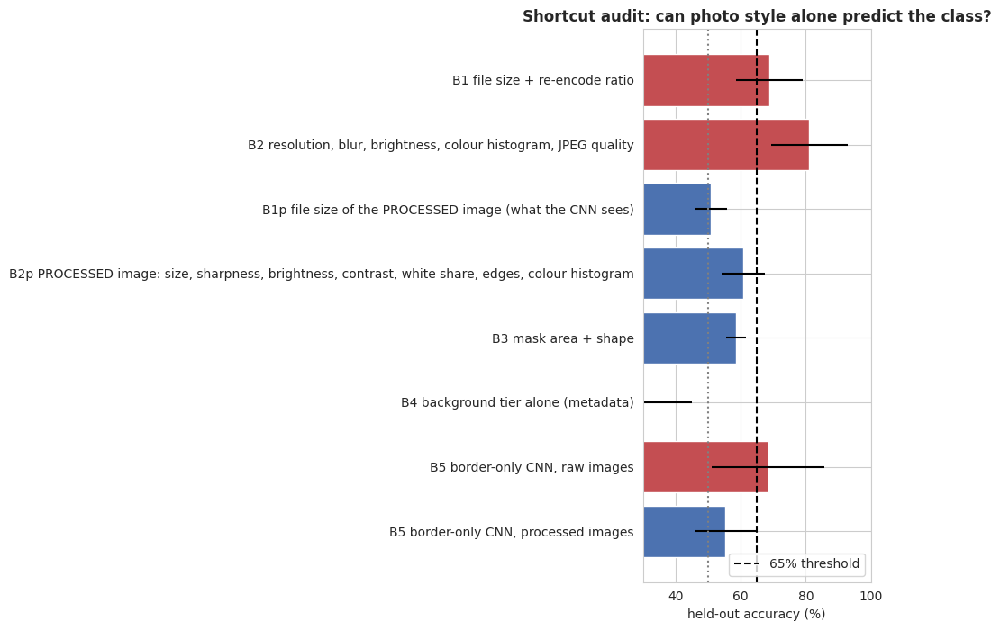


[!!] FLAGGED baselines above the threshold:
                                                        baseline  mean_accuracy
                                 B1 file size + re-encode ratio       0.687886
B2 resolution, blur, brightness, colour histogram, JPEG quality       0.810462
                                 B5 border-only CNN, raw images       0.684279
     Rebalance sources/tiers or drop the leaking attribute, then repeat the audit before trusting model results.
     Read the flags like this: B1 and B2 measure the ORIGINAL files, which the CNN never sees, so they show a problem in the raw data only.
     B1p, B2p and B5 (processed images) are the shortcuts the CNN can actually use. If those stay above the threshold and the dataset cannot
     be changed, report it as a limitation and compare the CNN's AUC with the B2p AUC before claiming the CNN learned watch features.


In [20]:
# ==============================================================================
# SECTION 7B: BORDER-ONLY CNN (raw and processed images)
# ==============================================================================
# CHAPTER 3: Shortcut Audit (baseline 5)
def border_cnn_audit(path_col, name):
    """Shortcut baseline 5: a CNN that sees only the outer border band. Same grouped folds; threshold from the validation set."""
    accs, aucs = [], []
    for k in tqdm(range(N_FOLDS), desc=f"border CNN folds ({name})"):
        tr, va, he = fold_frames(k); seed_everything(SEEDS[0])
        trl = make_loader(tr, path_col, INPUT_SIZE, True, SEEDS[0], border_only=True)
        val = make_loader(va, path_col, INPUT_SIZE, False, border_only=True)
        hel = make_loader(he, path_col, INPUT_SIZE, False, border_only=True)
        model, _, _ = fit_model(AUDIT_CNN_ARCH, trl, val, AUDIT_P1_EPOCHS, AUDIT_P2_EPOCHS, AUDIT_PATIENCE, verbose=False)
        pv, yv, _ = predict(model, val); th = youden_threshold(yv, pv); ph, yh, _ = predict(model, hel)
        accs.append(float(((ph >= th) == yh).mean())); aucs.append(safe_auc(yh, ph))
        tqdm.write(f"  [{name}] fold {k}: acc {accs[-1]:.3f}  auc {aucs[-1]:.3f}")
        del model; torch.cuda.empty_cache()
    return accs, aucs

if RUN_SHORTCUT_AUDIT and RUN_BORDER_CNN:
    log_stage("Section 7: border-only CNN baseline")
    variants = [("processed", "proc_path")]
    if PREPROCESS_MODE != "already_processed":
        variants.insert(0, ("raw", "raw320_path"))
    for vname, col in variants:
        print(f"[*] Border-only CNN ({AUDIT_CNN_ARCH}) on {vname} images")
        a, u = border_cnn_audit(col, vname)
        audit_rows.append(dict(baseline=f"B5 border-only CNN, {vname} images", n_features=np.nan,
                               mean_accuracy=np.mean(a), sd_accuracy=np.std(a), mean_auc=np.nanmean(u)))

if audit_rows:
    audit = pd.DataFrame(audit_rows); audit["threshold"] = AUDIT_THRESHOLD
    audit["flagged"] = audit["mean_accuracy"] > AUDIT_THRESHOLD
    savetab(audit, "table_shortcut_audit.csv")
    fig, ax = plt.subplots(figsize=(10, 0.7 * len(audit) + 1.5))
    ax.barh(audit["baseline"], audit["mean_accuracy"] * 100, xerr=audit["sd_accuracy"] * 100,
            color=np.where(audit["flagged"], "#C44E52", "#4C72B0"))
    ax.axvline(AUDIT_THRESHOLD * 100, color="k", ls="--", label=f"{AUDIT_THRESHOLD:.0%} threshold")
    ax.axvline(50, color="grey", ls=":"); ax.set_xlabel("held-out accuracy (%)"); ax.set_xlim(30, 100)
    ax.set_title("Shortcut audit: can photo style alone predict the class?", fontweight="bold"); ax.legend(); ax.invert_yaxis()
    savefig("06_shortcut_audit.png")
    if audit["flagged"].any():
        print("\n[!!] FLAGGED baselines above the threshold:\n", audit[audit.flagged][["baseline", "mean_accuracy"]].to_string(index=False))
        print("     Rebalance sources/tiers or drop the leaking attribute, then repeat the audit before trusting model results.")
        print("     Read the flags like this: B1 and B2 measure the ORIGINAL files, which the CNN never sees, so they show a problem in the raw data only.")
        print("     B1p, B2p and B5 (processed images) are the shortcuts the CNN can actually use. If those stay above the threshold and the dataset cannot")
        print("     be changed, report it as a limitation and compare the CNN's AUC with the B2p AUC before claiming the CNN learned watch features.")
    else:
        print("\n[✓] No baseline exceeded the audit threshold.")

## 8. Input resolution check, 224 vs 320 (validation data only)

> **Chapter 3 reference:** Resizing (resolution comparison)
>
> **What the chapter requires**
> - 224x224 and 320x320 are compared once, with one seed, on validation data only, and the chosen resolution is frozen before the external test set is used.
>
> **Where it is implemented:** the resolution-check cell, fold 0 and the first seed only.
>
> **Outputs:** `table_resolution_check.csv`
>
> **Choices the chapter leaves open (made here)**
> - The 224 variant is produced by area-downsampling the 320 processed images. The notebook never changes `INPUT_SIZE` on its own.

The chapter compares 224 and 320 once, with one seed, on validation data only, and freezes the choice before the external test set is used. This cell trains fold 0 of each architecture at both sizes and compares validation ROC-AUC and loss. It never touches the held-out fold or the test set. It does **not** change `INPUT_SIZE` for you: if 224 is clearly better, set `INPUT_SIZE = 224` in the configuration cell and re-run from the top.

In [21]:
# ==============================================================================
# SECTION 8: RESOLUTION CHECK (validation only)
# ==============================================================================
# CHAPTER 3: Resizing (224 vs 320 comparison)
if RUN_RESOLUTION_CHECK:
    log_stage("Section 8: resolution check (224 vs 320, validation only)")
    rc_rows = []
    tr, va, _ = fold_frames(0)
    for arch, size in tqdm([(a, s) for a in ARCHS_TO_RUN for s in (224, 320)], desc="resolution check"):
        if True:
            seed_everything(SEEDS[0])
            trl = make_loader(tr, "proc_path", size, True, SEEDS[0]); val = make_loader(va, "proc_path", size, False)
            model, h, best = fit_model(arch, trl, val, PHASE1_EPOCHS, PHASE2_EPOCHS, PATIENCE, verbose=False)
            rc_rows.append(dict(arch=arch, input_size=size, seed=SEEDS[0], fold=0, val_auc=best["best_val_auc"],
                                val_loss=best["best_val_loss"], best_epoch=best["best_epoch"]))
            print(rc_rows[-1]); del model; torch.cuda.empty_cache()
    rc = pd.DataFrame(rc_rows); savetab(rc, "table_resolution_check.csv")
    print(f"\nFrozen choice for the main runs: INPUT_SIZE = {INPUT_SIZE}. Change it in the configuration cell only if the table above clearly favours 224.")


[03:28:56 | + 20.6 min] Section 8: resolution check (224 vs 320, validation only)


resolution check:   0%|          | 0/2 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth



  0%|          | 0.00/20.5M [00:00<?, ?B/s]
100%|██████████| 20.5M/20.5M [00:00<00:00, 142MB/s] 


training:   0%|          | 0/30 [00:00<?, ?it/s]

{'arch': 'efficientnet_b0', 'input_size': 224, 'seed': 42, 'fold': 0, 'val_auc': 0.6013719512195121, 'val_loss': 0.6697782572001627, 'best_epoch': 14}


training:   0%|          | 0/30 [00:00<?, ?it/s]

{'arch': 'efficientnet_b0', 'input_size': 320, 'seed': 42, 'fold': 0, 'val_auc': 0.5434451219512195, 'val_loss': 0.6834027522230801, 'best_epoch': 15}

Frozen choice for the main runs: INPUT_SIZE = 320. Change it in the configuration cell only if the table above clearly favours 224.


## 9. Main experiment: 5 folds x 3 seeds per architecture (15 runs)

> **Chapter 3 reference:** Data Partitioning and Model Training and Optimization
>
> **What the chapter requires**
> - Training is repeated with three seeds, giving 15 runs per architecture and 45 in total.
> - The best-validation-loss weights of each run are used for the held-out fold and the external test set.
> - The 15 models of an architecture are each evaluated once on the external test set with their own frozen threshold. They are not ensembled.
>
> **Where it is implemented:** `run_one` (one run), the loop in `SECTION 9B`.
>
> **Outputs:** `runs_<arch>.csv`, and per-run files under `runs/<arch>/` (history, predictions, JSON)
>
> **Choices the chapter leaves open (made here)**
> - Per-run model files are not written. The cross-validation results need only the predictions, and one model is packaged in Section 9C.

For every run: build a fresh ImageNet model, train the two-phase procedure on the fold's training images with the fold's validation images for early stopping, fix θ with Youden's J on validation (falling back to 0.5 when the validation set is degenerate, D16), then score the held-out fold and the external test set once with that θ. Each run writes `runs/<arch>/<run_id>_history.csv`, `_preds.csv` and `.json`. The 15 models are never ensembled.


In [22]:
# ==============================================================================
# SECTION 9A: ONE RUN
# ==============================================================================
# CHAPTER 3: Model Training and Optimization
def run_paths(arch, fold, seed):
    """File paths of one run (JSON summary, training history, predictions)."""
    rid = f"{arch}_f{fold}_s{seed}"; d = f"{RUNS}/{arch}"; os.makedirs(d, exist_ok=True)
    return rid, dict(json=f"{d}/{rid}.json", hist=f"{d}/{rid}_history.csv", preds=f"{d}/{rid}_preds.csv")

def final_paths(arch):
    """The two files of the deployable model: one .pth (state dict + metadata) and one .pt (full model object)."""
    return dict(pth=f"{MODEL_DIR}/{arch}_final.pth", pt=f"{MODEL_DIR}/{arch}_final.pt")

def _deploy_meta(arch):
    """Everything a deployment needs to reproduce the preprocessing and read the output."""
    return dict(arch=arch, input_size=INPUT_SIZE, imagenet_mean=IMAGENET_MEAN, imagenet_std=IMAGENET_STD, bg_fill=BG_FILL,
                class_to_idx=CLASS_TO_IDX, positive_class="counterfeit", gradcam_layer="layer4[-1]" if arch == "resnet50" else "features[-1]",
                preprocessing="rembg isolation, strap trim, tight crop with margin, white square pad, 320 px area resize, JPEG quality 95, ImageNet normalisation")

def save_checkpoints(model, arch, rid, meta, paths):
    """Write a model as .pth (state dict + metadata) and as .pt (full model object)."""
    cpu_model = copy.deepcopy(model).cpu().eval()
    torch.save({"state_dict": cpu_model.state_dict(), **meta}, paths["pth"])
    torch.save(cpu_model, paths["pt"])

def _is_reference(arch, fold, seed):
    return FINAL_MODEL_MODE == "reference_run" and (fold, seed) == tuple(REFERENCE_RUN)

def run_complete(paths, need_final=None):
    """True when every output of a run already exists, so a restarted session can skip it. need_final = arch when this run must also have written the final model files."""
    need = [paths["json"], paths["hist"], paths["preds"]] + (list(final_paths(need_final).values()) if need_final else [])
    return all(os.path.exists(p) for p in need)

def _config_signature():
    """Short hash of every setting that changes a trained model, plus the fold file, so a restarted session never reuses runs trained under other settings."""
    parts = [UNFREEZE_MODE, PHASE2_BACKBONE_LR_MULT, WEIGHT_DECAY, LABEL_SMOOTHING, FREEZE_BN_STATS, AUG_STRENGTH, THETA_BOUNDS,
             PHASE1_LR, PHASE2_LR, PHASE1_EPOCHS, PHASE2_EPOCHS, PATIENCE, DROPOUT, INPUT_SIZE, BATCH_SIZE,
             hashlib.md5(pd.util.hash_pandas_object(folds, index=False).values.tobytes()).hexdigest()]
    return hashlib.md5(repr(parts).encode()).hexdigest()[:12]

test_loader_cache = {}
def run_one(arch, fold, seed):
    """One of the 15 runs per architecture: train, fix the threshold on validation, then score the held-out fold and the external test set exactly once with that threshold, and save the predictions. Only the reference run (FINAL_MODEL_MODE = 'reference_run') also saves a model."""
    rid, P = run_paths(arch, fold, seed)
    sig = _config_signature(); ref = _is_reference(arch, fold, seed)
    if run_complete(P, arch if ref else None):
        _old = json.load(open(P["json"]))
        if _old.get("config_sig") == sig:
            return _old, True
        tqdm.write(f"  [stale] {rid} was trained under other settings or other folds; retraining it")
    seed_everything(seed)
    tr, va, he = fold_frames(fold)
    trl = make_loader(tr, "proc_path", INPUT_SIZE, True, seed); val = make_loader(va, "proc_path", INPUT_SIZE, False)
    hel = make_loader(he, "proc_path", INPUT_SIZE, False)
    if "t" not in test_loader_cache:
        test_loader_cache["t"] = make_loader(test_df, "proc_path", INPUT_SIZE, False)
    tel = test_loader_cache["t"]
    t0 = time.time()
    model, hist, best = fit_model(arch, trl, val, PHASE1_EPOCHS, PHASE2_EPOCHS, PATIENCE, verbose=True, tag=f"{rid} ")
    train_min = (time.time() - t0) / 60
    pv, yv, _ = predict(model, val)
    theta, theta_fallback, theta_raw = choose_threshold(yv, pv)   # frozen before held-out / test scoring (D16: falls back to 0.5 on a degenerate validation set)
    ph, yh, _ = predict(model, hel); pt_, yt, _ = predict(model, tel)
    mh, mt = metrics_at(yh, ph, theta), metrics_at(yt, pt_, theta)
    out = pd.concat([pd.DataFrame(dict(eval_set="heldout", image_id=he.image_id, label=yh.astype(int), prob=ph)),
                     pd.DataFrame(dict(eval_set="test", image_id=test_df.image_id, label=yt.astype(int), prob=pt_))])
    out.insert(0, "run_id", rid); out.insert(1, "arch", arch); out.insert(2, "seed", seed); out.insert(3, "fold", fold)
    out["theta"] = theta; out["pred"] = (out["prob"] >= theta).astype(int)
    out.to_csv(P["preds"], index=False); hist.to_csv(P["hist"], index=False)
    if ref:    # 'reference_run' mode: this CV model is the deployable model
        meta = dict(run_id=rid, role=f"pre-chosen cross-validation run (fold {fold}, seed {seed}), nothing retrained (FINAL_MODEL_MODE = reference_run)",
                    fold=fold, seed=seed, threshold=float(theta), threshold_raw=float(theta_raw), threshold_fallback=bool(theta_fallback),
                    threshold_source="Youden's J on this run's validation set", phase1_epochs=PHASE1_EPOCHS, phase2_epochs=int(best["best_epoch"]) - PHASE1_EPOCHS,
                    trained_on_images=len(tr), train_minutes=train_min, config_sig=sig, **_deploy_meta(arch))
        save_checkpoints(model, arch, rid, meta, final_paths(arch))
    rec = dict(run_id=rid, arch=arch, fold=fold, seed=seed, input_size=INPUT_SIZE, n_train=len(tr), n_val=len(va), n_heldout=len(he),
               theta=theta, theta_raw=theta_raw, theta_fallback=bool(theta_fallback), config_sig=sig, val_n_authentic=int((va.label == 0).sum()),
               val_n_counterfeit=int((va.label == 1).sum()), best_epoch=int(best["best_epoch"]), best_val_loss=float(best["best_val_loss"]), val_auc_at_best=float(best["best_val_auc"]),
               epochs_trained=len(hist), train_minutes=train_min, mean_epoch_sec=float(hist.epoch_sec.mean()),
               phase2_epoch_sec=float(hist[hist.phase == 2].epoch_sec.mean()) if (hist.phase == 2).any() else float("nan"),
               **{f"heldout_{k}": v for k, v in mh.items()}, **{f"test_{k}": v for k, v in mt.items()})
    json.dump(rec, open(P["json"], "w"))
    del model, trl, val, hel; torch.cuda.empty_cache()
    return rec, False


In [23]:
# ==============================================================================
# SECTION 9B: RUN ALL (resumable)
# ==============================================================================
# CHAPTER 3: Data Partitioning (15 runs per architecture)
log_stage("Section 9: training runs")
all_recs = []
t_start = time.time()
total = len(ARCHS_TO_RUN) * len(SEEDS) * N_FOLDS; done = 0
outer = tqdm(total=total, desc="All runs", unit="run")
for arch in ARCHS_TO_RUN:
    for seed in SEEDS:
        for fold in range(N_FOLDS):
            done += 1
            outer.set_description(f"Run {done}/{total} ({arch} fold {fold} seed {seed})")
            tqdm.write(f"\n=== [{done}/{total}] {arch} | fold {fold} | seed {seed} ===")
            rec, skipped = run_one(arch, fold, seed); all_recs.append(rec)
            tqdm.write(f"  -> {'(cached) ' if skipped else ''}theta {rec['theta']:.3f} | held-out AUC {rec['heldout_roc_auc']:.3f} acc {rec['heldout_accuracy']:.3f}"
                       f" | test AUC {rec['test_roc_auc']:.3f} acc {rec['test_accuracy']:.3f} | elapsed {(time.time() - t_start) / 60:.1f} min")
            outer.update(1); outer.set_postfix(last_test_auc=f"{rec['test_roc_auc']:.3f}", cached=skipped)
outer.close()
runs_all = pd.DataFrame(all_recs)
for arch in ARCHS_TO_RUN:
    savetab(runs_all[runs_all.arch == arch], f"runs_{arch}.csv")
print("\n[✓] All runs complete.")


[03:31:08 | + 22.8 min] Section 9: training runs


All runs:   0%|          | 0/15 [00:00<?, ?run/s]


=== [1/15] efficientnet_b0 | fold 0 | seed 42 ===


efficientnet_b0_f0_s42:   0%|          | 0/30 [00:00<?, ?it/s]

  efficientnet_b0_f0_s42 [P1] ep  1 2.6s | trn 0.7043/0.528 | val 0.7009/0.452 auc 0.414
  efficientnet_b0_f0_s42 [P1] ep  2 2.7s | trn 0.6689/0.600 | val 0.7099/0.479 auc 0.470
  efficientnet_b0_f0_s42 [P1] ep  3 2.7s | trn 0.6462/0.702 | val 0.7095/0.507 auc 0.508
  efficientnet_b0_f0_s42 [P1] ep  4 2.7s | trn 0.6132/0.709 | val 0.6865/0.507 auc 0.572
  efficientnet_b0_f0_s42 [P1] ep  5 2.6s | trn 0.6418/0.642 | val 0.6790/0.521 auc 0.602
  efficientnet_b0_f0_s42 [P1] ep  6 2.7s | trn 0.6174/0.717 | val 0.6750/0.507 auc 0.606
  efficientnet_b0_f0_s42 [P1] ep  7 2.7s | trn 0.6035/0.747 | val 0.6816/0.575 auc 0.602
  efficientnet_b0_f0_s42 [P1] ep  8 2.8s | trn 0.6161/0.717 | val 0.6957/0.548 auc 0.596
  efficientnet_b0_f0_s42 [P1] ep  9 2.7s | trn 0.5763/0.736 | val 0.6914/0.562 auc 0.590
  efficientnet_b0_f0_s42 [P1] ep 10 2.7s | trn 0.5832/0.774 | val 0.6720/0.548 auc 0.591
  efficientnet_b0_f0_s42 [P2] ep 11 2.7s | trn 0.6213/0.630 | val 0.7015/0.603 auc 0.541
  efficientnet_b0_f0_

...

  efficientnet_b0_f2_s2024 [P1] ep  1 3.4s | trn 0.6933/0.532 | val 0.6970/0.493 auc 0.605
  efficientnet_b0_f2_s2024 [P1] ep  2 3.4s | trn 0.6803/0.569 | val 0.6691/0.573 auc 0.636
  efficientnet_b0_f2_s2024 [P1] ep  3 3.3s | trn 0.6816/0.543 | val 0.6538/0.587 auc 0.680
  efficientnet_b0_f2_s2024 [P1] ep  4 3.4s | trn 0.6569/0.652 | val 0.6601/0.600 auc 0.658
  efficientnet_b0_f2_s2024 [P1] ep  5 3.4s | trn 0.6515/0.668 | val 0.6592/0.587 auc 0.633
  efficientnet_b0_f2_s2024 [P1] ep  6 3.3s | trn 0.6364/0.691 | val 0.6432/0.613 auc 0.664
  efficientnet_b0_f2_s2024 [P1] ep  7 3.4s | trn 0.6281/0.710 | val 0.6527/0.533 auc 0.625
  efficientnet_b0_f2_s2024 [P1] ep  8 3.4s | trn 0.6307/0.676 | val 0.6428/0.560 auc 0.628
  efficientnet_b0_f2_s2024 [P1] ep  9 3.4s | trn 0.6131/0.710 | val 0.6307/0.600 auc 0.665
  efficientnet_b0_f2_s2024 [P1] ep 10 3.4s | trn 0.6144/0.702 | val 0.6294/0.587 auc 0.669
  efficientnet_b0_f2_s2024 [P2] ep 11 3.4s | trn 0.6587/0.630 | val 0.6304/0.640 auc 0.657

efficientnet_b0_f3_s2024:   0%|          | 0/30 [00:00<?, ?it/s]

  efficientnet_b0_f3_s2024 [P1] ep  1 3.7s | trn 0.6945/0.522 | val 0.6588/0.653 auc 0.754
  efficientnet_b0_f3_s2024 [P1] ep  2 3.7s | trn 0.6677/0.622 | val 0.6360/0.694 auc 0.850
  efficientnet_b0_f3_s2024 [P1] ep  3 3.9s | trn 0.6608/0.629 | val 0.6152/0.778 auc 0.898
  efficientnet_b0_f3_s2024 [P1] ep  4 3.8s | trn 0.6372/0.687 | val 0.6094/0.792 auc 0.904
  efficientnet_b0_f3_s2024 [P1] ep  5 3.7s | trn 0.6272/0.689 | val 0.6032/0.764 auc 0.897
  efficientnet_b0_f3_s2024 [P1] ep  6 3.8s | trn 0.6166/0.715 | val 0.5980/0.764 auc 0.883
  efficientnet_b0_f3_s2024 [P1] ep  7 3.6s | trn 0.6263/0.675 | val 0.5948/0.722 auc 0.886
  efficientnet_b0_f3_s2024 [P1] ep  8 3.7s | trn 0.5974/0.759 | val 0.5874/0.694 auc 0.883
  efficientnet_b0_f3_s2024 [P1] ep  9 3.7s | trn 0.6010/0.742 | val 0.5755/0.778 auc 0.891
  efficientnet_b0_f3_s2024 [P1] ep 10 3.7s | trn 0.5918/0.731 | val 0.5703/0.806 auc 0.893
  efficientnet_b0_f3_s2024 [P2] ep 11 3.8s | trn 0.6308/0.650 | val 0.6107/0.667 auc 0.792

efficientnet_b0_f4_s2024:   0%|          | 0/30 [00:00<?, ?it/s]

  efficientnet_b0_f4_s2024 [P1] ep  1 3.6s | trn 0.6918/0.536 | val 0.7056/0.479 auc 0.437
  efficientnet_b0_f4_s2024 [P1] ep  2 3.5s | trn 0.6598/0.663 | val 0.7042/0.521 auc 0.432
  efficientnet_b0_f4_s2024 [P1] ep  3 3.5s | trn 0.6427/0.658 | val 0.7102/0.549 auc 0.437
  efficientnet_b0_f4_s2024 [P1] ep  4 3.5s | trn 0.6369/0.690 | val 0.7144/0.549 auc 0.447
  efficientnet_b0_f4_s2024 [P1] ep  5 3.5s | trn 0.6263/0.682 | val 0.7182/0.521 auc 0.451
  efficientnet_b0_f4_s2024 [P1] ep  6 3.6s | trn 0.6140/0.697 | val 0.7182/0.535 auc 0.466
  efficientnet_b0_f4_s2024 [P1] ep  7 3.5s | trn 0.6246/0.660 | val 0.7198/0.521 auc 0.481
  efficientnet_b0_f4_s2024 [P1] ep  8 3.5s | trn 0.5956/0.710 | val 0.7105/0.563 auc 0.515
  efficientnet_b0_f4_s2024 [P1] ep  9 3.4s | trn 0.6070/0.710 | val 0.7113/0.563 auc 0.516
  efficientnet_b0_f4_s2024 [P1] ep 10 3.5s | trn 0.5941/0.732 | val 0.7210/0.563 auc 0.507
  efficientnet_b0_f4_s2024 [P2] ep 11 3.6s | trn 0.6244/0.667 | val 0.7166/0.592 auc 0.579

### 9C. The single deployable model (one `.pth` and one `.pt`)

> **Chapter 3 reference:** Model Training and Optimization. The chapter does not describe a deployment model; this section is an addition (D19).
>
> **What the chapter requires**
> - The 15 cross-validation models are each scored once on the external test set and are never ensembled. The chapter also says nothing is retrained on the full pool, so the default `full_pool` mode below departs from that wording and needs your adviser's agreement. `reference_run` mode follows the wording exactly.
>
> **Where it is implemented:** `final_oof_threshold`, `final_phase2_epochs`, `train_final_full_pool`, and the cell `SECTION 9C`.
>
> **Outputs:** `final_model/<arch>_final.pth` (state dict plus threshold, preprocessing description and training facts), `final_model/<arch>_final.pt` (full model object), `table_final_model_<arch>.csv`, `final_model_sensitivity_<arch>.csv`, `predictions/final_model_test_predictions_<arch>.csv`
>
> **Choices the chapter leaves open (made here)**
> - `FINAL_MODEL_MODE = "full_pool"`: one model is trained on all pool images with the same two-phase recipe. There is no validation set to stop on, so phase 2 runs for the median best phase-2 epoch of the 15 CV runs (`FINAL_PHASE2_EPOCHS` overrides it). The threshold is Youden's J on the pooled out-of-fold probabilities (each pool image averaged over the seeds that held it out), so it is set without any test image.
> - `FINAL_MODEL_MODE = "reference_run"`: the model of the pre-chosen CV run `REFERENCE_RUN` is packaged as it is, with its own validation threshold. Nothing is retrained.
> - The final model is scored once on the external test set. That number describes the packaged model only; the thesis results remain the cross-validation and 15-run test results.

The cell trains (or loads) the model, scores the external test set once, reports the model at 0.3, 0.5 and 0.7, at its frozen threshold, and at the best threshold in hindsight (the Youden-best threshold on the test set itself, shown only as an upper reference and never used for the model), writes the two files, then reloads both files and checks that they reproduce the model's predictions. It prints the file sizes. Grad-CAM (Section 11) and the packaging step use these files, so there is exactly one `.pth` and one `.pt` per architecture. Per-run checkpoints are no longer written.


In [24]:
# ==============================================================================
# SECTION 9C: THE SINGLE DEPLOYABLE MODEL (one .pth and one .pt per architecture)
# ==============================================================================
# CHAPTER 3: Model Training and Optimization (D19: the chapter does not describe a deployment model)
def final_oof_threshold(arch):
    """Youden's J on the pooled out-of-fold probabilities: every pool image, averaged over the seeds that held it out. No test image is used. Returns (theta, used_fallback, raw_theta, n_images)."""
    oof = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{RUNS}/{arch}/*_preds.csv"))], ignore_index=True)
    oof = oof[oof.eval_set == "heldout"].groupby("image_id").agg(prob=("prob", "mean"), label=("label", "first")).reset_index()
    return choose_threshold(oof.label.values, oof.prob.values) + (len(oof),)

def final_phase2_epochs(arch):
    """Median best phase-2 epoch of the CV runs (a full-pool model has no validation set to stop on)."""
    r = runs_all[runs_all.arch == arch]
    e = int(round(float((r.best_epoch - PHASE1_EPOCHS).clip(lower=1).median())))
    return int(np.clip(e, 1, PHASE2_EPOCHS))

def train_final_full_pool(arch, p2_epochs):
    """Two-phase training on all pool images for a fixed number of epochs (same recipe, optimiser, augmentation and sampler as the CV runs)."""
    seed_everything(SEEDS[0])
    loader = make_loader(pool_df, "proc_path", INPUT_SIZE, True, SEEDS[0])
    model = build_model(arch); crit = nn.BCEWithLogitsLoss(); scaler = _make_scaler()
    pbar = tqdm(total=PHASE1_EPOCHS + p2_epochs, desc=f"final model {arch}", leave=False)
    for phase, n_ep, lr in [(1, PHASE1_EPOCHS, PHASE1_LR), (2, p2_epochs, PHASE2_LR)]:
        set_phase(model, arch, phase); opt = _make_optimizer(model, arch, lr)
        for _ in range(n_ep):
            loss, acc = run_epoch(model, loader, crit, opt, scaler); pbar.update(1); pbar.set_postfix(phase=phase, loss=f"{loss:.3f}", acc=f"{acc:.3f}")
    pbar.close()
    return model

log_stage("Section 9C: the single deployable model")
FINAL = {}
final_test_loader = make_loader(test_df, "proc_path", INPUT_SIZE, False)
for arch in ARCHS_TO_RUN:
    P = final_paths(arch)
    if FINAL_MODEL_MODE == "full_pool":
        theta, theta_fb, theta_raw, n_oof = final_oof_threshold(arch)
        p2 = int(FINAL_PHASE2_EPOCHS or final_phase2_epochs(arch)); n_img = len(pool_df)
        sig = hashlib.md5(repr((_config_signature(), FINAL_MODEL_MODE, p2, round(float(theta), 6))).encode()).hexdigest()[:12]
        ck = torch.load(P["pth"], map_location="cpu", weights_only=False) if (os.path.exists(P["pth"]) and os.path.exists(P["pt"])) else {}
        if ck.get("config_sig") == sig:
            model, ck = load_checkpoint_pth(P["pth"]); train_min = float(ck.get("train_minutes", float("nan")))
            print(f"[*] {arch}: reusing the saved final model (same settings and folds)")
        else:
            print(f"[*] {arch}: training the final model on all {n_img} pool images ({PHASE1_EPOCHS} + {p2} epochs); threshold {theta:.3f} from {n_oof} pooled out-of-fold images")
            t0 = time.time(); model = train_final_full_pool(arch, p2); train_min = (time.time() - t0) / 60
            meta = dict(run_id=f"{arch}_final", role=f"retrained on all {n_img} pool images (FINAL_MODEL_MODE = full_pool)", threshold=float(theta), threshold_raw=float(theta_raw),
                        threshold_fallback=bool(theta_fb), threshold_source="Youden's J on the pooled out-of-fold probabilities, averaged over the seeds",
                        phase1_epochs=PHASE1_EPOCHS, phase2_epochs=p2, trained_on_images=n_img, train_minutes=train_min, config_sig=sig, **_deploy_meta(arch))
            save_checkpoints(model, arch, f"{arch}_final", meta, P)
        src = "pooled out-of-fold Youden"
    else:
        assert os.path.exists(P["pth"]) and os.path.exists(P["pt"]), f"{arch}: the reference run {REFERENCE_RUN} did not write the final model files; re-run Section 9"
        model, ck = load_checkpoint_pth(P["pth"]); theta = float(ck["threshold"]); theta_fb = bool(ck.get("threshold_fallback", False))
        train_min = float(ck.get("train_minutes", float("nan"))); p2 = ck.get("phase2_epochs"); n_img = ck.get("trained_on_images"); src = "reference run validation Youden"

    # score the external test set once, with the frozen threshold
    pt_, yt, _ = predict(model, final_test_loader); mt = metrics_at(yt, pt_, theta)
    keep = [c for c in ["image_id", "group_id", "brand", "tier", "source", "seller", "cls"] if c in test_df.columns]
    fp = test_df[keep].copy(); fp.insert(0, "arch", arch); fp["label"] = yt.astype(int); fp["prob"] = pt_; fp["theta"] = theta; fp["pred"] = (pt_ >= theta).astype(int)
    fp.to_csv(f"{PRED}/final_model_test_predictions_{arch}.csv", index=False)

    # the final model at 0.3, 0.5, 0.7, at its frozen threshold, and at the best threshold in hindsight (descriptive only)
    th_hind = youden_threshold_raw(yt, pt_)
    srows = [dict(threshold=str(t), kind="fixed", value=float(t)) for t in FIXED_THRESHOLDS]
    srows.append(dict(threshold="frozen", kind=f"frozen theta, used for the model ({src})", value=float(theta)))
    srows.append(dict(threshold="hindsight_best", kind="best Youden J on the test set (descriptive only, never used)", value=float(th_hind)))
    for r_ in srows:
        pr_ = (pt_ >= r_["value"]).astype(int); tn_, fp_, fn_, tp_ = confusion_matrix(yt, pr_, labels=[0, 1]).ravel()
        r_.update(metrics_at(yt, pt_, r_["value"])); r_.update(tn=int(tn_), fp=int(fp_), fn=int(fn_), tp=int(tp_), predicted_counterfeit_share=float(pr_.mean()))
    fsens = pd.DataFrame(srows); fsens.insert(0, "arch", arch); savetab(fsens.round(4), f"final_model_sensitivity_{arch}.csv")
    print(f"\n{arch.upper()} final model on the external test set at each threshold ('hindsight_best' is picked on the test set itself, so it is an upper reference only):\n",
          fsens[["threshold", "value", "accuracy", "precision", "recall", "f1", "roc_auc", "tn", "fp", "fn", "tp"]].round(3).to_string(index=False))

    # reload both files and check that they reproduce the model
    chk = make_loader(test_df.head(32).reset_index(drop=True), "proc_path", INPUT_SIZE, False)
    ref_p, _, _ = predict(model, chk)
    for nm, loader_fn in [(".pth", lambda: load_checkpoint_pth(P["pth"])[0]), (".pt", lambda: load_checkpoint_pt(P["pt"]))]:
        mm = loader_fn(); got, _, _ = predict(mm, chk); del mm
        assert np.allclose(ref_p, got, atol=1e-3), f"{arch}: the reloaded {nm} file does not reproduce the model's predictions"
    share = float((pt_ >= theta).mean())
    if share < 0.15 or share > 0.85:
        print(f"[!] {arch}: at threshold {theta:.3f} the final model calls {share:.0%} of the test images counterfeit (test AUC, which needs no threshold, is {mt['roc_auc']:.3f}). "
              "The threshold comes from models trained on less data, so its calibration can differ. Check the sensitivity table, or use FINAL_MODEL_MODE = 'reference_run'.")
    row = dict(arch=arch, mode=FINAL_MODEL_MODE, trained_on_images=n_img, phase1_epochs=PHASE1_EPOCHS, phase2_epochs=p2, train_minutes=train_min, threshold=theta,
               threshold_source=src, threshold_fallback=theta_fb, hindsight_best_threshold=float(th_hind), n_test_images=len(yt), test_predicted_counterfeit_share=share, **{f"test_{k}": v for k, v in mt.items()},
               pth_MB=os.path.getsize(P["pth"]) / 2**20, pt_MB=os.path.getsize(P["pt"]) / 2**20)
    savetab(pd.DataFrame([row]).round(4), f"table_final_model_{arch}.csv"); FINAL[arch] = row
    print(f"[✓] {arch} final model ({FINAL_MODEL_MODE}): threshold {theta:.3f} | external test AUC {mt['roc_auc']:.3f}, accuracy {mt['accuracy']:.3f}, recall {mt['recall']:.3f}, precision {mt['precision']:.3f}")
    print(f"    {P['pth']} ({row['pth_MB']:.1f} MB)\n    {P['pt']} ({row['pt_MB']:.1f} MB)   both files reload and reproduce the predictions")
    del model; torch.cuda.empty_cache()



[03:57:15 | + 48.9 min] Section 9C: the single deployable model
[*] efficientnet_b0: training the final model on all 555 pool images (10 + 17 epochs); threshold 0.398 from 555 pooled out-of-fold images


final model efficientnet_b0:   0%|          | 0/27 [00:00<?, ?it/s]


EFFICIENTNET_B0 final model on the external test set at each threshold ('hindsight_best' is picked on the test set itself, so it is an upper reference only):
      threshold  value  accuracy  precision  recall    f1  roc_auc  tn  fp  fn  tp
           0.3  0.300     0.644      0.562   0.951 0.706    0.823  39  60   4  77
           0.5  0.500     0.728      0.729   0.630 0.675    0.823  80  19  30  51
           0.7  0.700     0.622      1.000   0.160 0.277    0.823  99   0  68  13
        frozen  0.398     0.706      0.637   0.802 0.710    0.823  62  37  16  65
hindsight_best  0.438     0.739      0.698   0.741 0.719    0.823  73  26  21  60
[✓] efficientnet_b0 final model (full_pool): threshold 0.398 | external test AUC 0.823, accuracy 0.706, recall 0.802, precision 0.637
    /kaggle/working/outputs/final_model/efficientnet_b0_final.pth (15.6 MB)
    /kaggle/working/outputs/final_model/efficientnet_b0_final.pt (15.6 MB)   both files reload and reproduce the predictions


## 10. Evaluation (Chapter 3, Evaluation)

> **Chapter 3 reference:** Evaluation
>
> **What the chapter requires**
> - Five metrics (accuracy, precision, recall, F1, ROC-AUC) on the held-out folds and the external test set, using each run's own threshold; counterfeit is positive; ROC-AUC is primary.
> - Confusion matrices, pooled out-of-fold and on the external test set, and ROC curves.
> - Cross-validation reported as pooled out-of-fold results over the whole pool plus the mean and standard deviation over the 15 runs.
> - The 15 test-set results summarised as mean and standard deviation, and the drop from cross-validation to test reported.
> - Sensitivity at fixed thresholds 0.3, 0.5, 0.7, and the spread of Youden thresholds across folds.
> - Results within each background tier, by brand and by source (descriptive only), and with and without brand-website images.
> - Group bootstrap 95% confidence intervals from 2,000 resamples.
>
> **Where it is implemented:** the cells `SECTION 10A` to `10E`.
>
> **Outputs:** `cv_summary_`, `pooled_oof_`, `sensitivity_`, `threshold_spread_`, `cv_to_test_drop_`, `confusion_matrices_`, `breakdown_`, `brand_website_sensitivity_`, `bootstrap_ci_` (CSV per architecture); figures `07` (training curves) and `09` (confusion matrices and ROC); per-image predictions in `predictions/`
>
> **Choices the chapter leaves open (made here)**
> - Pooled out-of-fold metrics are computed per seed over the whole pool (each image is held out once per seed) and then averaged over seeds. The bootstrap stacks the three seeds and also reports the packaged final model on the external test set.
> - Confusion matrices show mean counts per seed (out-of-fold) and per model (test).

All metrics treat **counterfeit as the positive class** and use each run's own frozen threshold θ (Youden's J on that run's validation set, or 0.5 when that set is degenerate). ROC-AUC is the primary metric because it needs no threshold and each validation set is small.

Reported for each architecture:
- held-out fold and external test metrics: mean and SD over the 15 runs (`cv_summary_<arch>.csv`)
- pooled out-of-fold metrics per seed over the whole pool (`pooled_oof_<arch>.csv`)
- sensitivity at θ = 0.3, 0.5, 0.7 and at each run's own θ (`sensitivity_<arch>.csv`, also printed), and the same for the packaged final model (`final_model_sensitivity_<arch>.csv`, Section 9C)
- spread of θ across folds and seeds, and the drop from cross-validation to the external test set
- confusion matrices (pooled out-of-fold, external test) and ROC curves
- breakdown by background tier, brand, and source, plus a with/without brand-website sensitivity check (descriptive only)
- group-bootstrap 95% confidence intervals (2,000 resamples over near-duplicate/seller groups)

The per-image probabilities of every run are saved to `predictions/` (`oof_predictions_<arch>.csv` and `test_predictions_<arch>.csv`, with group, brand, tier, and source columns). This notebook does not compare architectures; those files are what a separate comparison notebook needs.


[03:58:56 | + 50.6 min] Section 10: evaluation


loading predictions:   0%|          | 0/1 [00:00<?, ?it/s]

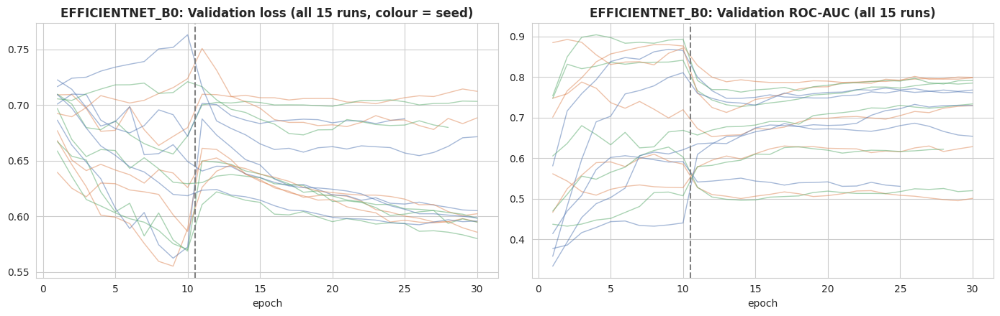

In [25]:
# ==============================================================================
# SECTION 10A: LOAD PREDICTIONS, TRAINING CURVES
# ==============================================================================
# CHAPTER 3: Evaluation
META_KEEP = ["image_id", "group_id", "brand", "tier", "source", "brand_website", "seller", "cls", "label_tier_num", "model_ref"]
def load_preds(arch):
    """All per-image predictions of an architecture joined with the image metadata (group, brand, tier, source)."""
    fs = sorted(glob.glob(f"{RUNS}/{arch}/*_preds.csv"))
    P = pd.concat([pd.read_csv(f) for f in fs], ignore_index=True)
    return P.merge(data[META_KEEP], on="image_id", how="left")

def metric_row(g):
    """Five metrics for a table of predictions with columns label, prob, pred."""
    y, pr, p = g["label"].values, g["pred"].values, g["prob"].values
    return dict(accuracy=accuracy_score(y, pr), precision=precision_score(y, pr, zero_division=0),
                recall=recall_score(y, pr, zero_division=0), f1=f1_score(y, pr, zero_division=0), roc_auc=safe_auc(y, p))

METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc"]
PREDS, EVAL = {}, {}
log_stage("Section 10: evaluation")
for arch in tqdm(ARCHS_TO_RUN, desc="loading predictions"):
    P = load_preds(arch); PREDS[arch] = P
    P[P.eval_set == "heldout"].to_csv(f"{PRED}/oof_predictions_{arch}.csv", index=False)
    P[P.eval_set == "test"].to_csv(f"{PRED}/test_predictions_{arch}.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for f in sorted(glob.glob(f"{RUNS}/{arch}/*_history.csv")):
        h = pd.read_csv(f); s = int(re.search(r"_s(\d+)_history", f).group(1))
        c = {SEEDS[0]: "#4C72B0", SEEDS[1]: "#DD8452", SEEDS[2]: "#55A868"}.get(s, "grey") if len(SEEDS) == 3 else "grey"
        axes[0].plot(h.epoch, h.val_loss, color=c, alpha=0.5, lw=1); axes[1].plot(h.epoch, h.val_auc, color=c, alpha=0.5, lw=1)
    for ax, t in zip(axes, ["Validation loss (all 15 runs, colour = seed)", "Validation ROC-AUC (all 15 runs)"]):
        ax.axvline(PHASE1_EPOCHS + 0.5, color="grey", ls="--"); ax.set_title(f"{arch.upper()}: {t}", fontweight="bold"); ax.set_xlabel("epoch")
    savefig(f"07_training_curves_{arch}.png")

In [26]:
# ==============================================================================
# SECTION 10B: SUMMARY TABLES (CV, pooled OOF, sensitivity, thresholds, generalisation gap)
# ==============================================================================
# CHAPTER 3: Evaluation (metrics, sensitivity, threshold spread, CV-to-test drop)
for arch in ARCHS_TO_RUN:
    P, runs = PREDS[arch], runs_all[runs_all.arch == arch]
    oof, tst = P[P.eval_set == "heldout"], P[P.eval_set == "test"]

    rows = []
    for name, pre in [("held-out fold", "heldout_"), ("external test", "test_")]:
        for m in METRICS:
            v = runs[pre + m]; rows.append(dict(arch=arch, evaluated_on=name, metric=m, mean=v.mean(), sd=v.std(ddof=1), n_runs=len(v)))
    cv = pd.DataFrame(rows); savetab(cv, f"cv_summary_{arch}.csv")

    pooled = pd.DataFrame([dict(seed=s, **metric_row(g)) for s, g in oof.groupby("seed")])
    pooled.loc[len(pooled)] = dict(seed="mean", **pooled[METRICS].mean()); pooled.loc[len(pooled)] = dict(seed="sd", **pooled.iloc[:-1][METRICS].std(ddof=1))
    savetab(pooled, f"pooled_oof_{arch}.csv")

    srows = []
    for (rid, es), g in P.groupby(["run_id", "eval_set"]):
        for th in [str(t) for t in FIXED_THRESHOLDS] + ["run_theta"]:
            t = float(g.theta.iloc[0]) if th == "run_theta" else float(th)
            srows.append(dict(run_id=rid, eval_set=es, threshold=th, **metrics_at(g.label.values, g.prob.values, t)))
    sens = pd.DataFrame(srows).groupby(["eval_set", "threshold"])[METRICS].agg(["mean", "std"]); sens.columns = ["_".join(c) for c in sens.columns]
    savetab(sens.reset_index(), f"sensitivity_{arch}.csv")
    print(f"\n{arch.upper()} sensitivity at the fixed thresholds and at each run's own theta (mean over the runs; AUC does not depend on the threshold):\n",
          sens[[f"{m}_mean" for m in METRICS]].round(3).to_string())

    thr = runs.groupby("fold")["theta"].agg(["mean", "std", "min", "max"]).reset_index()
    thr.loc[len(thr)] = dict(fold="all runs", mean=runs.theta.mean(), std=runs.theta.std(ddof=1), min=runs.theta.min(), max=runs.theta.max())
    savetab(thr, f"threshold_spread_{arch}.csv")

    gap = pd.DataFrame([dict(arch=arch, metric=m, cv_mean=runs["heldout_" + m].mean(), test_mean=runs["test_" + m].mean(),
                             drop_mean=(runs["heldout_" + m] - runs["test_" + m]).mean(), drop_sd=(runs["heldout_" + m] - runs["test_" + m]).std(ddof=1))
                        for m in ["accuracy", "f1", "roc_auc"]])
    savetab(gap, f"cv_to_test_drop_{arch}.csv")

    print(f"\n{'=' * 78}\n{arch.upper()}  (mean ± sd over {len(runs)} runs)\n{'=' * 78}")
    show = cv.pivot(index="metric", columns="evaluated_on", values=["mean", "sd"]).round(4); print(show)
    print("\nθ spread:\n", thr.round(3).to_string(index=False)); print("\nCV -> test drop:\n", gap.round(4).to_string(index=False))

    EVAL[arch] = dict(cv=cv, pooled=pooled, gap=gap)


EFFICIENTNET_B0 sensitivity at the fixed thresholds and at each run's own theta (mean over the runs; AUC does not depend on the threshold):
                     accuracy_mean  precision_mean  recall_mean  f1_mean  roc_auc_mean
eval_set threshold                                                                   
heldout  0.3                0.535           0.461        0.782    0.572         0.599
         0.5                0.605           0.536        0.380    0.434         0.599
         0.7                0.559           0.560        0.037    0.067         0.599
         run_theta          0.524           0.483        0.590    0.488         0.599
test     0.3                0.579           0.518        0.960    0.673         0.765
         0.5                0.689           0.678        0.595    0.632         0.765
         0.7                0.601           0.873        0.122    0.209         0.765
         run_theta          0.638           0.596        0.769    0.645         0.76

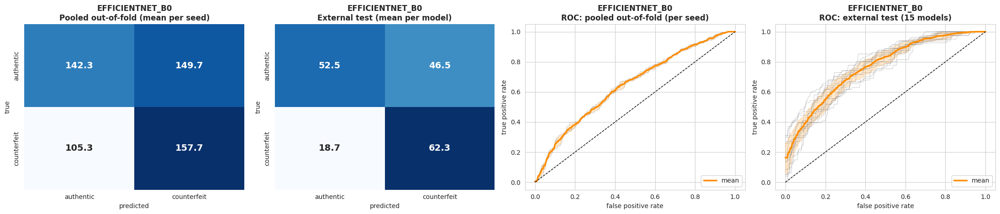

In [27]:
# ==============================================================================
# SECTION 10C: CONFUSION MATRICES AND ROC CURVES
# ==============================================================================
# CHAPTER 3: Evaluation (confusion matrices, ROC)
def mean_roc(groups):
    """Mean and standard deviation of ROC curves interpolated on a common false-positive-rate grid."""
    grid = np.linspace(0, 1, 201); tprs = []
    for g in groups:
        fpr, tpr, _ = roc_curve(g.label.values, g.prob.values); tprs.append(np.interp(grid, fpr, tpr))
    return grid, np.mean(tprs, 0), np.std(tprs, 0), tprs

for arch in ARCHS_TO_RUN:
    P = PREDS[arch]; oof, tst = P[P.eval_set == "heldout"], P[P.eval_set == "test"]
    cm_oof = np.mean([confusion_matrix(g.label, g.pred, labels=[0, 1]) for _, g in oof.groupby("seed")], axis=0)
    cm_tst = np.mean([confusion_matrix(g.label, g.pred, labels=[0, 1]) for _, g in tst.groupby("run_id")], axis=0)
    cmdf = pd.DataFrame([dict(evaluated_on=n, true=t, pred=p, mean_count=cm[i, j]) for n, cm in [("pooled out-of-fold (mean per seed)", cm_oof), ("external test (mean per model)", cm_tst)]
                         for i, t in enumerate(["authentic", "counterfeit"]) for j, p in enumerate(["authentic", "counterfeit"])])
    savetab(cmdf, f"confusion_matrices_{arch}.csv")

    fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
    for ax, cm, t in [(axes[0], cm_oof, "Pooled out-of-fold (mean per seed)"), (axes[1], cm_tst, "External test (mean per model)")]:
        sns.heatmap(cm, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax, xticklabels=["authentic", "counterfeit"],
                    yticklabels=["authentic", "counterfeit"], annot_kws={"size": 14, "weight": "bold"})
        ax.set_title(f"{arch.upper()}\n{t}", fontweight="bold"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for ax, groups, t in [(axes[2], [g for _, g in oof.groupby("seed")], "ROC: pooled out-of-fold (per seed)"),
                          (axes[3], [g for _, g in tst.groupby("run_id")], "ROC: external test (15 models)")]:
        grid, mu, sd, tprs = mean_roc(groups)
        for tp in tprs: ax.plot(grid, tp, color="grey", alpha=0.3, lw=1)
        ax.plot(grid, mu, color="darkorange", lw=2.5, label="mean"); ax.fill_between(grid, mu - sd, np.minimum(mu + sd, 1), color="darkorange", alpha=0.2)
        ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title(f"{arch.upper()}\n{t}", fontweight="bold"); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(loc="lower right")
    savefig(f"09_confusion_roc_{arch}.png")

In [28]:
# ==============================================================================
# SECTION 10D: TIER, BRAND, SOURCE BREAKDOWNS AND BRAND-WEBSITE SENSITIVITY (descriptive)
# ==============================================================================
# CHAPTER 3: Evaluation (background tier, brand, source, brand-website sensitivity)
def breakdown(Pset, by):
    """Metrics within each level of a column (background tier, brand, source). Descriptive only."""
    return pd.DataFrame([dict(**{by: v}, n_images=g.image_id.nunique(), n_predictions=len(g), **metric_row(g)) for v, g in Pset.groupby(by)])

for arch in ARCHS_TO_RUN:
    P = PREDS[arch]; sets = {"cross-validation (out-of-fold)": P[P.eval_set == "heldout"], "external test": P[P.eval_set == "test"]}
    dims = ["tier", "brand"] + (["source"] if HAS_SOURCE else [])
    allb = []
    for by in dims:
        for sname, Ps in sets.items():
            b = breakdown(Ps.dropna(subset=[by]), by).assign(arch=arch, evaluated_on=sname, dimension=by, tier_source=TIER_SOURCE if by == "tier" else "")
            allb.append(b.rename(columns={by: "group"}))
    bd = pd.concat(allb, ignore_index=True); savetab(bd, f"breakdown_{arch}.csv")

    sens_rows = []
    for sname, Ps in sets.items():
        sens_rows.append(dict(evaluated_on=sname, subset="all images", n_images=Ps.image_id.nunique(), **metric_row(Ps)))
        if Ps["brand_website"].any():
            nb = Ps[~Ps["brand_website"].astype(bool)]
            sens_rows.append(dict(evaluated_on=sname, subset="without brand-website images", n_images=nb.image_id.nunique(), **metric_row(nb)))
    savetab(pd.DataFrame(sens_rows), f"brand_website_sensitivity_{arch}.csv")
    if not P["brand_website"].any():
        print(f"[!] {arch}: no brand_website flags in the data, so the with/without brand-website check equals the full set. Provide the flag in metadata.csv.")

In [29]:
# ==============================================================================
# SECTION 10E: GROUP BOOTSTRAP 95% CONFIDENCE INTERVALS
# ==============================================================================
# CHAPTER 3: Evaluation (group bootstrap)
def f1_fast(y, pr):
    """F1 score without sklearn overhead, for the bootstrap loop."""
    tp = ((pr == 1) & (y == 1)).sum(); fp = ((pr == 1) & (y == 0)).sum(); fn = ((pr == 0) & (y == 1)).sum()
    return 2 * tp / max(2 * tp + fp + fn, 1)

def group_bootstrap(g, B=N_BOOT, seed=BOOT_SEED):
    """95% confidence intervals by resampling whole groups (near-duplicate clusters merged with sellers) with replacement."""
    rng = np.random.RandomState(seed); y, p, pr = g.label.values, g.prob.values, g.pred.values
    ug, inv = np.unique(g.group_id.values, return_inverse=True); idx_by = [np.where(inv == i)[0] for i in range(len(ug))]
    out = []
    for _ in tqdm(range(B), desc="group bootstrap", leave=False):
        ii = np.concatenate([idx_by[i] for i in rng.randint(0, len(ug), len(ug))])
        out.append((accuracy_score(y[ii], pr[ii]), f1_fast(y[ii], pr[ii]), safe_auc(y[ii], p[ii])))
    out = np.array(out)
    est = (accuracy_score(y, pr), f1_fast(y, pr), safe_auc(y, p))
    return [dict(metric=m, estimate=e, ci_low=np.nanpercentile(out[:, i], 2.5), ci_high=np.nanpercentile(out[:, i], 97.5))
            for i, (m, e) in enumerate(zip(["accuracy", "f1", "roc_auc"], est))]

for arch in ARCHS_TO_RUN:
    P = PREDS[arch].dropna(subset=["group_id"]); rows = []
    for es, name in tqdm([("heldout", "pooled out-of-fold (3 seeds stacked)"), ("test", "external test (15 models stacked)")], desc=f"{arch} bootstrap CIs"):
        for r in group_bootstrap(P[P.eval_set == es]): rows.append(dict(arch=arch, evaluated_on=name, **r))
    fp_ = f"{PRED}/final_model_test_predictions_{arch}.csv"      # the packaged model, scored once on the external test set (Section 9C)
    if os.path.exists(fp_):
        for r in group_bootstrap(pd.read_csv(fp_).dropna(subset=["group_id"])): rows.append(dict(arch=arch, evaluated_on="external test (packaged final model)", **r))
    ci = pd.DataFrame(rows); savetab(ci, f"bootstrap_ci_{arch}.csv"); print(f"\n{arch.upper()} group-bootstrap 95% CI ({N_BOOT} resamples)\n", ci.round(4).to_string(index=False))

efficientnet_b0 bootstrap CIs:   0%|          | 0/2 [00:00<?, ?it/s]

group bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

group bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]

group bootstrap:   0%|          | 0/2000 [00:00<?, ?it/s]


EFFICIENTNET_B0 group-bootstrap 95% CI (2000 resamples)
            arch                         evaluated_on   metric  estimate  ci_low  ci_high
efficientnet_b0 pooled out-of-fold (3 seeds stacked) accuracy    0.5405  0.4393   0.6121
efficientnet_b0 pooled out-of-fold (3 seeds stacked)       f1    0.5529  0.3934   0.6659
efficientnet_b0 pooled out-of-fold (3 seeds stacked)  roc_auc    0.6452  0.5540   0.7460
efficientnet_b0    external test (15 models stacked) accuracy    0.6378  0.5030   0.7308
efficientnet_b0    external test (15 models stacked)       f1    0.6564  0.2472   0.7981
efficientnet_b0    external test (15 models stacked)  roc_auc    0.7631  0.6611   0.8810
efficientnet_b0 external test (packaged final model) accuracy    0.7056  0.5663   0.8255
efficientnet_b0 external test (packaged final model)       f1    0.7104  0.3111   0.8621
efficientnet_b0 external test (packaged final model)  roc_auc    0.8225  0.7203   0.9387


## 11. Grad-CAM (Chapter 3, Grad-CAM)

> **Chapter 3 reference:** Gradient-weighted Class Activation Mapping (Grad-CAM)
>
> **What the chapter requires**
> - Heatmaps from the final convolutional layer of each model.
> - A stratified sample of up to 60 external-test images: 15 correctly classified authentic, 15 correctly classified counterfeit, and up to 15 misclassified of each class (capped by the errors the model made).
> - Two scores per heatmap: a centrality score (1 means attention centred, 0 means the farthest corner) and a center-energy fraction (share of activation in the central 50% by 50% region).
> - Qualitative review: attention on the dial, hands, bezel, and reflections is expected; attention on the background or borders, especially on errors, hints at photo-style cues.
>
> **Where it is implemented:** `GradCAM`, `centrality`, `overlay`, `plot_gradcam_galleries`, the cell `SECTION 11B`.
>
> **Outputs:** `gradcam_centrality_<arch>.csv`, `gradcam_centrality_summary_<arch>.csv`, figures `11_gradcam_gallery_<arch>_<TP/TN/FP/FN>`, `11_gradcam_mean_heatmap_`, `12_gradcam_centrality_`
>
> **Choices the chapter leaves open (made here)**
> - One model per architecture is used: the packaged final model of Section 9C, loaded from its saved `.pth` and fixed before any test image is scored by it, not chosen by test score. Heatmaps are upsampled to the input size before the two scores are computed.

Heatmaps come from the final convolutional block of the packaged final model of each architecture (Section 9C), which is fixed by rule and not by test performance. The sample is stratified on the external test set: up to 15 correctly classified authentic (TN), 15 correctly classified counterfeit (TP), 15 misclassified authentic (FP), and 15 misclassified counterfeit (FN), capped by however many errors the model produced.

Two numbers summarise each heatmap after upsampling it to the input size: a **centrality score** (1 = centroid at the image centre, 0 = farthest corner) and a **center-energy fraction** (share of activation inside the central 50% by 50% box). The model is loaded from its saved `.pth`, and the outcome groups use the θ stored in that file.

Because the processed images are tightly cropped around the watch, "central" mostly means "on the watch". Attention in the corners or border band, especially on misclassified images, hints at background or photo-style cues.

In [30]:
# ==============================================================================
# SECTION 11A: GRAD-CAM ENGINE
# ==============================================================================
# CHAPTER 3: Grad-CAM
class GradCAM:
    """Grad-CAM for a single-logit model. Uses a tensor hook, so in-place ReLU/SiLU layers are not a problem."""
    def __init__(self, model, layer):
        self.model, self.act, self.grad = model.eval(), None, None
        self.handle = layer.register_forward_hook(self._fwd)
    def _fwd(self, module, inp, out):
        self.act = out
        if out.requires_grad: out.register_hook(lambda g: setattr(self, "grad", g))
    def __call__(self, x):
        self.model.zero_grad(set_to_none=True); self.grad = None
        with torch.enable_grad():
            logit = self.model(x)[0, 0]; logit.backward()
        w = self.grad.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.act).sum(1))[0].detach().cpu().numpy()
        return (cam / cam.max() if cam.max() > 0 else cam), float(torch.sigmoid(logit.detach()))
    def close(self): self.handle.remove()

def centrality(cam_up):
    """Return (centrality score, center-energy fraction) of a heatmap. Centrality: 1 = weighted centroid at the image centre, 0 = farthest corner. Center-energy: share of activation inside the central 50% x 50% box (Chapter 3: Grad-CAM)."""
    h, w = cam_up.shape; tot = cam_up.sum()
    if tot <= 0: return 0.0, 0.0
    yy, xx = np.mgrid[0:h, 0:w]; cy, cx = (yy * cam_up).sum() / tot, (xx * cam_up).sum() / tot
    c0y, c0x = (h - 1) / 2, (w - 1) / 2
    score = 1.0 - np.hypot(cy - c0y, cx - c0x) / np.hypot(c0y, c0x)
    return float(score), float(cam_up[int(h * .25):int(h * .75), int(w * .25):int(w * .75)].sum() / tot)

def overlay(rgb, cam_up, alpha=0.5):
    """Blend a JET-coloured heatmap over the image."""
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam_up), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return np.uint8(alpha * heat + (1 - alpha) * rgb)

def plot_gradcam_galleries(arch, items, rid, ncols=5):
    """One gallery PNG per outcome group (TP, TN, FP, FN) and a mean-heatmap figure."""
    names = {"TP": "True positives (counterfeit caught)", "TN": "True negatives (authentic cleared)",
             "FP": "False positives (authentic flagged)", "FN": "False negatives (counterfeit missed)"}
    for cat in ["TP", "TN", "FP", "FN"]:
        sel = [it for it in items if it[0] == cat]
        if not sel: continue
        nrows = math.ceil(len(sel) / ncols)
        fig, axes = plt.subplots(nrows, ncols, figsize=(3.1 * ncols, 3.4 * nrows)); axes = np.atleast_2d(axes)
        for ax in axes.ravel(): ax.axis("off")
        for ax, (_, rgb, ov, prob, brand, _cam) in zip(axes.ravel(), sel):
            ax.imshow(ov); ax.set_title(f"{brand}\nP(counterfeit) = {prob:.2f}", fontsize=9)
        fig.suptitle(f"{arch.upper()} Grad-CAM, {names[cat]} ({rid})", fontweight="bold", y=1.0)
        savefig(f"11_gradcam_gallery_{arch}_{cat}.png")
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
    for ax, cat in zip(axes, ["TP", "TN", "FP", "FN"]):
        ax.axis("off"); cams = [it[5] for it in items if it[0] == cat]
        if cams:
            im = ax.imshow(np.mean(cams, 0), cmap="jet", vmin=0, vmax=1); ax.set_title(f"{cat} (n={len(cams)})\nmean Grad-CAM heatmap", fontweight="bold")
    fig.suptitle(f"{arch.upper()}: average attention by outcome ({rid})", fontweight="bold", y=1.03)
    savefig(f"11_gradcam_mean_heatmap_{arch}.png")



[03:59:12 | + 50.9 min] Section 11: Grad-CAM
[*] efficientnet_b0: Grad-CAM on efficientnet_b0_final | test outcomes: {'TP': 65, 'TN': 62, 'FP': 37, 'FN': 16}


Grad-CAM efficientnet_b0:   0%|          | 0/60 [00:00<?, ?it/s]

         centrality_score              center_energy_fraction             
                     mean    std count                   mean    std count
category                                                                  
FN                  0.913  0.033    15                  0.658  0.093    15
FP                  0.882  0.051    15                  0.556  0.146    15
TN                  0.864  0.098    15                  0.504  0.199    15
TP                  0.897  0.041    15                  0.550  0.107    15


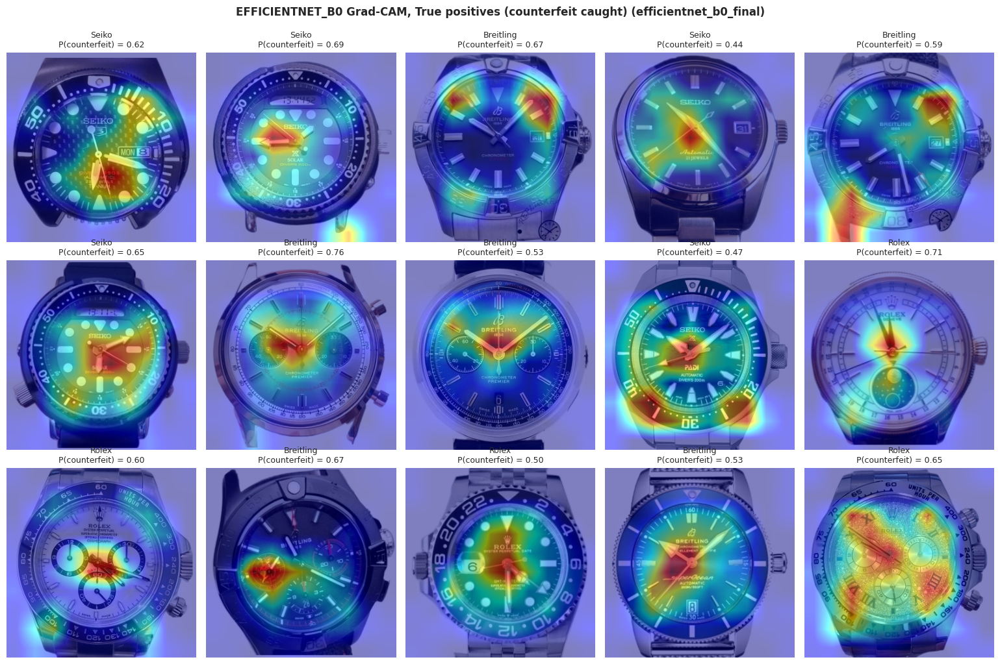

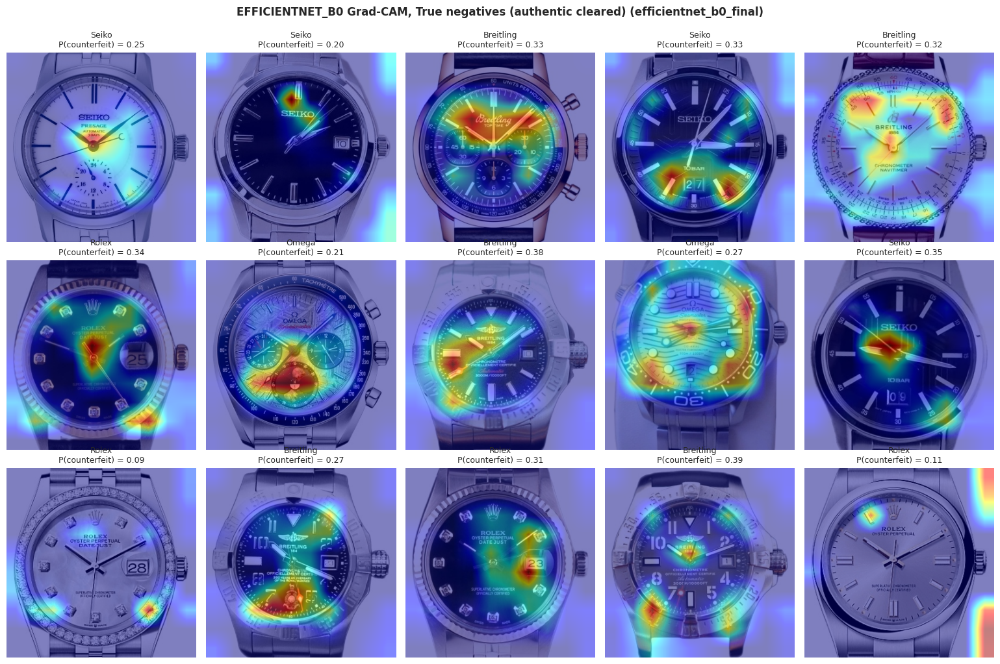

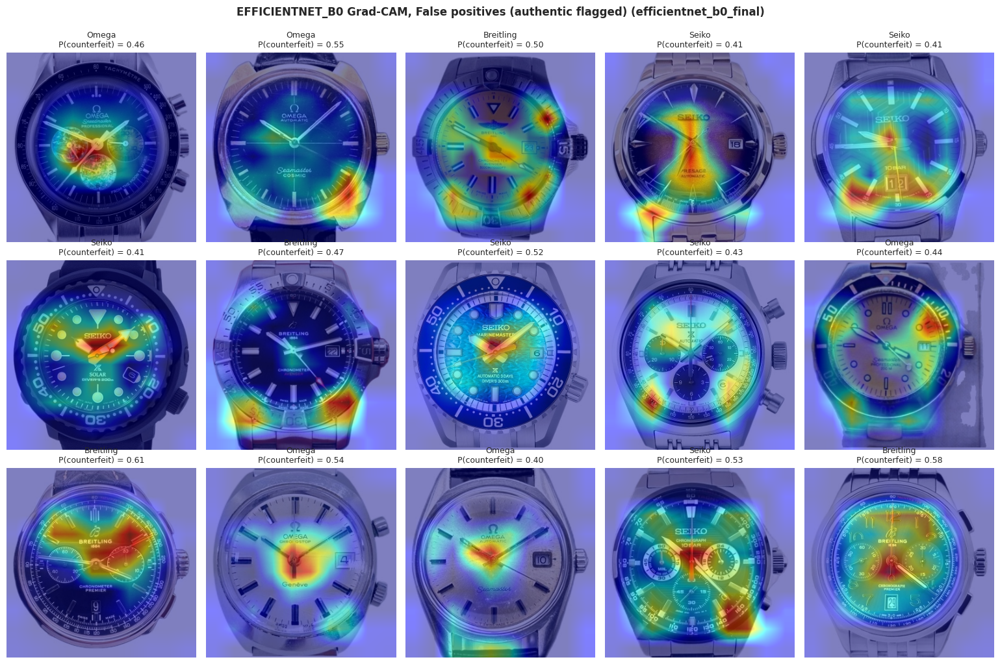

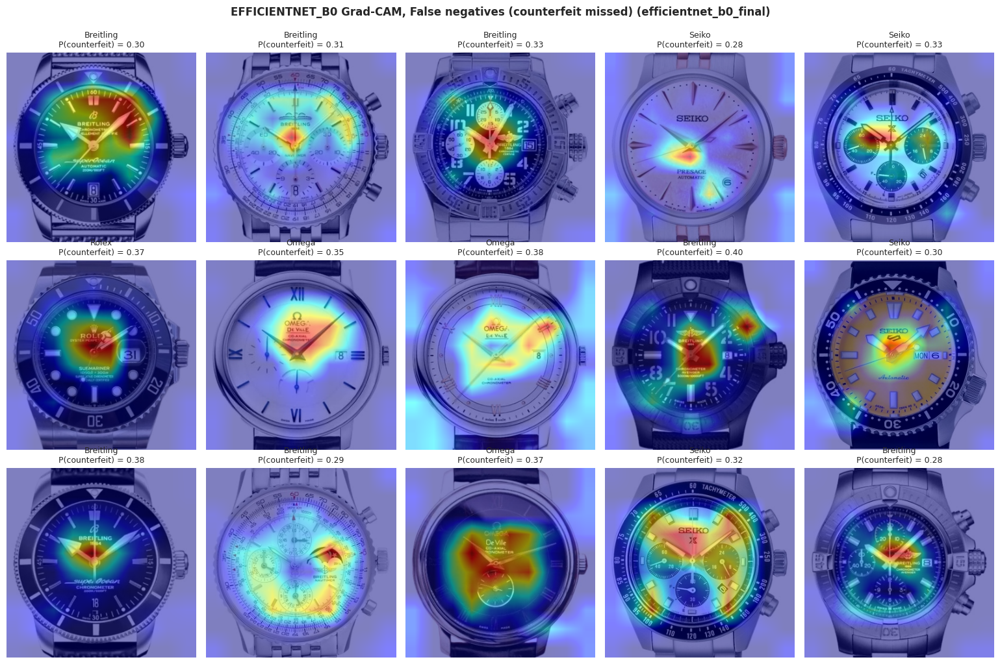

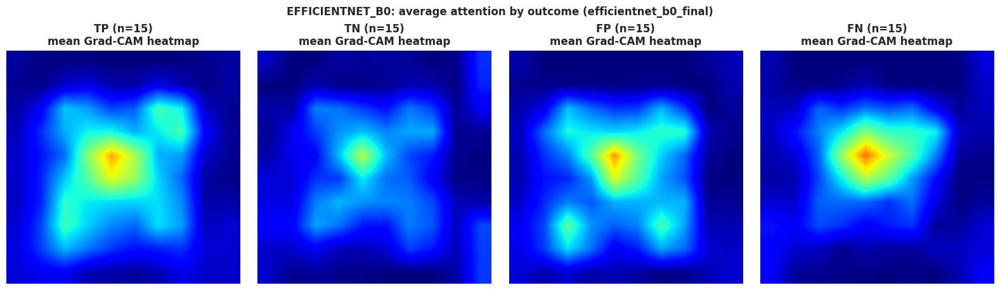

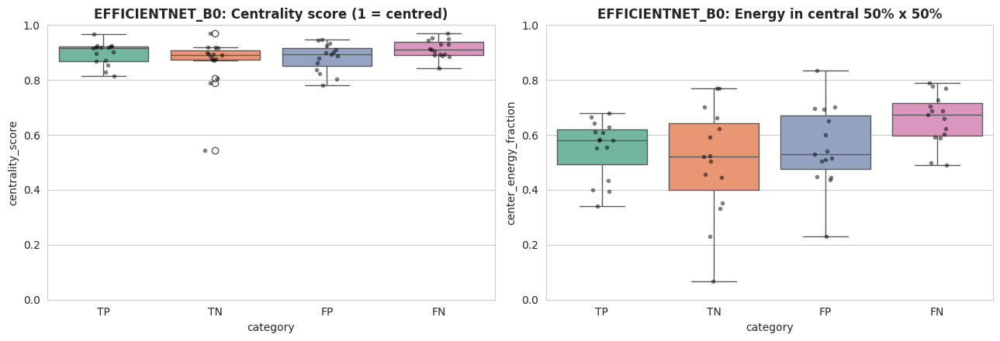

In [31]:
# ==============================================================================
# SECTION 11B: STRATIFIED SAMPLE, HEATMAPS, CENTRALITY
# ==============================================================================
# CHAPTER 3: Grad-CAM
def quadrant(r):
    """Outcome group of a prediction: TP, TN, FP or FN (counterfeit = positive)."""
    return ("TP" if r.pred == 1 else "FN") if r.label == 1 else ("FP" if r.pred == 1 else "TN")

if RUN_GRADCAM:
    log_stage("Section 11: Grad-CAM")
    for arch in ARCHS_TO_RUN:
        model, _ck = load_checkpoint_pth(final_paths(arch)["pth"]); rid = f"{arch}_final"      # the packaged model, loaded from its saved .pth
        pr = pd.read_csv(f"{PRED}/final_model_test_predictions_{arch}.csv")[["image_id", "label", "prob", "pred"]].merge(test_df[["image_id", "proc_path", "brand", "tier"]], on="image_id")
        pr["category"] = pr.apply(quadrant, axis=1)
        print(f"[*] {arch}: Grad-CAM on {rid} | test outcomes:", pr.category.value_counts().to_dict())
        samp = pd.concat([pr[pr.category == c].sample(n=min(GRADCAM_PER_CLASS, (pr.category == c).sum()), random_state=FOLD_SEED) for c in ["TP", "TN", "FP", "FN"]]).reset_index(drop=True)

        gc = GradCAM(model, gradcam_layer(model, arch)); recs, items = [], []
        for i, r in tqdm(samp.iterrows(), total=len(samp), desc=f"Grad-CAM {arch}"):
            rgb = get_array(r.proc_path, INPUT_SIZE)
            x = EVAL_TF(Image.fromarray(rgb)).unsqueeze(0).to(device)
            cam, prob = gc(x); cam_up = cv2.resize(cam, (INPUT_SIZE, INPUT_SIZE), interpolation=cv2.INTER_LINEAR)
            cs, ef = centrality(cam_up); ov = overlay(rgb, cam_up)
            recs.append(dict(arch=arch, run_id=rid, image_id=r.image_id, category=r.category, brand=r.brand, tier=r.tier, prob_counterfeit=prob,
                             centrality_score=cs, center_energy_fraction=ef)); items.append((r.category, rgb, ov, prob, r.brand, cam_up))
        gc.close()
        gdf = pd.DataFrame(recs); savetab(gdf, f"gradcam_centrality_{arch}.csv")
        summ = gdf.groupby("category")[["centrality_score", "center_energy_fraction"]].agg(["mean", "std", "count"]).round(3)
        s2 = summ.copy(); s2.columns = ["_".join(c) for c in s2.columns]; savetab(s2.reset_index(), f"gradcam_centrality_summary_{arch}.csv")
        print(summ)

        plot_gradcam_galleries(arch, items, rid)

        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5)); order = ["TP", "TN", "FP", "FN"]
        for ax, col, t in [(axes[0], "centrality_score", "Centrality score (1 = centred)"), (axes[1], "center_energy_fraction", "Energy in central 50% x 50%")]:
            sns.boxplot(data=gdf, x="category", y=col, order=order, palette="Set2", ax=ax); sns.stripplot(data=gdf, x="category", y=col, order=order, color="k", alpha=0.5, size=4, ax=ax)
            ax.set_ylim(0, 1); ax.set_title(f"{arch.upper()}: {t}", fontweight="bold")
        savefig(f"12_gradcam_centrality_{arch}.png")
        del model; torch.cuda.empty_cache()

## 12. Time and space complexity (Chapter 3, Table 3)

> **Chapter 3 reference:** Time and Space Complexity Analysis (Table 3)
>
> **What the chapter requires**
> - Time complexity of a convolutional layer is O(H x W x K x F^2 x C), summed over layers; space complexity is O(K x F^2 x C) per layer.
> - Table 3 metrics: parameters (M), FLOPs (M) as multiply-accumulate operations per forward pass on a 320x320 input, inference time (ms/image) on GPU, training time (min/epoch) on GPU, model size (MB), and peak GPU memory during inference (MB).
>
> **Where it is implemented:** `measure_complexity`, `layer_table`, `peak_train_vram_mb`, `cpu_latency_ms`. The multiply-accumulate count is the empirical sum of the O(H x W x K x F^2 x C) terms over all layers (the per-layer table lists every term and is checked against PyTorch's FLOP counter), and parameters are the sum of the O(K x F^2 x C) terms.
>
> **Outputs:** `complexity_<arch>.csv`, `complexity_layers_<arch>.csv`, `cost_vs_performance_<arch>.csv`
>
> **Choices the chapter leaves open (made here)**
> - Training time per epoch is taken from the actual runs (it includes data loading and mixed precision). Latency is measured at batch size 1 after a warm-up. On a CPU-only session latency is measured on CPU and GPU memory is reported as 0.
> - Beyond Table 3 the notebook also reports trainable parameters in each phase, peak GPU memory of one training step (batch 32, mixed precision), CPU latency, the mean training time of a CV run and of the final model, and the GPU model, because timings depend on the hardware.

Table 3 metrics: parameters, FLOPs (reported as multiply-accumulate operations, in millions, at the chosen input size), GPU inference latency per image, training time per epoch (measured during the actual training runs, so it includes data loading and AMP), model file size, and peak GPU memory during inference. Additional: trainable parameters in phase 1 and phase 2, a per-layer table of the chapter's time and space terms (`complexity_layers_<arch>.csv`), peak GPU memory of a training step, CPU latency, and training minutes per CV run and for the final model. F1 and ROC-AUC (cross-validation, test, and the final model) are then paired with parameters, FLOPs, and latency in one table. Training times are dominated by image loading and augmentation on the CPU, so the phase-1 and phase-2 epoch times can be nearly equal.


In [32]:
# ==============================================================================
# SECTION 12: COMPLEXITY BENCHMARK
# ==============================================================================
# CHAPTER 3: Time and Space Complexity Analysis
from torch.utils.flop_counter import FlopCounterMode

def layer_table(m, x):
    """One row per convolution or linear layer with the terms of the chapter's formulas. Time: H x W x K x F^2 x C multiply-accumulates (output height and width, output channels K, kernel F x F, input channels per group C). Space: K x F^2 x C weights."""
    rows, hooks = [], []
    def make_hook(name):
        def hook(mod, inp, out):
            if isinstance(mod, nn.Conv2d):
                kh, kw = mod.kernel_size; Cg = mod.in_channels // mod.groups; K = mod.out_channels; H, W = out.shape[2], out.shape[3]
                rows.append(dict(layer=name, type="Conv2d", out_H=H, out_W=W, K_out_channels=K, F_kernel=f"{kh}x{kw}", C_in_per_group=Cg, groups=mod.groups,
                                 macs=H * W * K * Cg * kh * kw, weights=K * Cg * kh * kw + (K if mod.bias is not None else 0)))
            else:
                rows.append(dict(layer=name, type="Linear", out_H=1, out_W=1, K_out_channels=mod.out_features, F_kernel="1x1", C_in_per_group=mod.in_features, groups=1,
                                 macs=mod.in_features * mod.out_features, weights=mod.in_features * mod.out_features + (mod.out_features if mod.bias is not None else 0)))
        return hook
    for name, mod in m.named_modules():
        if isinstance(mod, (nn.Conv2d, nn.Linear)): hooks.append(mod.register_forward_hook(make_hook(name)))
    with torch.no_grad(): m(x)
    for h in hooks: h.remove()
    return pd.DataFrame(rows)

def peak_train_vram_mb(arch):
    """Peak GPU memory of one phase-2 training step at the training batch size and mixed precision (0 when there is no GPU)."""
    if device.type != "cuda": return 0.0
    m = build_model(arch, pretrained=False); set_phase(m, arch, 2); m.train()
    opt = _make_optimizer(m, arch, PHASE2_LR); scaler = _make_scaler(); crit = nn.BCEWithLogitsLoss()
    x = torch.randn(BATCH_SIZE, 3, INPUT_SIZE, INPUT_SIZE, device=device); y = torch.zeros(BATCH_SIZE, 1, device=device)
    torch.cuda.synchronize(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    for _ in range(3):
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=AMP_ON):
            out = m(x)
        scaler.scale(crit(out.float(), y)).backward(); scaler.step(opt); scaler.update()
    torch.cuda.synchronize(); peak = torch.cuda.max_memory_allocated() / 2**20
    del m, opt; torch.cuda.empty_cache()
    return peak

def cpu_latency_ms(arch, n_it=10):
    """Inference time per image on the CPU at batch size 1, after a warm-up."""
    m = build_model(arch, pretrained=False).cpu().eval(); x = torch.randn(1, 3, INPUT_SIZE, INPUT_SIZE)
    with torch.no_grad():
        for _ in range(2): m(x)
        t0 = time.time()
        for _ in range(n_it): m(x)
    return (time.time() - t0) / n_it * 1000

def measure_complexity(arch):
    """Table 3 metrics (parameters, multiply-accumulates at the input size, model size, GPU inference latency, peak inference memory) plus the per-layer terms, trainable parameters per phase, peak training memory and CPU latency."""
    m = build_model(arch, pretrained=False).eval()
    total = sum(p.numel() for p in m.parameters())
    set_phase(m, arch, 1); tr1 = sum(p.numel() for p in m.parameters() if p.requires_grad)
    set_phase(m, arch, 2); tr2 = sum(p.numel() for p in m.parameters() if p.requires_grad)
    x = torch.randn(1, 3, INPUT_SIZE, INPUT_SIZE, device=device)
    with torch.no_grad(), FlopCounterMode(display=False) as fc: m(x)
    macs = fc.get_total_flops() / 2
    layers = layer_table(m, x)
    tmp = f"{CACHE}/_tmp_{arch}.pth"; torch.save(m.state_dict(), tmp); size_mb = os.path.getsize(tmp) / 2**20; os.remove(tmp)
    n_it, vram = (200 if device.type == "cuda" else 30), 0.0
    with torch.no_grad():
        if device.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        for _ in range(10): m(x)
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(n_it):
            m(x)
            if device.type == "cuda": torch.cuda.synchronize()
        lat = (time.time() - t0) / n_it * 1000
        if device.type == "cuda": vram = torch.cuda.max_memory_allocated() / 2**20
    del m; torch.cuda.empty_cache()
    out = dict(total_params_M=total / 1e6, phase1_trainable_params_M=tr1 / 1e6, phase2_trainable_params_M=tr2 / 1e6, flops_M_macs=macs / 1e6,
               conv_linear_macs_M=layers["macs"].sum() / 1e6, model_size_MB=size_mb, inference_ms_per_image=lat, inference_device=device.type,
               hardware=torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU", peak_vram_inference_MB=vram,
               peak_vram_training_MB=peak_train_vram_mb(arch), inference_ms_per_image_cpu=cpu_latency_ms(arch))
    return out, layers

COMPLEXITY = {}
log_stage("Section 12: complexity benchmark")
for arch in tqdm(ARCHS_TO_RUN, desc="complexity"):
    runs = runs_all[runs_all.arch == arch]; cx, layers = measure_complexity(arch)
    cx.update(arch=arch, input_size=INPUT_SIZE, train_min_per_epoch_all=runs.mean_epoch_sec.mean() / 60, train_min_per_epoch_phase2=runs.phase2_epoch_sec.mean() / 60,
              train_min_per_run_cv_mean=runs.train_minutes.mean(), train_min_final_model=FINAL.get(arch, {}).get("train_minutes", float("nan")))
    dfc = pd.DataFrame([cx]).round(4); savetab(dfc, f"complexity_{arch}.csv"); COMPLEXITY[arch] = dfc
    savetab(layers.assign(share_of_macs=layers["macs"] / layers["macs"].sum()).round(5), f"complexity_layers_{arch}.csv")
    perf = pd.DataFrame([dict(arch=arch, cv_f1=runs.heldout_f1.mean(), cv_roc_auc=runs.heldout_roc_auc.mean(), test_f1=runs.test_f1.mean(), test_roc_auc=runs.test_roc_auc.mean(),
                              final_model_test_roc_auc=FINAL.get(arch, {}).get("test_roc_auc", float("nan")),
                              params_M=cx["total_params_M"], flops_M_macs=cx["flops_M_macs"], inference_ms_per_image=cx["inference_ms_per_image"])]).round(4)
    savetab(perf, f"cost_vs_performance_{arch}.csv"); print(f"\n{arch.upper()}\n", dfc.T.to_string(header=False))
    print(f"  per-layer check: {len(layers)} conv/linear layers sum to {layers['macs'].sum() / 1e6:.1f} M MACs; the FLOP counter gives {cx['flops_M_macs']:.1f} M")
if device.type != "cuda": print("\n[!] No GPU: latency was measured on CPU and GPU memory is 0. Re-run on a Kaggle GPU for Table 3.")



[03:59:33 | + 51.2 min] Section 12: complexity benchmark


complexity:   0%|          | 0/1 [00:00<?, ?it/s]


EFFICIENTNET_B0
 total_params_M                       4.0088
phase1_trainable_params_M            0.0013
phase2_trainable_params_M            1.1307
flops_M_macs                       784.1133
conv_linear_macs_M                 784.1133
model_size_MB                       15.5816
inference_ms_per_image                7.985
inference_device                       cuda
hardware                           Tesla T4
peak_vram_inference_MB               86.521
peak_vram_training_MB              437.8403
inference_ms_per_image_cpu          42.8733
arch                        efficientnet_b0
input_size                              320
train_min_per_epoch_all              0.0565
train_min_per_epoch_phase2            0.056
train_min_per_run_cv_mean            1.6792
train_min_final_model                1.6377
  per-layer check: 82 conv/linear layers sum to 784.1 M MACs; the FLOP counter gives 784.1 M


## 13. Methodology compliance report

> **Chapter 3 reference:** All sections (automatic check of the run against the chapter)
>
> **What the chapter requires**
> - The chapter fixes many counts, ratios, and procedures. This section tests the data and the run against them wherever that is possible.
>
> **Where it is implemented:** the compliance cell below.
>
> **Outputs:** `table_methodology_compliance.csv`
>
> **Not checkable by code**
> - Statuses: PASS (measured and matches), FAIL (measured and differs), REVIEW (needs your manual decision), BY DESIGN (enforced by the code path, not measured), NOT VERIFIABLE (the data needed is missing), NOT RUN (the stage was switched off).


[03:59:36 | + 51.3 min] Section 13: methodology compliance report
status
PASS              45
FAIL              16
BY DESIGN          4
REVIEW             2
NOT VERIFIABLE     1
NOT RUN            1 

Rows that need your attention:
                chapter_section                                                    requirement               expected                                           observed status
                 Data Gathering                                         Total number of images                    800                                                735   FAIL
                 Data Gathering                                        pool / authentic images                    300                                                292   FAIL
                 Data Gathering                                      pool / counterfeit images                    300                                                263   FAIL
                 Data Gathering                                

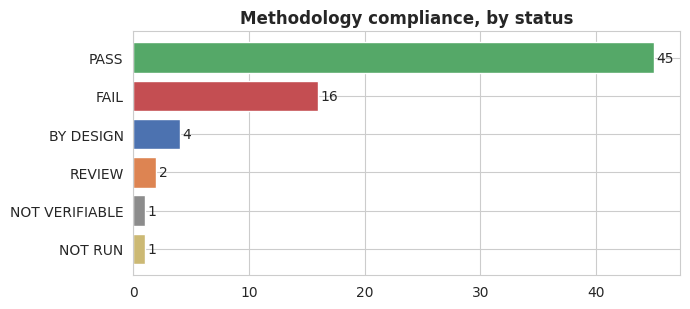

In [33]:
# ==============================================================================
# SECTION 13: METHODOLOGY COMPLIANCE REPORT
# ==============================================================================
# CHAPTER 3: All sections. Every row compares this run with a statement of the chapter.
log_stage("Section 13: methodology compliance report")
CHECKS = []

def check(section, requirement, expected, observed, ok):
    """Record one check. ok = True (PASS), False (FAIL), None (NOT VERIFIABLE) or a status word such as 'REVIEW', 'BY DESIGN', 'NOT RUN'."""
    status = ok if isinstance(ok, str) else ("NOT VERIFIABLE" if ok is None else ("PASS" if bool(ok) else "FAIL"))
    CHECKS.append(dict(chapter_section=section, requirement=requirement, expected=str(expected), observed=str(observed), status=status))

def safe(fn, default=None):
    try: return fn()
    except Exception: return default

HAS_MODELREF = data["model_ref"].notna().mean() > 0.5
n_by = data.groupby(["split", "cls"]).size()

# ---- Data Gathering ------------------------------------------------------------------
check("Data Gathering", "Total number of images", 800, len(data), len(data) == 800)
for (sp, c), exp in {("pool", "authentic"): 300, ("pool", "counterfeit"): 300, ("test", "authentic"): 100, ("test", "counterfeit"): 100}.items():
    n = int(n_by.get((sp, c), 0)); check("Data Gathering", f"{sp} / {c} images", exp, n, n == exp)
if HAS_BRAND:
    pb = data.groupby(["split", "cls", "brand"]).size(); off = [(k, int(v)) for k, v in pb.items() if v != (75 if k[0] == "pool" else 25)]
    check("Data Gathering", "Per class per brand: 75 images in the pool, 25 in the test set", "all 16 cells on target", f"{len(off)} cells differ {off[:3]}", len(off) == 0)
else:
    check("Data Gathering", "Per class per brand: 75 in the pool, 25 in the test set", "all cells on target", "brand unknown", None)

def plain_share(fr): return float((fr["tier"] == "Plain").mean()) if len(fr) else np.nan
tier_ok = TIER_SOURCE == "metadata"
for name, fr in [("pool", pool_df), ("test set", test_df)]:
    sh = {c: plain_share(fr[fr.cls == c]) for c in ["authentic", "counterfeit"]}
    ok = all(0.35 <= v <= 0.45 for v in sh.values()) and abs(sh["authentic"] - sh["counterfeit"]) <= 0.05 if tier_ok else None
    check("Data Gathering", f"Plain share about 40% (within 5 points) and equal in both classes, {name}", "35-45%, classes within 5 points",
          {k: f"{v:.0%}" for k, v in sh.items()} if tier_ok else f"tier is {TIER_SOURCE}", ok)
if tier_ok and HAS_BRAND:
    cells = data.groupby(["brand", "cls"]).apply(plain_share); bad = cells[(cells < 0.35) | (cells > 0.45)]
    check("Data Gathering", "Plain share within 5 points of 40% in every brand and class", "all 8 cells in 35-45%", f"{len(bad)} cells outside", len(bad) == 0)
if HAS_META:
    check("Data Gathering", "No brand-website image in the external test set", 0, int(test_df.brand_website.sum()), int(test_df.brand_website.sum()) == 0)
    ap = pool_df[pool_df.cls == "authentic"]; sh = float(ap.brand_website.mean())
    check("Data Gathering", "Brand-website images at most 20% of the authentic pool", "<= 20%", f"{sh:.1%}", sh <= 0.20)
    ap_plain = ap[ap.tier == "Plain"]
    if len(ap_plain) and tier_ok:
        check("Data Gathering", "Brand-website images at most half of the authentic Plain tier", "<= 50%", f"{ap_plain.brand_website.mean():.1%}", bool(ap_plain.brand_website.mean() <= 0.5))
if HAS_SOURCE:
    spl, stt = set(pool_df.source.dropna().str.lower()), set(test_df.source.dropna().str.lower())
    check("Data Gathering", "No source appears in both pool and test set", "no overlap", sorted(spl & stt) or "none", len(spl & stt) == 0)
    for c in ["authentic", "counterfeit"]:
        mx = pool_df[pool_df.cls == c].source.value_counts(normalize=True).max()
        check("Data Gathering", f"No source above 40% of the {c} class in the pool", "<= 40%", f"{mx:.0%}", bool(mx <= 0.40))
else:
    check("Data Gathering", "Source separation and the 40% source cap", "see text", "source unknown", None)
if HAS_SELLER:
    sp_, st_ = set(pool_df.seller.dropna().astype(str).str.lower()), set(test_df.seller.dropna().astype(str).str.lower())
    check("Data Gathering", "No seller appears in both pool and test set", "no overlap", f"{len(sp_ & st_)} shared", len(sp_ & st_) == 0)
    for c in ["authentic", "counterfeit"]:
        n = data[data.cls == c].seller.nunique(); check("Data Gathering", f"At least 30 sellers in the {c} class", ">= 30", n, n >= 30)
else:
    check("Data Gathering", "Seller separation and at least 30 sellers per class", "see text", "seller unknown", None)
if HAS_MODELREF and HAS_BRAND:
    for c in ["authentic", "counterfeit"]:
        g_ = data[data.cls == c].groupby("brand")["model_ref"].nunique(); mn = int(g_.min())
        check("Data Gathering", f"At least 8 model references per brand, {c}", ">= 8", g_.to_dict(), mn >= 8)
    share = data.groupby(["cls", "brand"])["model_ref"].apply(lambda s: s.value_counts(normalize=True).max())
    check("Data Gathering", "No model reference above 25% of its brand cell", "<= 25%", f"max {share.max():.0%}", bool(share.max() <= 0.25))
else:
    check("Data Gathering", "Model-reference diversity (8 per brand, 25% cap)", "see text", "model_reference unknown", None)
if data["label_tier_num"].notna().any():
    check("Data Gathering", "No Tier 3 (ambiguous) labels in the dataset", 0, int((data.label_tier_num == 3).sum()), int((data.label_tier_num == 3).sum()) == 0)
else:
    check("Data Gathering", "No Tier 3 (ambiguous) labels in the dataset", 0, "label_tier unknown", None)
check("Data Gathering", "Circular dial, front-facing, dial >= 60% of frame, expert validation, replica declaration", "manual review", "n/a", "NOT VERIFIABLE")

# ---- Data Cleaning ------------------------------------------------------------------
gates = PREPROCESS_MODE != "already_processed"
check("Data Cleaning", "Short side >= 400 px for every kept image", ">= 400", safe(lambda: int(data.short_side.min())), (data.short_side.min() >= 400) if gates else None)
check("Data Cleaning", "Laplacian variance at 320x320 >= 300 for every kept image", ">= 300", safe(lambda: round(float(data.lap_var.min()), 1)), (data.lap_var.min() >= 300) if gates else None)
check("Data Cleaning", "Images re-saved as JPEG at quality 95", 95, JPEG_QUALITY, JPEG_QUALITY == 95)
check("Data Cleaning", "Subsampling to the per-cell targets before partitioning (step 7)", "SUBSAMPLE_TO_TARGET on", SUBSAMPLE_TO_TARGET, True if SUBSAMPLE_TO_TARGET else "REVIEW")
check("Data Cleaning", "Every removed image is listed with its stage and reason", "table_removed_images_all.csv", "found" if os.path.exists(f"{TAB}/table_removed_images_all.csv") else "missing", os.path.exists(f"{TAB}/table_removed_images_all.csv"))
all_ok = bool((data["status"] == "ok").all()) if "status" in data else False
check("Data Cleaning", "rembg applied to every image in both classes with identical settings", "mode 'full', all images ok", f"mode {PREPROCESS_MODE}", (PREPROCESS_MODE == "full" and all_ok) if PREPROCESS_MODE != "already_processed" else None)
check("Data Cleaning", "No exact duplicate (MD5) remains", 0, int(data.md5.duplicated().sum()), int(data.md5.duplicated().sum()) == 0)
check("Data Cleaning", "No exact duplicate shared between pool and test set", 0, len(set(pool_df.md5) & set(test_df.md5)), len(set(pool_df.md5) & set(test_df.md5)) == 0)
n_big = safe(lambda: int((data[data.split == "pool"].groupby("group_id").size() > 0.05 * len(pool_df)).sum()), 0)
check("Data Partitioning", "Groups larger than 5% of the pool are reviewed by hand", "0 groups, or reviewed", f"{n_big} groups (see table_large_groups_review.csv)", True if n_big == 0 else "REVIEW")
check("Data Partitioning", "No group spans pool and test set", 0, int(data.groupby("group_id")["split"].nunique().gt(1).sum()), int(data.groupby("group_id")["split"].nunique().gt(1).sum()) == 0)

# ---- Resizing, Normalization, Augmentation -----------------------------------------------
if "crop_short" in data and data["crop_short"].notna().any():
    check("Resizing", "Cropped watch region >= 320 px on the short side (no upscaling)", ">= 320", int(data.crop_short.min()), data.crop_short.min() >= MIN_CROP_SHORT or not ENFORCE_MIN_CROP)
else:
    check("Resizing", "Cropped watch region >= 320 px on the short side", ">= 320", "no mask in this mode", None)
check("Resizing", "Model input 320 x 320 with area interpolation", 320, INPUT_SIZE, True if INPUT_SIZE == 320 else "REVIEW")
check("Resizing", "224 vs 320 compared once on validation data, choice frozen", "table_resolution_check.csv", "found" if os.path.exists(f"{TAB}/table_resolution_check.csv") else "missing",
      os.path.exists(f"{TAB}/table_resolution_check.csv") if RUN_RESOLUTION_CHECK else "NOT RUN")
check("Normalization", "ImageNet mean and standard deviation", "[.485,.456,.406] / [.229,.224,.225]", f"{IMAGENET_MEAN} / {IMAGENET_STD}",
      IMAGENET_MEAN == [0.485, 0.456, 0.406] and IMAGENET_STD == [0.229, 0.224, 0.225])
check("Data Augmentation", "No horizontal flip", "none", "none" if not any("Flip" in type(t).__name__ for t in TRAIN_TF.transforms) else "flip present",
      not any("Flip" in type(t).__name__ for t in TRAIN_TF.transforms))
check("Data Augmentation", "Training set only; same augmentations for both classes; none on validation or test", "train only", "EVAL_TF has no augmentation", "BY DESIGN")

# ---- Data Partitioning ---------------------------------------------------------------
check("Data Partitioning", "Five folds, each pool image held out exactly once", N_FOLDS, int(pool_df.fold.nunique()), (N_FOLDS == 5) and bool(pool_df.fold.between(0, N_FOLDS - 1).all()))
hs = fold_comp.groupby("role")["n"].mean()
check("Data Partitioning", "About 408 training, 72 validation, 120 held-out images per fold", "~408 / 72 / 120",
      f"{hs.get('train', 0):.0f} / {hs.get('val', 0):.0f} / {hs.get('heldout', 0):.0f}",
      abs(hs.get("heldout", 0) - 120) <= 15 and abs(hs.get("val", 0) - 72) <= 12)
vs_ = fold_comp[fold_comp.role == "val"]
check("Data Partitioning", f"Every validation set has at least {VAL_MIN_N} images and {VAL_MIN_PER_CLASS} per class (D16)", f">= {VAL_MIN_N} / >= {VAL_MIN_PER_CLASS}",
      f"min {int(vs_.n.min())} images, min per class {int(vs_[['n_authentic', 'n_counterfeit']].min().min())}",
      bool((vs_.n >= VAL_MIN_N).all() and (vs_[["n_authentic", "n_counterfeit"]].min(axis=1) >= VAL_MIN_PER_CLASS).all()))
check("Data Partitioning", "Automatic assertions: no group or seller in more than one fold", "assertions pass", "passed" if globals().get("FOLD_ASSERTIONS_PASSED") else "not run", bool(globals().get("FOLD_ASSERTIONS_PASSED")))
check("Data Partitioning", "Fold assignments saved once and reused", "fold_assignments.csv", "found" if os.path.exists(f"{TAB}/fold_assignments.csv") else "missing", os.path.exists(f"{TAB}/fold_assignments.csv"))
check("Data Partitioning", "Weighted random sampler on the training loader only", "train only", "make_loader", "BY DESIGN")

# ---- Model Training and Optimization ---------------------------------------------------
for name, got, want in [("Phase 1 learning rate", PHASE1_LR, 1e-3), ("Phase 2 learning rate", PHASE2_LR, 1e-4), ("Batch size", BATCH_SIZE, 32),
                        ("Dropout before the final layer", DROPOUT, 0.4), ("Early-stopping patience (phase 2)", PATIENCE, 10)]:
    check("Model Training and Optimization", name, want, got, got == want)
check("Model Training and Optimization", "Adam, no learning-rate scheduler, binary cross-entropy, counterfeit = positive", "as stated", "fit_model / CLASS_TO_IDX", "BY DESIGN")
for arch in ARCHS_TO_RUN:
    n = int((runs_all.arch == arch).sum()); check("Model Training and Optimization", f"{arch}: 15 runs (5 folds x 3 seeds)", 15, n, n == 15 and N_FOLDS * len(SEEDS) == 15)
    nt = safe(lambda: PREDS[arch][PREDS[arch].eval_set == "test"].groupby("run_id").size().unique().tolist())
    check("Evaluation", f"{arch}: each model scored on all {len(test_df)} test images, once, with its own frozen threshold", [len(test_df)], nt, nt == [len(test_df)] if nt else None)
check("Model Training and Optimization", "Threshold from Youden's J on the validation set, fixed before held-out and test scoring", "per run", "stored in runs_<arch>.csv and in the final .pth", "BY DESIGN")
if FINAL_MODEL_MODE == "full_pool":
    check("Model Training and Optimization", "Models are not ensembled and not retrained on the full pool", "none",
          "the 15 CV models are not ensembled or retrained; one extra deployment model is retrained on the full pool (D19)", "REVIEW")
else:
    check("Model Training and Optimization", "Models are not ensembled and not retrained on the full pool", "none", "none (the packaged model is a pre-chosen CV run)", "BY DESIGN")
for arch in ARCHS_TO_RUN:
    fp_ = final_paths(arch); ok_ = os.path.exists(fp_["pth"]) and os.path.exists(fp_["pt"])
    check("Deployment package", f"{arch}: one .pth and one .pt for the final model", "2 files", "found" if ok_ else "missing", ok_)
    fs_ = os.path.exists(f"{TAB}/final_model_sensitivity_{arch}.csv")
    check("Evaluation", f"{arch}: final model at 0.3, 0.5, 0.7, its frozen threshold and the hindsight-best threshold", "table written", "found" if fs_ else "missing", fs_)

# ---- Shortcut Audit ------------------------------------------------------------------
aud = safe(lambda: pd.read_csv(f"{TAB}/table_shortcut_audit.csv"))
if aud is not None:
    check("Shortcut Audit", "Audit completed before model training, five baselines", "5 baselines", f"{len(aud)} rows", len(aud) >= 5 or "REVIEW")
    check("Shortcut Audit", "No baseline above about 65% accuracy", "<= 65%", aud.set_index("baseline")["mean_accuracy"].round(3).to_dict(), "PASS" if not aud["flagged"].any() else "FAIL")
else:
    check("Shortcut Audit", "Shortcut audit", "run", "not run", "NOT RUN")

# ---- Evaluation ------------------------------------------------------------------------
check("Evaluation", "Group bootstrap with 2,000 resamples", 2000, N_BOOT, N_BOOT == 2000)
check("Evaluation", "Sensitivity at fixed thresholds 0.3, 0.5, 0.7", [0.3, 0.5, 0.7], FIXED_THRESHOLDS, FIXED_THRESHOLDS == [0.3, 0.5, 0.7])
for arch in ARCHS_TO_RUN:
    need = [f"cv_summary_{arch}", f"pooled_oof_{arch}", f"sensitivity_{arch}", f"threshold_spread_{arch}", f"cv_to_test_drop_{arch}", f"confusion_matrices_{arch}",
            f"breakdown_{arch}", f"brand_website_sensitivity_{arch}", f"bootstrap_ci_{arch}"]
    miss = [n for n in need if not os.path.exists(f"{TAB}/{n}.csv")]
    check("Evaluation", f"{arch}: all required result tables written", f"{len(need)} tables", f"{len(need) - len(miss)} found, missing {miss}", len(miss) == 0)
    bd = safe(lambda: pd.read_csv(f"{TAB}/breakdown_{arch}.csv"))
    if bd is not None:
        check("Evaluation", f"{arch}: results within each background tier (CV and test)", "Plain and Uncontrolled", sorted(bd[bd.dimension == 'tier']['group'].unique()),
              (TIER_SOURCE == "metadata" and {"Plain", "Uncontrolled"} <= set(bd[bd.dimension == "tier"]["group"])) if TIER_SOURCE != "unavailable" else None)
check("Evaluation", "ROC curves of all three models on the same axes; McNemar + paired bootstrap + Holm between models", "separate comparison notebook", "not part of this notebook (per-image predictions are saved in predictions/)", "NOT RUN")

# ---- Grad-CAM and complexity -------------------------------------------------------------
for arch in ARCHS_TO_RUN:
    gcf = f"{TAB}/gradcam_centrality_{arch}.csv"
    if RUN_GRADCAM and os.path.exists(gcf):
        gc_ = pd.read_csv(gcf); cnt = gc_.category.value_counts().to_dict()
        check("Grad-CAM", f"{arch}: at most 60 images, at most 15 per outcome group", "<= 60 / <= 15", f"{len(gc_)} / {cnt}", len(gc_) <= 60 and max(cnt.values()) <= 15)
    else:
        check("Grad-CAM", f"{arch}: stratified sample with centrality and center-energy scores", "csv", "not run", "NOT RUN")
    cxf = f"{TAB}/complexity_{arch}.csv"
    if os.path.exists(cxf):
        cx_ = pd.read_csv(cxf); need = ["total_params_M", "flops_M_macs", "inference_ms_per_image", "train_min_per_epoch_all", "model_size_MB", "peak_vram_inference_MB"]
        check("Time and Space Complexity", f"{arch}: all six Table 3 metrics", "6 metrics", f"{sum(c in cx_ for c in need)} found", all(c in cx_ for c in need))
        extra = ["phase1_trainable_params_M", "phase2_trainable_params_M", "peak_vram_training_MB", "inference_ms_per_image_cpu", "train_min_per_run_cv_mean", "train_min_final_model"]
        check("Time and Space Complexity", f"{arch}: per-layer table, trainable parameters per phase, training memory, CPU latency, run times", "all present",
              f"{sum(c in cx_ for c in extra)} of {len(extra)} columns, layer table {'found' if os.path.exists(f'{TAB}/complexity_layers_{arch}.csv') else 'missing'}",
              all(c in cx_ for c in extra) and os.path.exists(f"{TAB}/complexity_layers_{arch}.csv"))

# ---- Limitations (items the chapter says must be reported) --------------------------------------
check("Limitations and Scope", "Number of images excluded (including the 320-pixel rule and watermarks) is reported", "table_cleaning_log.csv", "found" if os.path.exists(f"{TAB}/table_cleaning_log.csv") else "missing", os.path.exists(f"{TAB}/table_cleaning_log.csv"))
check("Limitations and Scope", "Final watermark rate per class is reported", "table_watermark_rate.csv", "found" if os.path.exists(f"{TAB}/table_watermark_rate.csv") else "needs a watermark column in the tracker",
      True if os.path.exists(f"{TAB}/table_watermark_rate.csv") else None)

comp_report = pd.DataFrame(CHECKS); savetab(comp_report, "table_methodology_compliance.csv")
print(comp_report.status.value_counts().to_string(), "\n")
flag = comp_report[comp_report.status.isin(["FAIL", "REVIEW"])]
flag = flag.assign(requirement=flag.requirement.str[:70], observed=flag.observed.str[:50])
print("Rows that need your attention:\n" + (flag[["chapter_section", "requirement", "expected", "observed", "status"]].to_string(index=False) if len(flag) else "none"))
fig, ax = plt.subplots(figsize=(7, 3.2))
cols = {"PASS": "#55A868", "FAIL": "#C44E52", "REVIEW": "#DD8452", "BY DESIGN": "#4C72B0", "NOT VERIFIABLE": "#8C8C8C", "NOT RUN": "#CCB974"}
vc = comp_report.status.value_counts(); ax.barh(vc.index, vc.values, color=[cols.get(s, "grey") for s in vc.index])
for i_, v_ in enumerate(vc.values): ax.text(v_ + 0.2, i_, str(v_), va="center")
ax.set_title("Methodology compliance, by status", fontweight="bold"); ax.invert_yaxis()
savefig("13_methodology_compliance.png")

## 14. Packaging

> **Chapter 3 reference:** none. This section only bundles the results.

Everything goes into one ZIP: figures, tables, predictions, per-run files, and the two final model files (`final_model/<arch>_final.pth` and `.pt`, about 90 MB each for ResNet50). The model files are also left in `outputs/final_model/` and can be downloaded from the Kaggle **Output** tab.


In [34]:
# ==============================================================================
# SECTION 14: ZIP RESULTS
# ==============================================================================
# CHAPTER 3: none (packaging)
tag = "_".join(ARCHS_TO_RUN)
zip_main = f"{WORK}/{tag}_thesis_results.zip"
with zipfile.ZipFile(zip_main, "w", zipfile.ZIP_DEFLATED) as z:
    for sub_ in [FIG, TAB, PRED, RUNS, MODEL_DIR]:
        for root, _, files in os.walk(sub_):
            for f in files:
                p = os.path.join(root, f); z.write(p, arcname=os.path.relpath(p, OUT))
print("[✓] Results archive:", zip_main, f"({os.path.getsize(zip_main) / 2**20:.1f} MB), including the final model files")
for arch in ARCHS_TO_RUN:
    for kind_, f_ in final_paths(arch).items(): print(f"[✓] {arch} final model ({kind_}): {f_} ({os.path.getsize(f_) / 2**20:.1f} MB)")
print("[✓] Figures (PNG):", len(glob.glob(f"{FIG}/*.png")), "| Tables (CSV):", len(glob.glob(f"{TAB}/*.csv")), "| Prediction CSVs:", len(glob.glob(f"{PRED}/*.csv")))


[✓] Results archive: /kaggle/working/efficientnet_b0_thesis_results.zip (62.0 MB), including the final model files
[✓] efficientnet_b0 final model (pth): /kaggle/working/outputs/final_model/efficientnet_b0_final.pth (15.6 MB)
[✓] efficientnet_b0 final model (pt): /kaggle/working/outputs/final_model/efficientnet_b0_final.pt (15.6 MB)
[✓] Figures (PNG): 18 | Tables (CSV): 34 | Prediction CSVs: 3
